# **Proyecto Integrador del Módulo I: Preprocesamiento y técnicas básicas de visualización de datos.**
## Diplomado en Métodos Estadísticos y Matemáticos para la Ciencia de Datos, 2026.

**Integrantes**

- Garduño Sánchez José Angel
- González Hernández María Fernanda
- Lemus Torres Angela
- Montes Correa Ulises Omar
- Malfavón Sánchez Salvador

## **Introducción y planteamiento del problema**

Las plataformas digitales de alojamiento han transformado la manera en que las personas ofrecen y buscan opciones de hospedaje. Entre ellas, Airbnb permite que anfitriones particulares y comerciales publiquen alojamientos con características, capacidades y precios distintos.

En la Ciudad de México, la oferta de alojamientos se distribuye entre distintas alcaldías, las cuales presentan características geográficas y urbanas particulares. Esta distribución plantea preguntas sobre las diferencias en los precios anunciados y su posible relación con la ubicación de los inmuebles.

El precio de un alojamiento puede estar relacionado con diversos factores, como su ubicación, tipo de propiedad, capacidad, calificación y características del anfitrión. Por ello, estudiar estas variables en conjunto permite obtener una perspectiva más amplia del comportamiento de la oferta de alojamientos en la ciudad.

A partir de los datos disponibles de Airbnb, este proyecto desarrolla un análisis exploratorio de datos (EDA) para examinar la distribución de los precios anunciados por noche y su relación con la ubicación geográfica de los alojamientos en la Ciudad de México, considerando también otras características que podrían estar asociadas con dichas diferencias.

## **Procedencia de los datos**

Trabajamos con los datos de [Inside Airbnb](https://insideairbnb.com/get-the-data/), un proyecto independiente que recopila periódicamente la información pública de los anuncios de Airbnb en distintas ciudades. Usamos la captura de la Ciudad de México del 23 de septiembre de 2026. Inside Airbnb publica sus datos bajo la licencia Creative Commons Attribution 4.0, que permite usarlos citando la fuente.

Para este proyecto se seleccionó exclusivamente la información correspondiente a la Ciudad de México, de la cual se obtienen tres archivos:

| Archivo | Contenido | Unidad de observación |
|---|---|---|
| `listings` | Características de cada anuncio: ubicación, tipo, capacidad, precio, reseñas y anfitrión | un anuncio |
| `calendar` | Disponibilidad de cada anuncio durante los siguientes 365 días | un anuncio en una fecha |
| `reviews` | Reseñas publicadas por los huéspedes | una reseña |

## **Objetivo general**
Analizar la relación entre la ubicación geográfica de los alojamientos anunciados en Airbnb en la Ciudad de México y sus precios por noche, mediante técnicas de análisis exploratorio de datos, considerando adicionalmente características del alojamiento y del anfitrión que permitan identificar diferencias en los patrones observados.

## **Preguntas de investigación**
**¿Cómo se relaciona la ubicación geográfica de los alojamientos de Airbnb en la Ciudad de México con sus precios anunciados, y cómo varía esta relación según las características del alojamiento y del anfitrión?**

### Preguntas específicas

A partir de la pregunta general, se plantean las siguientes preguntas específicas:

1. ¿Cómo se distribuye el precio anunciado por noche y cómo difiere entre tipos de alojamiento por alcaldía?
2. ¿Cómo se relaciona la distancia de los alojamientos al centro de la ciudad con sus precios anunciados?
3. ¿Qué tanto se relaciona el precio con las características del alojamiento: modalidad, capacidad y número de recámaras?
4. ¿Existe una asociación entre el precio de un alojamiento y su calificación general?

6. ¿Los anfitriones comerciales (con 10 o más anuncios) cobran distinto que los particulares dentro de una misma alcaldía y tipo de alojamiento?

## **0. Preparación del entorno**



### 0.1. Importación de Librerías


Usamos `pandas` y `numpy` para manipular los datos y `matplotlib` para las gráficas.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

### 0.2. Estilo de las gráficas y carpeta de resultados

Definimos una sola vez los colores y el formato de todas las figuras, para que el mismo concepto se vea igual en todo el notebook:

- **Colores categóricos**, siempre en el mismo orden: azul, naranja, verde y amarillo. Se eligieron para distinguirse entre sí también con daltonismo.
- **Modalidad**: alojamiento completo en azul, habitación privada en naranja, habitación compartida en verde y habitación de hotel en amarillo.
- **Tipo de anfitrión**: comercial en naranja y particular en azul.
- **Líneas de referencia** (medianas, medias, cortes) en gris o gris oscuro.
- **Mapas de color**: una escala de azules para magnitudes y una escala rojo–azul para correlaciones, que van de −1 a 1.

La función `guardar` muestra cada figura y la guarda en la carpeta `resultados/`.

In [ ]:
from cycler import cycler

# Estilo oscuro y paleta tomados del notebook 03_Visualizaciones_Work_Olist
plt.style.use("dark_background")
COL = {"cyan": "#52dcf5", "rosa": "#ed78db", "naranja": "#ffa657",
       "azul": "#8ea6ff", "verde": "#86e0a3"}

# Un color fijo por modalidad, igual en todas las figuras
COLOR_MODALIDAD = {
    "Alojamiento completo": COL["cyan"],
    "Habitación privada": COL["naranja"],
    "Habitación compartida": COL["verde"],
    "Habitación de hotel": COL["rosa"],
}
MAPA_SECUENCIAL = "viridis"    # magnitudes: conteos, precios
MAPA_DIVERGENTE = "coolwarm"   # correlaciones de -1 a 1

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[COL["cyan"], COL["rosa"], COL["naranja"],
                                     COL["azul"], COL["verde"]]),
    "axes.grid": False,           # las cuadrículas se piden de forma explícita en cada gráfica
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
})

RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)


def guardar(nombre, fig=None):
    """Ajusta, guarda la figura actual (o `fig`) en resultados/ y la muestra."""
    fig = fig or plt.gcf()
    fig.tight_layout()
    fig.savefig(RESULTADOS / nombre, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


### 0.3. Carga de los datos

Los archivos se descargan una sola vez en la carpeta `datos/`; si ya existen, el notebook los reutiliza.

In [ ]:
# Configuración de Pandas
pd.set_option("display.float_format", "{:,.2f}".format)

#Importación de los datos
CORTE = "2026-09-23" # Utilizamos esta fecha porque es la última
URL_BASE = f"https://data.insideairbnb.com/mexico/df/mexico-city/{CORTE}/data"

DATOS = Path("datos")
DATOS.mkdir(exist_ok=True)

# Función de descarga
def ruta(tabla):
    """Devuelve la ruta local del archivo y lo descarga solo si todavía no existe."""
    archivo = DATOS / f"mexico-city-{tabla}-{CORTE}.csv.gz"
    if not archivo.exists():
        print(f"Descargando {tabla}...")
        urlretrieve(f"{URL_BASE}/{tabla}.csv.gz", archivo)
    return archivo

## **1. Comprensión de los datos**

Antes de limpiar o transformar la información, haremos una revisión inicial de las tablas
`listings`, `calendar`, `reviews` para conocer su estructura: dimensiones, tipos de datos, y valores faltantes.

En esta fase **no modificaremos los valores**, es decir no imputaremos faltantes, no eliminaremos
anuncios ni corregiremos formatos. Solo reduciremos el número de columnas, descartando
las que no aportan información (vacías, sin variación, ligas, texto libre, metadatos o
redundantes). La tabla original `listings_raw` se conserva intacta por si necesitamos
recuperar alguna columna.

El propósito de esta etapa es diagnosticar; las decisiones de limpieza y transformación
se justificarán en la siguiente sección.

### 1.1. Primer vistazo a `listings`

Empezamos por el archivo principal, el de los anuncios.

In [ ]:
listings_raw = pd.read_csv(ruta("listings"), low_memory=False)
print(f"listings: {listings_raw.shape[0]:,} renglones y {listings_raw.shape[1]} columnas")

listings: 30,468 renglones y 90 columnas


Cada renglón es un anuncio. Revisamos las 90 columnas para identificar cuáles nos sirven:

In [ ]:
pd.set_option("display.max_rows", None)

resumen = pd.DataFrame({
    "ejemplo": listings_raw.iloc[0],
    "dtype": listings_raw.dtypes.astype(str),
    "nulos": listings_raw.isna().sum(),
    "valores_unicos": listings_raw.nunique(),
})

display(resumen)

,ejemplo,dtype,nulos,valores_unicos
id,281134,int64,0,30468
listing_url,https://www.airbnb.com/rooms/281134,object,0,30468
scrape_id,20260923225035,int64,0,1
last_scraped,2026-09-25,object,0,3
source,NaN,object,28284,1
name,COOL PENT HOUSE APARTMENT @CONDESA,object,0,29037
description,Amazing Pent House apartment in the heart fo C...,object,213,25227
neighborhood_overview,NaN,float64,30468,0
picture_url,https://a0.muscache.com/pictures/5754595/e5ec9...,object,1,29726
host_id,196253,int64,0,13381


La tabla `listings_raw` contiene 90 columnas, pero muchas no aportan información útil las cuales categorízamos en cinco criterios generales:

1. **Columnas vacías:** 15 columnas no contienen ningún valor en este corte (por ejemplo,
   `neighbourhood`, `bathrooms`, `host_since`, `license` e `instant_bookable`), por lo que
   no pueden analizarse.
2. **Columnas sin variación:** `scrape_id`, `source` y `has_availability` tienen un único
   valor para todos los anuncios, así que no permiten distinguir entre ellos. Conservamos `source`
   como excepción pues aunque está vacía en la mayoría de los anuncios y solo registra el
   valor `previous scrape`, el vacío no es un faltante, sino que indica que el anuncio se
   obtuvo en la captura actual. La variable distingue así dos grupos, y nos permitirá
   identificar los anuncios recuperados de una captura anterior, posiblemente
   desactualizados o inactivos.
3. **Links y texto libre:** las URLs (de anuncios, fotos y perfiles) y los campos de texto
   abierto (`name`, `description`, `host_about`, `host_name`, `host_location`) requerirían
   técnicas de procesamiento de texto.
4. **Metadatos de extracción:** `last_scraped` y `calendar_last_scraped` describen el proceso
   de recolección de Inside Airbnb, no el anuncio. La fecha del corte se registra una sola vez en la descripción de los datos.
5. **Información redundante:** varias columnas son versiones alternativas de la misma
   medida. Conservamos la más general y descartamos las demás: seis variantes de noches
   mínimas y máximas, cinco columnas de cotización (`price_quote_*`) que duplican el
   precio, disponibilidad a 30, 60 y 90 días frente a la anual, el desglose del número de
   anuncios del anfitrión por tipo de habitación, entre otras.

Con estos criterios conservamos **26 columnas**, que describen al anuncio desde seis
ángulos: identificación, ubicación, características del alojamiento, precio y estancia,
disponibilidad y reseñas, y perfil del anfitrión.

In [ ]:
COLUMNAS = [
    #Identificador
    "id", "host_id",
    #Ubicacion
    "neighbourhood_cleansed", "latitude", "longitude",
    #Características del alojamiento
    "property_type", "room_type", "accommodates", "bedrooms", "beds",
    #Precio y estancia
    "price", "minimum_nights", "maximum_nights",
    #Disponibilidad y ocupación
    "availability_365", "estimated_occupancy_l365d", "estimated_revenue_l365d",
    #Reseñas
    "number_of_reviews", "number_of_reviews_ltm", "reviews_per_month",
    "first_review", "last_review", "review_scores_rating",
    #Host
    "host_is_superhost", "hosts_time_as_host_years", "calculated_host_listings_count",
    "source"]

tabla = listings_raw[COLUMNAS]
display(tabla.head(3).T.assign(dtype=tabla.dtypes.astype(str)))

,0,1,2,dtype
id,281134,35797,44616,int64
host_id,196253,153786,196253,int64
neighbourhood_cleansed,Cuauhtémoc,Cuajimalpa de Morelos,Cuauhtémoc,object
latitude,19.41,19.38,19.41,float64
longitude,-99.18,-99.27,-99.18,float64
property_type,Room in serviced apartment,Private room,Entire home,object
room_type,Hotel room,Private room,Entire home/apt,object
accommodates,3,2,14,int64
bedrooms,1.00,1.00,5.00,float64
beds,2.00,1.00,8.00,float64


Desde esta primera vista notamos dos cosas. En cuanto al formato, varias columnas
requieren conversión antes del análisis, por ejemplo el precio viene como texto (`$3,505.00`). En cuanto al contenido, los faltantes en
calificaciones corresponden a anuncios sin reseñas, no a errores, un mismo anfitrión puede
tener varios anuncios, y la presencia de una casa para 14 personas a $21,950 por noche
anticipa precios muy dispersos.

### 1.2. Primer vistazo a `calendar` y `reviews`

Exploramos primero el contenido de `calendar`:

In [ ]:
calendar = pd.read_csv(ruta("calendar"), parse_dates=["date"])
print(f"calendar: {calendar.shape[0]:,} renglones y {calendar.shape[1]} columnas")
resumen = pd.DataFrame({
    "ejemplo": calendar.iloc[0],
    "dtype": calendar.dtypes.astype(str),
    "nulos": calendar.isna().sum(),
    "valores_unicos": calendar.nunique(),
    "Min": calendar.min(),
    "Max": calendar.max()
})

display(resumen)

calendar: 11,120,831 renglones y 5 columnas


,ejemplo,dtype,nulos,valores_unicos,Min,Max
listing_id,35797,int64,0,30468,35797,1780766863303643877
date,2026-09-25 00:00:00,datetime64[ns],0,367,2026-09-24 00:00:00,2027-09-25 00:00:00
available,f,object,0,2,f,t
minimum_nights,1,int64,0,67,1,600
maximum_nights,7,int64,0,424,1,2147483647


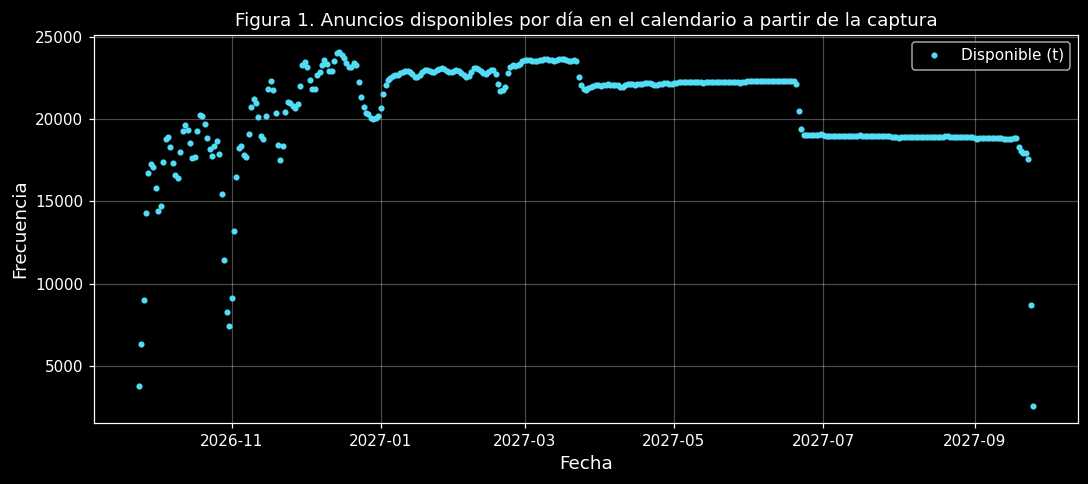

In [ ]:
conteo_t = calendar['available'].eq('t').groupby(calendar['date'],dropna=False).sum()

plt.figure(figsize=(10, 4.5))
plt.plot(conteo_t.index, conteo_t, marker='o', linestyle='', color=COL['cyan'], label='Disponible (t)', markersize=3)

plt.title('Figura 1. Anuncios disponibles por día en el calendario a partir de la captura')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
guardar("fig01_calendario_disponibilidad.png")

Tras entender el contexto de la tabla y observar las salidas, decicimos no incorporar la tabla calendar (~11.1 millones de registros diarios por anuncio entre septiembre de 2026 y septiembre de 2027) en el análisis principal por tres motivos metodológicos y prácticos:

- Dependencia del momento de captura (snapshot): al tratarse de una fotografía estática tomada en una fecha específica, la menor disponibilidad en las fechas más próximas responde en gran medida a reservas ya realizadas o a la cercanía del horizonte, mientras que los saltos o mesetas en meses posteriores reflejan ventanas de apertura configuradas por los anfitriones (p. ej., abrir calendario a 3, 6 o 9 meses). En una captura de otro trimestre, estos patrones cambiarían al desplazarse la ventana de 365 días.

- No mide ocupación real: una fecha marcada como no disponible (f) no distingue entre una noche efectivamente reservada por un huésped y una fecha bloqueada por el anfitrión por uso personal, mantenimiento o baja temporal, por lo que no es un indicador limpio de ocupación.

- Sin aporte directo a la variable de precio: el objetivo central del proyecto es explicar las diferencias en el precio anunciado por noche según ubicación y características del alojamiento y del anfitrión; en este corte, calendar no aporta precios diarios ni variables estructurales adicionales sobre el inmueble.


In [ ]:
del calendar

Seguimos ahora con el contenido de la tabla de`reviews`:

In [ ]:
resenas = pd.read_csv(ruta("reviews"), parse_dates=["date"])

print(f"reviews: {len(resenas):,} renglones")
print(f"Anuncios con al menos una reseña: {resenas['listing_id'].nunique():,}")
print(f"Fechas: del {resenas['date'].min():%d/%m/%Y} al {resenas['date'].max():%d/%m/%Y}")

resumen_resenas = pd.DataFrame({
    "ejemplo": resenas.iloc[0],
    "dtype": resenas.dtypes.astype(str),
    "nulos": resenas.isna().sum(),
    "valores_unicos": resenas.nunique(),
})

display(resumen_resenas)

reviews: 1,795,294 renglones
Anuncios con al menos una reseña: 26,385
Fechas: del 25/02/2011 al 25/09/2026


,ejemplo,dtype,nulos,valores_unicos
listing_id,44616,int64,0,26385
id,706908,int64,0,1795294
date,2011-11-09 00:00:00,datetime64[ns],0,5077
reviewer_id,634733,int64,0,1261384
reviewer_name,Lindsay,object,4,161863
comments,Forget staying in a hotel. Stay at condesa hau...,object,263,1637555


Notemos que la variable `listing_id` es el anuncio al que pertenece la reseña. Es el mismo número que `id` en `listings`, y por eso se repite por lo que un anuncio tiene muchas reseñas.

Para evaluar si la tabla `reviews` aporta información adicional, vamos a agrupar sus registros por
anuncio y los uniremos con `listings` mediante el key del anuncio (`listing_id` =
`id`).

In [ ]:
fecha_corte = pd.to_datetime(listings_raw["last_scraped"]).max()

agg = (resenas.groupby("listing_id")
       .agg(n_resenas=("id", "count"),
            primera=("date", "min"),
            ultima=("date", "max"),
            n_ltm=("date", lambda d: (d > fecha_corte - pd.DateOffset(years=1)).sum()))
       .reset_index())

comp = listings_raw[["id", "number_of_reviews", "number_of_reviews_ltm",
                 "first_review", "last_review"]].merge(
    agg, left_on="id", right_on="listing_id", how="left")

print(agg.shape)
display(agg.head())
print(comp.shape)
display(comp.head())

(26385, 5)


,listing_id,n_resenas,primera,ultima,n_ltm
0,44616,67,2011-11-09,2026-06-15,2
1,56074,84,2011-04-02,2025-02-27,0
2,66055,1,2016-02-25,2016-02-25,0
3,67703,55,2011-11-17,2026-07-04,5
4,70644,150,2012-02-14,2026-09-13,16


(30468, 10)


,id,number_of_reviews,number_of_reviews_ltm,first_review,last_review,listing_id,n_resenas,primera,ultima,n_ltm
0,281134,7,0,2015-01-05,2019-10-05,"281,134.00",7.00,2015-01-05,2019-10-05,0.00
1,35797,0,0,NaN,NaN,NaN,NaN,NaT,NaT,NaN
2,44616,67,2,2011-11-09,2026-06-15,"44,616.00",67.00,2011-11-09,2026-06-15,2.00
3,56074,84,0,2011-04-02,2025-02-27,"56,074.00",84.00,2011-04-02,2025-02-27,0.00
4,66055,1,0,2016-02-25,2016-02-25,"66,055.00",1.00,2016-02-25,2016-02-25,0.00


Antes de comparar, filtramos la tabla para quedarnos solo con los anuncios que tienen al menos una reseña en `reviews`. Los anuncios sin reseñas no tienen valores que contrastar, así que los excluimos de esta verificación (no del análisis). Después contamos, para cada
uno de los cuatro resúmenes (número total de reseñas, reseñas del último año, primera y
última reseña), en cuántos anuncios coincide el valor de `listings` con el que
recalculamos a partir de `reviews`.

In [ ]:
con_resenas = comp["n_resenas"].notna()
c = comp[con_resenas]
total = len(c)

coinc_total = (c['number_of_reviews'] == c['n_resenas']).sum()
coinc_ltm = (c['number_of_reviews_ltm'] == c['n_ltm']).sum()
coinc_primera = (pd.to_datetime(c['first_review']) == c['primera']).sum()
coinc_ultima = (pd.to_datetime(c['last_review']) == c['ultima']).sum()

print(f"Coincide número total de reseñas: {coinc_total:,} de {total:,}")
print(f"Coincide reseñas últimos 12 meses: {coinc_ltm:,} de {total:,}")
print(f"Coincide primera reseña: {coinc_primera:,} de {total:,}")
print(f"Coincide última reseña: {coinc_ultima:,} de {total:,}")

Coincide número total de reseñas: 26,385 de 26,385
Coincide reseñas últimos 12 meses: 24,020 de 26,385
Coincide primera reseña: 26,385 de 26,385
Coincide última reseña: 26,385 de 26,385


Al agregar `reviews` por anuncio y compararlo con `listings`, el número total de reseñas y
las fechas de la primera y última reseña coinciden en los 26,385 anuncios con reseñas, los
4,083 restantes no tienen ninguna reseña, y ambos grupos suman los 30,468 anuncios de
`listings`. Solo las reseñas del último año difieren en algunos casos (coinciden en
24,020), probablemente por la forma en que Inside Airbnb define la ventana de 12 meses.
Es decir, la información cuantitativa de `reviews` ya está resumida en `listings`, y lo
único que agrega es texto libre y datos del reseñador, fuera del alcance de este módulo.
Por ello, trabajaremos únicamente con `listings`.

In [ ]:
del resenas

### 1.3. Diccionario de datos

Tras la revisión de las tablas, y habiendo decidido trabajar únicamente con
`listings`, presentamos a continuación las variables seleccionadas para el análisis.

| Variable | Tipo | Descripción |
|---|---|---|
| `id` | entero | Identificador único del anuncio |
| `host_id` | entero | Identificador del anfitrión |
| `neighbourhood_cleansed` | texto | Alcaldía donde se ubica el anuncio, asignada por Inside Airbnb a partir de sus coordenadas |
| `latitude`, `longitude` | decimal | Coordenadas aproximadas del anuncio (desplazadas hasta ~150 m por privacidad) |
| `property_type` | texto | Tipo de propiedad declarado por el anfitrión (departamento, casa, loft, etc.) |
| `room_type` | texto | Modalidad: alojamiento completo, habitación privada, habitación compartida u habitación de hotel |
| `accommodates` | entero | Número máximo de huéspedes |
| `bedrooms` | decimal | Número de recámaras |
| `beds` | decimal | Número de camas |
| `price` | texto | Precio por noche publicado, en pesos mexicanos |
| `minimum_nights` | decimal | Mínimo de noches por reservación |
| `maximum_nights` | decimal | Máximo de noches por reservación |
| `availability_365` | entero | Días disponibles en los siguientes 365 días |
| `estimated_occupancy_l365d` | entero | Noches ocupadas estimadas en los últimos 12 meses (estimación de Inside Airbnb a partir de las reseñas) |
| `estimated_revenue_l365d` | decimal | Ingreso estimado en los últimos 12 meses, en pesos (precio × ocupación estimada) |
| `number_of_reviews` | entero | Número total de reseñas del anuncio |
| `number_of_reviews_ltm` | entero | Reseñas recibidas en los últimos 12 meses |
| `reviews_per_month` | decimal | Promedio de reseñas por mes desde la primera reseña |
| `first_review` | texto (fecha) | Fecha de la primera reseña |
| `last_review` | texto (fecha) | Fecha de la reseña más reciente |
| `review_scores_rating` | decimal | Calificación general, de 1 a 5 |
| `host_is_superhost` | texto (`t`/`f`) | Indica si el anfitrión tiene la distinción de Superhost |
| `hosts_time_as_host_years` | entero | Años que lleva el usuario como anfitrión en Airbnb |
| `calculated_host_listings_count` | entero | Número de anuncios que tiene el anfitrión en esta captura |
| `source` | texto | Indica si el anuncio se encontró en la captura actual o se tomó de una captura anterior |

### 1.4. Base de Análisis

A partir de esta sección, el análisis se realizará exclusivamente sobre `listings_raw`
restringida a las 26 variables descritas en el diccionario de datos. A esta versión
reducida la llamaremos `listings` y conserva los 30,468 anuncios con sus valores originales,
la tabla completa `listings_raw` permanece intacta por si fuera necesario recuperar alguna
columna. Sobre `listings` aplicaremos las decisiones de limpieza y transformación que se
describen en la siguiente sección.

In [ ]:
listings = listings_raw[COLUMNAS]

display(listings.head())

,id,host_id,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bedrooms,beds,...,number_of_reviews,number_of_reviews_ltm,reviews_per_month,first_review,last_review,review_scores_rating,host_is_superhost,hosts_time_as_host_years,calculated_host_listings_count,source
0,281134,196253,Cuauhtémoc,19.41,-99.18,Room in serviced apartment,Hotel room,3,1.00,2.00,...,7,0,0.05,2015-01-05,2019-10-05,4.71,t,15,10,NaN
1,35797,153786,Cuajimalpa de Morelos,19.38,-99.27,Private room,Private room,2,1.00,1.00,...,0,0,NaN,NaN,NaN,NaN,f,15,1,NaN
2,44616,196253,Cuauhtémoc,19.41,-99.18,Entire home,Entire home/apt,14,5.00,8.00,...,67,2,0.37,2011-11-09,2026-06-15,4.58,t,15,10,NaN
3,56074,265650,Cuauhtémoc,19.44,-99.16,Entire condo,Entire home/apt,2,1.00,1.00,...,84,0,0.45,2011-04-02,2025-02-27,4.87,f,15,1,NaN
4,66055,323211,Coyoacán,19.31,-99.14,Private room in home,Private room,8,4.00,2.00,...,1,0,0.01,2016-02-25,2016-02-25,4.00,f,15,1,NaN


## **2. Exploración y estadística descriptiva**

En esta sección buscamos conocer las variables y detectar posibles problemas:



### 2.1. Tipos de dato

In [ ]:
listings[COLUMNAS].dtypes.to_frame("tipo de dato")

,tipo de dato
id,int64
host_id,int64
neighbourhood_cleansed,object
latitude,float64
longitude,float64
property_type,object
room_type,object
accommodates,int64
bedrooms,float64
beds,float64


Casi todas las variables tienen el tipo esperado. La excepción importante es `price`, que pandas leyó como texto (`str`) por el signo de pesos y las comas; antes de cualquier cálculo tendremos que convertirla a número. También notamos que `minimum_nights`, `bedrooms` y `beds` se leyeron como decimales aunque son conteos.

### 2.2. Variables numéricas

In [ ]:
def describir_numericas(df, excluir=("id", "host_id", "latitude", "longitude")):
    """Estadística descriptiva de las columnas numéricas de df, transpuesta.
    Deja fuera las columnas de `excluir`: son numéricas, pero su media no significa nada."""
    numericas = df.select_dtypes(include="number").columns.drop(list(excluir), errors="ignore")
    return df[numericas].describe().T


describir_numericas(listings)

,count,mean,std,min,25%,50%,75%,max
accommodates,"30,468.00",3.43,2.37,1.00,2.00,3.00,4.00,16.00
bedrooms,"30,444.00",1.53,1.22,0.00,1.00,1.00,2.00,50.00
beds,"30,039.00",2.00,1.80,1.00,1.00,2.00,2.00,50.00
minimum_nights,"30,467.00",2.92,16.03,1.00,1.00,1.00,2.00,600.00
maximum_nights,"30,467.00","634,998.74","36,904,482.44",1.00,365.00,365.00,"1,125.00","2,147,483,647.00"
availability_365,"30,468.00",247.83,119.10,0.00,163.00,296.00,349.00,365.00
estimated_occupancy_l365d,"30,468.00",85.31,88.62,0.00,6.00,54.00,150.00,255.00
estimated_revenue_l365d,"28,360.00","181,745.09","2,779,670.43",0.00,"9,709.25","80,871.00","233,343.75","465,680,793.00"
number_of_reviews,"30,468.00",58.92,95.34,0.00,4.00,22.00,75.00,"1,893.00"
number_of_reviews_ltm,"30,468.00",16.48,25.24,0.00,1.00,8.00,24.00,"1,241.00"


De esta tabla obtenemos varias observaciones:

- La capacidad mediana es de 3 huéspedes y el 75 % de los anuncios admite 4 o menos. Encontramos anuncios con hasta 50 recámaras y 50 camas, que probablemente son hoteles u hostales completos publicados como un solo anuncio.
- En `minimum_nights` la mediana es 1 noche, pero el máximo es 600: algunos anuncios funcionan como renta de mediano o largo plazo.
- El número de reseñas es muy asimétrico: la media es 58.9, la mediana 22 y el máximo 1,893.
- Las calificaciones están concentradas en valores altos: la mediana es 4.84 de 5 y el 75 % de los anuncios tiene 4.70 o más. Esto limita su capacidad para distinguir entre alojamientos.
- La mitad de los anuncios pertenece a anfitriones con 4 anuncios o más, y hay un anfitrión con 187.

### 2.3. Variables categóricas

Usamos una pequeña función para obtener frecuencias absolutas y relativas, incluyendo los valores faltantes.

In [ ]:
def resumen_categoricas(df, excluir=("price", "first_review", "last_review")):
    """Número de categorías, faltantes y valor más frecuente de cada columna de texto."""
    categoricas = (df.select_dtypes(include=["object", "string", "category"]).columns
                     .drop(list(excluir), errors="ignore"))
    filas = {}
    for col in categoricas:
        conteo = df[col].value_counts(dropna=False, normalize=True)
        filas[col] = {
            "categorías": df[col].nunique(),
            "faltantes": df[col].isna().sum(),
            "más frecuente": conteo.index[0],
            "% más frecuente": round(100 * conteo.iloc[0], 1),
        }
    return (pd.DataFrame(filas).T
              .astype({"categorías": int, "faltantes": int})
              .sort_values("categorías"))

resumen_categoricas(listings)

,categorías,faltantes,más frecuente,% más frecuente
source,1,28284,NaN,92.80
host_is_superhost,2,0,f,57.20
room_type,4,0,Entire home/apt,66.80
neighbourhood_cleansed,16,0,Cuauhtémoc,46.50
property_type,86,0,Entire rental unit,41.20


In [ ]:
conteo = listings["neighbourhood_cleansed"].value_counts(dropna=False)
porcentaje = listings["neighbourhood_cleansed"].value_counts(dropna=False, normalize=True) * 100

frecuencias_df = pd.DataFrame({
    "anuncios": conteo,
    "%": porcentaje
})

display(frecuencias_df)

,anuncios,%
neighbourhood_cleansed,,
Cuauhtémoc,14166,46.49
Miguel Hidalgo,4739,15.55
Benito Juárez,3474,11.40
Coyoacán,2209,7.25
Venustiano Carranza,1103,3.62
Tlalpan,1011,3.32
Álvaro Obregón,1000,3.28
Gustavo A. Madero,577,1.89
Iztacalco,577,1.89


Dos de cada tres anuncios (66.8 %) son alojamientos completos y casi un tercio (32.1 %) son habitaciones privadas. La distribución por alcaldía es muy desigual. Cuauhtémoc concentra casi la mitad de la oferta (46.5 %), y junto con Miguel Hidalgo y Benito Juárez suma el 73.4 %. En el otro extremo, Tláhuac y Milpa Alta tienen 46 y 25 anuncios. Las estadísticas de las alcaldías periféricas se calculan entonces con pocos datos y deben leerse con más cautela.

### 2.4. El precio

El precio es la variable central del proyecto, pero vimos que está guardado como texto. Para poder describirlo hacemos una conversión: quitamos el signo de pesos y las comas y convertimos a número, algo que formalizamos más adelante en la **decisión 1**.

In [ ]:
precio_provisional = pd.to_numeric(listings["price"].str.replace(r"[$,]", "", regex=True))
precio_provisional.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

,price
count,"28,360.00"
mean,"2,339.92"
std,"14,094.18"
min,136.80
1%,305.00
25%,942.20
50%,"1,500.00"
75%,"2,326.62"
99%,"13,476.25"
max,"1,826,199.19"


La mediana es de \$1,500 por noche y el 50 % central de los anuncios está entre \$942 y \$2,327; sin embargo, la media es de \$2,340 y la desviación estándar de \$14,094, seis veces la media. Una desviación estándar tan grande indica que hay valores extremadamente alejados del resto, y el máximo lo confirma: \$1,826,199 por noche. Además, solo 28,360 de los 30,468 anuncios tienen precio, así que faltan 2,108.

Revisamos los anuncios más caros y los más baratos:

In [ ]:
VER = ["precio", "property_type", "room_type", "accommodates", "bedrooms", "number_of_reviews"]
listings.assign(precio=precio_provisional).nlargest(8, "precio")[VER]

,precio,property_type,room_type,accommodates,bedrooms,number_of_reviews
4347,"1,826,199.19",Room in boutique hotel,Private room,4,1.00,227
11723,"1,000,300.00",Private room in home,Private room,1,1.00,3
23422,"790,057.15",Entire rental unit,Entire home/apt,2,1.00,0
10688,"500,000.00",Entire home,Entire home/apt,5,2.00,6
8925,"152,220.00",Entire home,Entire home/apt,10,4.00,0
11884,"141,000.00",Entire villa,Entire home/apt,16,6.00,0
7227,"140,653.78",Entire rental unit,Entire home/apt,4,2.00,31
12843,"130,669.33",Entire home,Entire home/apt,16,25.00,0


In [ ]:
listings.assign(precio=precio_provisional).nsmallest(5, "precio")[VER]

,precio,property_type,room_type,accommodates,bedrooms,number_of_reviews
15506,136.80,Private room in rental unit,Private room,2,1.00,0
29775,138.81,Entire cabin,Entire home/apt,6,1.00,0
13113,144.00,Private room in home,Private room,1,1.00,0
13366,158.05,Private room in guesthouse,Private room,1,1.00,7
14457,160.00,Private room in rental unit,Private room,2,1.00,1


Al ver los extremos junto con su descripción notamos que no todos los precios altos son del mismo tipo. Algunos son claramente errores: una "recámara acogedora" para una persona a \$1,000,300 por noche, o una habitación en Roma Norte a \$1,826,199. Otros podrían ser reales: una hacienda o un conjunto de villas para 16 personas a \$130,000 o \$141,000 por noche es caro, pero no imposible. En el extremo inferior pasa algo parecido: una habitación privada a \$137 es plausible, pero un alojamiento completo para 6 personas a \$139 no lo es.

Concluimos que no basta con mirar el precio total; hay que compararlo con el tamaño del alojamiento. Atendemos este problema más adelante.

### 2.5. Análisis Bivariado

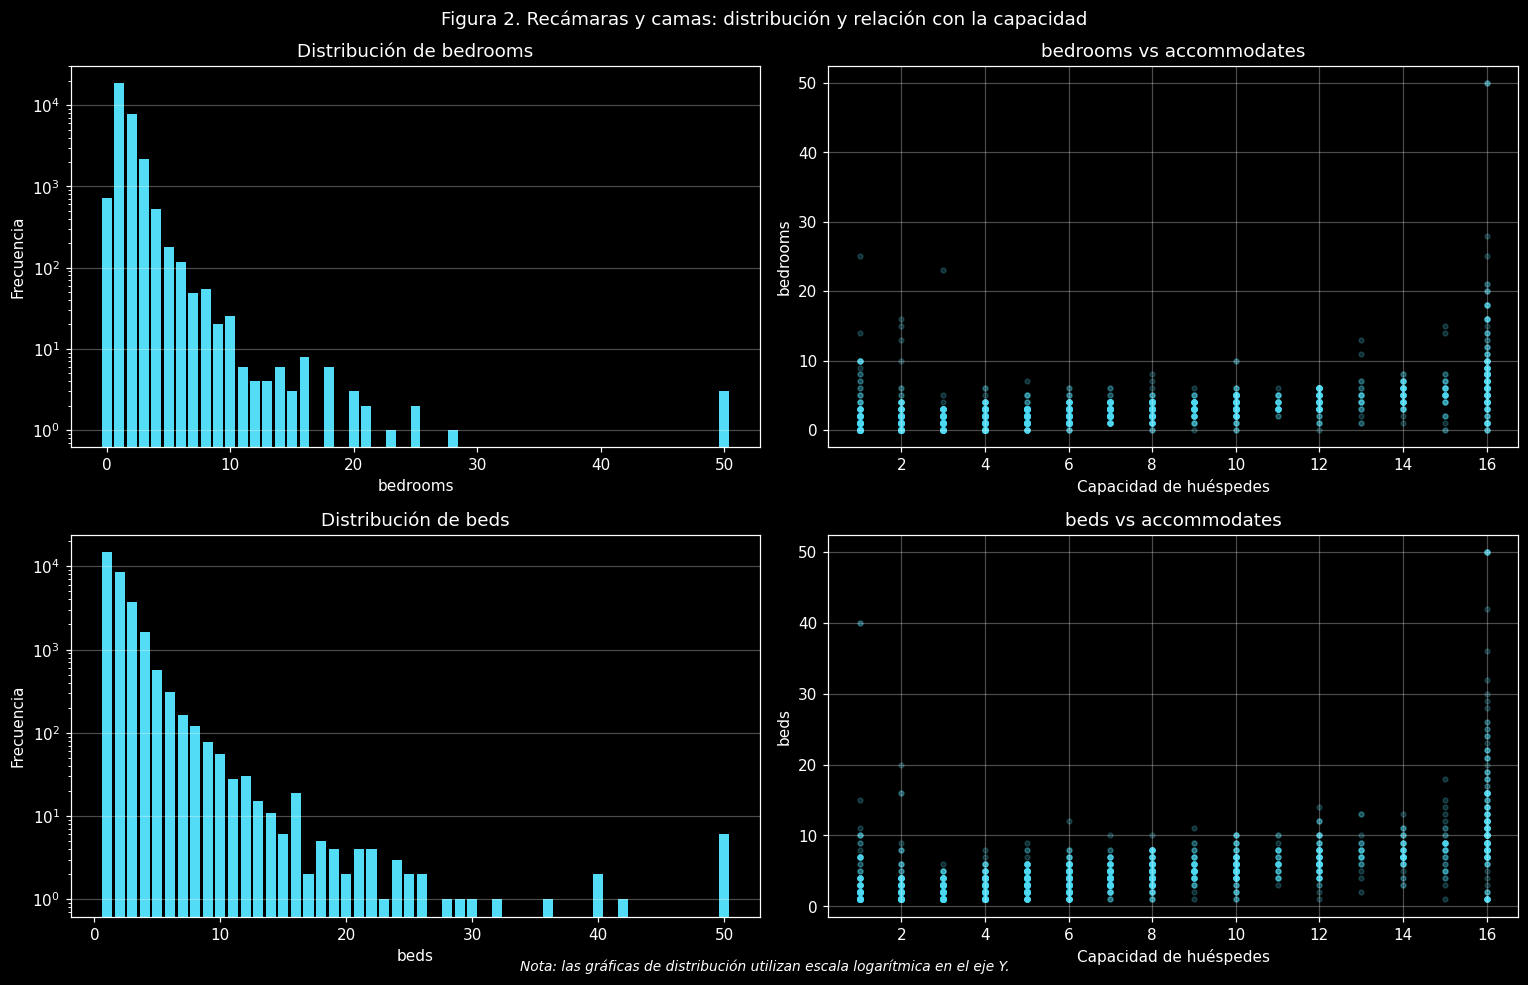


bedrooms: proporción acumulada
bedrooms
0.00    0.02
1.00    0.64
2.00    0.90
3.00    0.97
4.00    0.98
5.00    0.99
6.00    0.99
7.00    1.00
8.00    1.00
9.00    1.00
10.00   1.00
11.00   1.00
12.00   1.00
13.00   1.00
14.00   1.00
15.00   1.00
16.00   1.00
18.00   1.00
20.00   1.00
21.00   1.00
23.00   1.00
25.00   1.00
28.00   1.00
50.00   1.00
Name: proportion, dtype: float64

beds: proporción acumulada
beds
1.00    0.49
2.00    0.77
3.00    0.90
4.00    0.95
5.00    0.97
6.00    0.98
7.00    0.99
8.00    0.99
9.00    0.99
10.00   0.99
11.00   1.00
12.00   1.00
13.00   1.00
14.00   1.00
15.00   1.00
16.00   1.00
17.00   1.00
18.00   1.00
19.00   1.00
20.00   1.00
21.00   1.00
22.00   1.00
23.00   1.00
24.00   1.00
25.00   1.00
26.00   1.00
28.00   1.00
29.00   1.00
30.00   1.00
32.00   1.00
36.00   1.00
40.00   1.00
42.00   1.00
50.00   1.00
Name: proportion, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

# Crear una figura con 2 filas y 2 columnas
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.text(0.5, 0.01, "Nota: las gráficas de distribución utilizan escala logarítmica en el eje Y.",
         ha="center", fontsize=9, style="italic")

for i, col in enumerate(["bedrooms", "beds"]):

    # 1. Distribución: frecuencia de cada valor
    conteo = listings[col].value_counts().sort_index()

    axes[i, 0].bar(conteo.index, conteo.values, color=COL['cyan'])
    axes[i, 0].set_yscale("log")
    axes[i, 0].set_title(f"Distribución de {col}")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frecuencia" )
    axes[i, 0].grid(axis="y", alpha=0.3)

    # 2. Relación con la capacidad del alojamiento
    axes[i, 1].scatter(
        listings["accommodates"],
        listings[col],
        alpha=0.2,
        s=10,
        color=COL['cyan']
    )
    axes[i, 1].set_title(f"{col} vs accommodates")
    axes[i, 1].set_xlabel("Capacidad de huéspedes")
    axes[i, 1].set_ylabel(col)
    axes[i, 1].grid(alpha=0.3)

fig.suptitle("Figura 2. Recámaras y camas: distribución y relación con la capacidad")
plt.tight_layout()
guardar("fig02_recamaras_camas.png")


# Tabla de apoyo: proporción acumulada por valor
for col in ["bedrooms", "beds"]:

    tabla = (
        listings[col]
        .value_counts(normalize=True)
        .sort_index()
        .cumsum()
        .round(4)
    )

    print(f"\n{col}: proporción acumulada")
    print(tabla)

Las gráficas muestran que tanto el número de habitaciones **(bedrooms)** como el número de camas (beds) presentan una distribución concentrada en valores pequeños, con una clara asimetría hacia la derecha. Esto indica que predominan los alojamientos de dimensiones reducidas, tanto por el número de habitaciones como por la cantidad de camas disponibles.

En cuanto a la relación con la capacidad de huéspedes **(accommodates)**, los diagramas de dispersión permiten observar una tendencia positiva: conforme aumenta la capacidad del alojamiento, también tiende a incrementarse el número de habitaciones y camas. Sin embargo, esta relación no es estrictamente proporcional, ya que existen alojamientos con la misma capacidad que presentan cantidades distintas de habitaciones y camas. Esto sugiere que la capacidad para recibir huéspedes no depende exclusivamente de estas dos características, sino que puede variar según la distribución y configuración de cada espacio.

## **3. Calidad, limpieza y transformación**

La exploración nos dejó tres problemas que afectan directamente al precio: está guardado como texto, le faltan datos a una parte de los anuncios y hay valores que no son creíbles. Antes de atenderlos revisamos duplicados y faltantes en general. Para cada decisión documentamos el problema, lo que hicimos y la consecuencia sobre los datos.

### 3.1. Duplicados y llaves

In [ ]:
print("Anuncios con id repetido:", listings["id"].duplicated().sum())
print("Renglones idénticos en listings:", listings.duplicated().sum())

Anuncios con id repetido: 0
Renglones idénticos en listings: 0


No encontramos identificadores repetidos ni renglones duplicados en ninguno de los dos archivos, y todas las reseñas corresponden a anuncios que sí están en `listings`. Por lo tanto, no es necesario eliminar registros por duplicación y podemos tratar cada renglón de `listings` como un anuncio distinto.

### 3.2. Valores faltantes

In [ ]:
def diagnosticar_faltantes(df, columnas, umbral_pocos=5, umbral_mayoria=50):
    """Cuenta los faltantes de cada columna y propone qué hacer con ellos."""
    tabla = df[columnas].isna().sum().to_frame("faltantes")
    tabla["%"] = (100 * tabla["faltantes"] / len(df)).round(1)

    def diagnostico(variable, n, pct):
        if variable == "source":
            return "No es faltante: vacío significa que el anuncio es de la captura actual"
        if n == 0:
            return "Completa: no requiere tratamiento"
        if pct == 100:
            return "Columna vacía: se descarta"
        if pct >= umbral_mayoria:
            return "Faltan la mayoría: revisar si el vacío significa algo antes de descartarla"
        if pct < umbral_pocos:
            return "Pocos faltantes: se conservan y se excluyen solo en los cálculos que usan la variable"
        return "Revisar si los faltantes se concentran en algún grupo antes de decidir"

    tabla["diagnóstico"] = [
        diagnostico(v, n, p) for v, n, p in zip(tabla.index, tabla["faltantes"], tabla["%"])
    ]
    return tabla


diagnosticar_faltantes(listings, COLUMNAS)

,faltantes,%,diagnóstico
id,0,0.00,Completa: no requiere tratamiento
host_id,0,0.00,Completa: no requiere tratamiento
neighbourhood_cleansed,0,0.00,Completa: no requiere tratamiento
latitude,0,0.00,Completa: no requiere tratamiento
longitude,0,0.00,Completa: no requiere tratamiento
property_type,0,0.00,Completa: no requiere tratamiento
room_type,0,0.00,Completa: no requiere tratamiento
accommodates,0,0.00,Completa: no requiere tratamiento
bedrooms,24,0.10,Pocos faltantes: se conservan y se excluyen so...
beds,429,1.40,Pocos faltantes: se conservan y se excluyen so...


Los faltantes de `bedrooms` (24 anuncios, 0.1 %), `beds` (429, 1.4 %), `minimum_nights` y `maximum_nights` (1 anuncio, el mismo en ambas) representan menos del 5 % de los registros, umbral que usamos como referencia para considerarlos poco relevantes. Por eso los conservamos y cada cálculo usa los anuncios que tienen la variable.

La columna `source` aparece vacía en el 92.8 % de los anuncios, pero no se trata de un faltante. Según la documentación de Inside Airbnb, el valor vacío indica que el anuncio se encontró al recorrer la ciudad en esta captura, y `previous scrape` indica que se recuperó de una captura anterior. El vacío tiene, entonces, un significado, y más adelante usamos esta variable para separar los dos grupos.

Las demás variables con faltantes superan el umbral y forman tres grupos: el precio (`price`), el ingreso estimado (`estimated_revenue_l365d`) y las variables de reseñas (`review_scores_rating`, `reviews_per_month`, `first_review` y `last_review`). Las revisamos en la **decisión 2**.

### **3.3. Decisión 1: convertir el precio a número**

**Problema.** `price` está guardado como texto con signo de pesos y separador de miles (`$3,505.00`), así que no se pueden calcular medias, medianas ni gráficas.

**Qué hicimos.** Quitamos el signo `$` y las comas y convertimos a número. Después verificamos que ningún texto se haya quedado sin convertir y que no haya precios iguales o menores a cero.

In [ ]:
def precio_a_numero(texto):
    """Convierte '$3,505.00' en 3505.0. Los valores vacíos quedan como NaN."""
    return pd.to_numeric(texto.str.replace(r"[$,]", "", regex=True), errors="coerce")


listings["precio"] = precio_a_numero(listings["price"])
no_convertidos = listings["price"].notna() & listings["precio"].isna()
print("Textos que no se pudieron convertir:", no_convertidos.sum())
print("Precios menores o iguales a cero:", (listings["precio"] <= 0).sum())
print("Precios faltantes:", listings["precio"].isna().sum())

Textos que no se pudieron convertir: 0
Precios menores o iguales a cero: 0
Precios faltantes: 2108


/tmp/ipykernel_4405/147723675.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  listings["precio"] = precio_a_numero(listings["price"])


**Consecuencia.** Todos los textos se convirtieron correctamente y no hay precios iguales o menores a cero. Los únicos valores sin precio son los 2,108 que ya venían vacíos en el archivo.

### 3.4. Reglas de consistencia

Además de revisar faltantes y duplicados, verificamos que los valores respeten reglas que deben cumplirse por definición: rangos posibles (días del año, escala de calificación), relaciones entre columnas (las reseñas del último año no pueden ser más que las totales) y la forma en que Inside Airbnb construye algunas variables (el ingreso estimado es el precio por la ocupación estimada). Para las fechas usamos `last_scraped`, porque Inside Airbnb recorrió la ciudad entre el 24 y el 26 de septiembre de 2026.

In [ ]:
fecha_scrape = pd.to_datetime(listings_raw["last_scraped"])
primera = pd.to_datetime(listings["first_review"])
ultima = pd.to_datetime(listings["last_review"])
anuncios_del_host = listings.groupby("host_id")["id"].transform("size")

validaciones = {
    "Precio menor o igual a 0": listings["precio"] <= 0,
    "Capacidad menor a 1 huésped": listings["accommodates"] < 1,
    "Disponibilidad fuera de 0 a 365 días": ~listings["availability_365"].between(0, 365),
    "Ocupación estimada fuera de 0 a 365 noches": ~listings["estimated_occupancy_l365d"].between(0, 365),
    "Calificación fuera de 1 a 5": listings["review_scores_rating"].notna()
                                   & ~listings["review_scores_rating"].between(1, 5),
    "Reseñas del último año mayores que las totales":
        listings["number_of_reviews_ltm"] > listings["number_of_reviews"],
    "Noches mínimas mayores que las máximas": listings["minimum_nights"] > listings["maximum_nights"],
    "Primera reseña posterior a la última": primera > ultima,
    "Última reseña posterior a la captura": ultima > fecha_scrape,
    "Ingreso distinto de precio × ocupación":
        (listings["precio"] * listings["estimated_occupancy_l365d"]
         - listings["estimated_revenue_l365d"]).abs() > 1,
    "Anuncios del anfitrión distintos del conteo por host_id":
        listings["calculated_host_listings_count"] != anuncios_del_host,
    "Más recámaras que huéspedes": listings["bedrooms"] > listings["accommodates"],
}
pd.Series({regla: int(marca.sum()) for regla, marca in validaciones.items()}).to_frame("anuncios que no cumplen")

,anuncios que no cumplen
Precio menor o igual a 0,0
Capacidad menor a 1 huésped,0
Disponibilidad fuera de 0 a 365 días,0
Ocupación estimada fuera de 0 a 365 noches,0
Calificación fuera de 1 a 5,0
Reseñas del último año mayores que las totales,0
Noches mínimas mayores que las máximas,0
Primera reseña posterior a la última,0
Última reseña posterior a la captura,0
Ingreso distinto de precio × ocupación,0


Todas las reglas se cumplen, salvo una: 178 anuncios declaran más recámaras que huéspedes. No lo tratamos como un error, porque puede ser legítimo: un anfitrión puede limitar el número de huéspedes en una casa con recámaras de sobra. La coherencia entre recámaras y camas la revisamos en la **decisión 6**.

Que las demás reglas den cero también es un resultado. Confirma que los rangos, las fechas y las variables que calcula Inside Airbnb son consistentes; en particular, el ingreso estimado es exactamente el precio por la ocupación estimada, y el número de anuncios por anfitrión coincide con el que contamos nosotros.

### 3.5. Valores atípicos

In [ ]:
## Variables
# Variables cuantitativas
variables_continuas = [
    'latitude',
    'longitude',
    'precio',
    'estimated_occupancy_l365d',
    'estimated_revenue_l365d',
    'reviews_per_month',
    'review_scores_rating',
    'hosts_time_as_host_years',
]

variables_discretas = [
    'accommodates',
    'bedrooms',
    'beds',
    'minimum_nights',
    'maximum_nights',
    'availability_365',
    'number_of_reviews',
    'number_of_reviews_ltm',
    'calculated_host_listings_count',
]

# Variables cualitativas
variables_ordinales = [
    # No se identifican variables ordinales en este conjunto.
]

variables_nominales = [
    'neighbourhood_cleansed',
    'property_type',
    'room_type',
    'host_is_superhost',
    'source',
]

# Concatenación por tipo de variable
variables_cuantitativas = variables_continuas + variables_discretas

variables_cualitativas = variables_ordinales + variables_nominales

# Identificadores
variables_identificadores = [
    'id',
    'host_id',
]

# Variables temporales
variables_temporales = [
    'first_review',
    'last_review',
]

#### 3.5.1. Variables cuantitativas

In [ ]:
def analizar_outliers(df, variables, factor_iqr=1.5, umbral_z=3):
    """
    Resumen compacto de outliers con IQR y Z-score.

    Retorna
    -------
    resumen : DataFrame con una fila por variable.
    observaciones : dict con las observaciones marcadas (conservan el índice original).
    """

    invalidas = [v for v in variables if v not in df.columns]
    if invalidas:
        raise ValueError(f"Columnas inexistentes: {invalidas}")

    no_numericas = [
        v for v in variables
        if not pd.api.types.is_numeric_dtype(df[v])
    ]
    if no_numericas:
        raise TypeError(f"Variables no numéricas: {no_numericas}")

    resultados = []
    observaciones = {}

    for variable in variables:

        datos = df[variable].replace([np.inf, -np.inf], np.nan).dropna()

        if datos.empty:
            continue

        n = len(datos)

        # IQR
        q1, q3 = datos.quantile(0.25), datos.quantile(0.75)
        iqr = q3 - q1
        lim_inf = q1 - factor_iqr * iqr
        lim_sup = q3 + factor_iqr * iqr
        marca_iqr = (datos < lim_inf) | (datos > lim_sup)

        # Z-score
        desv = datos.std()
        if desv > 0:
            z = (datos - datos.mean()) / desv
            marca_z = z.abs() > umbral_z
        else:
            marca_z = pd.Series(False, index=datos.index)

        ambos = marca_iqr & marca_z

        resultados.append({
            "variable": variable,
            "n_nulos": len(df) - n,
            "min": datos.min(),
            "p99": datos.quantile(0.99),
            "max": datos.max(),
            "lim_inf_IQR": lim_inf,
            "lim_sup_IQR": lim_sup,
            "%IQR": marca_iqr.mean() * 100,
            "%Z": marca_z.mean() * 100,
            "%ambos": ambos.mean() * 100,
        })

        observaciones[variable] = {
            "IQR": datos[marca_iqr],
            "Z": datos[marca_z],
            "Ambos": datos[ambos],
        }

    resumen = pd.DataFrame(resultados).set_index("variable")
    return resumen.round(2), observaciones

In [ ]:
def visualizar_boxplots(df, variables, percentil=(1, 99)):
  '''Visualiza diagramas de caja para las variables numéricas.'''

    # Validar columnas
    invalidas = [v for v in variables if v not in df.columns]

    if invalidas:
        raise ValueError(f"Columnas inexistentes: {invalidas}")

    # Validar tipos de datos
    no_numericas = [
        v for v in variables
        if not pd.api.types.is_numeric_dtype(df[v])
    ]

    if no_numericas:
        raise TypeError(f"Variables no numéricas: {no_numericas}")

    if not variables:
        raise ValueError("Debes proporcionar al menos una variable.")

    # Validar percentiles
    if not (0 <= percentil[0] < percentil[1] <= 100):
        raise ValueError("Los percentiles deben estar entre 0 y 100.")

    # Configurar distribución de gráficos
    n = len(variables)
    columnas = min(n, 3)
    filas = math.ceil(n / columnas)

    fig, axes = plt.subplots(
        filas, columnas,
        figsize=(5 * columnas, 4 * filas),
        squeeze=False
    )

    # Generar boxplots
    for ax, variable in zip(axes.flat, variables):

        datos = df[variable].dropna()

        if datos.empty:
            ax.set_title(f"{variable}\nSin datos válidos")
            ax.axis("off")
            continue

        # Límites de visualización
        limite_inf = datos.quantile(percentil[0] / 100)
        limite_sup = datos.quantile(percentil[1] / 100)

        bp = ax.boxplot(
            datos,
            patch_artist=True,
            showmeans=True
        )
        for caja in bp["boxes"]:
            caja.set_facecolor(COL["azul"])

        ax.set_ylim(limite_inf, limite_sup)
        ax.set_title(variable)
        ax.set_ylabel("Valor")
        ax.set_xticks([])
        ax.grid(axis="y", alpha=0.3)

    # Ocultar espacios sobrantes
    for ax in axes.flat[n:]:
        ax.axis("off")

    fig.suptitle("Diagramas de caja de variables numéricas", fontsize=14)

    plt.tight_layout()
    plt.show()

##### 3.5.1.1. Variables cuantitativas continuas

In [ ]:
display(
    analizar_outliers(
        df=listings,
        variables=variables_cuantitativas,
    )[0]
)

,n_nulos,min,p99,max,lim_inf_IQR,lim_sup_IQR,%IQR,%Z,%ambos
variable,,,,,,,,,
latitude,0,19.17,19.49,19.55,19.33,19.49,7.75,1.25,1.25
longitude,0,-99.35,-99.06,-98.97,-99.22,-99.11,10.63,2.39,2.39
precio,2108,136.80,"13,476.25","1,826,199.19","-1,134.44","4,403.27",7.42,0.16,0.16
estimated_occupancy_l365d,0,0.00,255.00,255.00,-210.00,366.00,0.00,0.00,0.00
estimated_revenue_l365d,2108,0.00,"1,050,422.59","465,680,793.00","-325,742.50","568,795.50",5.08,0.01,0.01
reviews_per_month,4083,0.01,9.20,107.56,-2.76,6.12,3.68,1.18,1.18
review_scores_rating,4083,1.00,5.00,5.00,4.32,5.32,5.92,1.67,1.67
hosts_time_as_host_years,0,0.00,13.00,15.00,-7.00,17.00,0.00,0.00,0.00
accommodates,0,1.00,15.00,16.00,-1.00,7.00,5.29,2.03,2.03


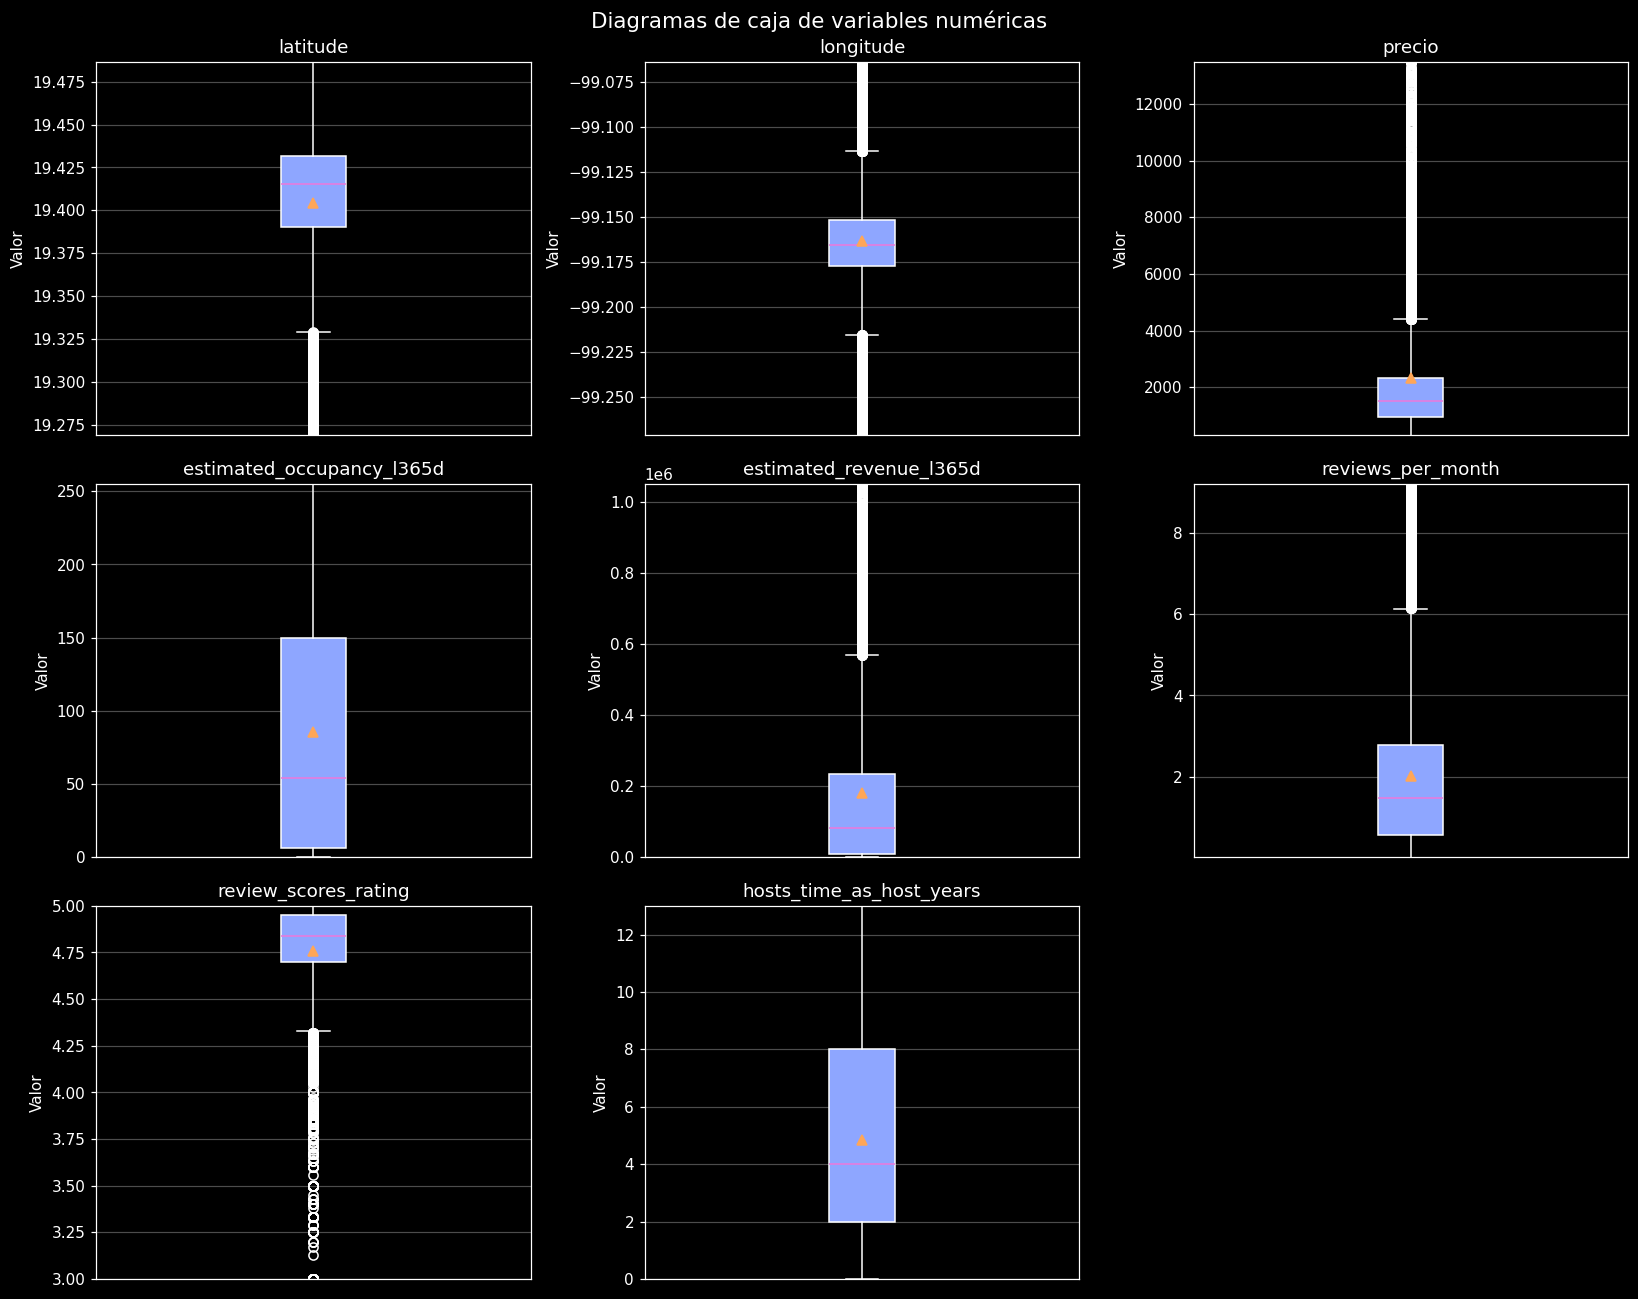

In [ ]:
visualizar_boxplots(listings, variables_continuas)

##### 3.5.1.2. Variables cuantitativas discretas


In [ ]:

def visualizar_discretas(df, variables, top_n=10):
  '''Visualiza diagramas de barras para las variables discretas.'''

    # Validar columnas
    invalidas = [v for v in variables if v not in df.columns]

    if invalidas:
        raise ValueError(f"Columnas inexistentes: {invalidas}")

    if top_n is not None and top_n < 1:
        raise ValueError("top_n debe ser un entero positivo o None.")

    n = len(variables)

    if n == 0:
        raise ValueError("Debe proporcionarse al menos una variable.")

    columnas = min(n, 2)
    filas = math.ceil(n / columnas)

    fig, axes = plt.subplots(
        filas, columnas,
        figsize=(7 * columnas, 4 * filas),
        squeeze=False
    )

    for ax, variable in zip(axes.flat, variables):

        datos = df[variable].dropna()

        if datos.empty:
            ax.set_title(f"{variable}: sin datos")
            ax.axis("off")
            continue

        # Calcular frecuencias completas
        frecuencias = datos.value_counts()

        # Seleccionar las categorías más frecuentes
        if top_n is not None and len(frecuencias) > top_n:

            principales = frecuencias.nlargest(top_n)

            # Agrupar las categorías restantes
            otros = frecuencias.sum() - principales.sum()

            frecuencias = principales.sort_index()

            frecuencias.loc["Otros"] = otros

        else:
            frecuencias = frecuencias.sort_index()

        # Calcular porcentajes sobre el total válido
        porcentajes = frecuencias / len(datos) * 100

        # Preparar etiquetas del eje X
        etiquetas = [
            f"{x:g}" if isinstance(x, (int, float)) else str(x)
            for x in frecuencias.index
        ]

        # Graficar barras
        posiciones = range(len(frecuencias))

        barras = ax.bar(
            posiciones,
            porcentajes
        )

        # Agregar porcentajes sobre las barras
        ax.bar_label(
            barras,
            labels=[f"{p:.1f}%" for p in porcentajes],
            padding=3,
            fontsize=8
        )

        ax.set_xticks(posiciones)
        ax.set_xticklabels(etiquetas, rotation=45, ha="right")

        ax.set_title(variable)
        ax.set_xlabel("Valor")
        ax.set_ylabel("Frecuencia (%)")

        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)
        ax.margins(y=0.15)

    # Ocultar espacios vacíos
    for ax in axes.flat[n:]:
        ax.axis("off")

    fig.suptitle(
        "Distribución de variables cuantitativas discretas",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


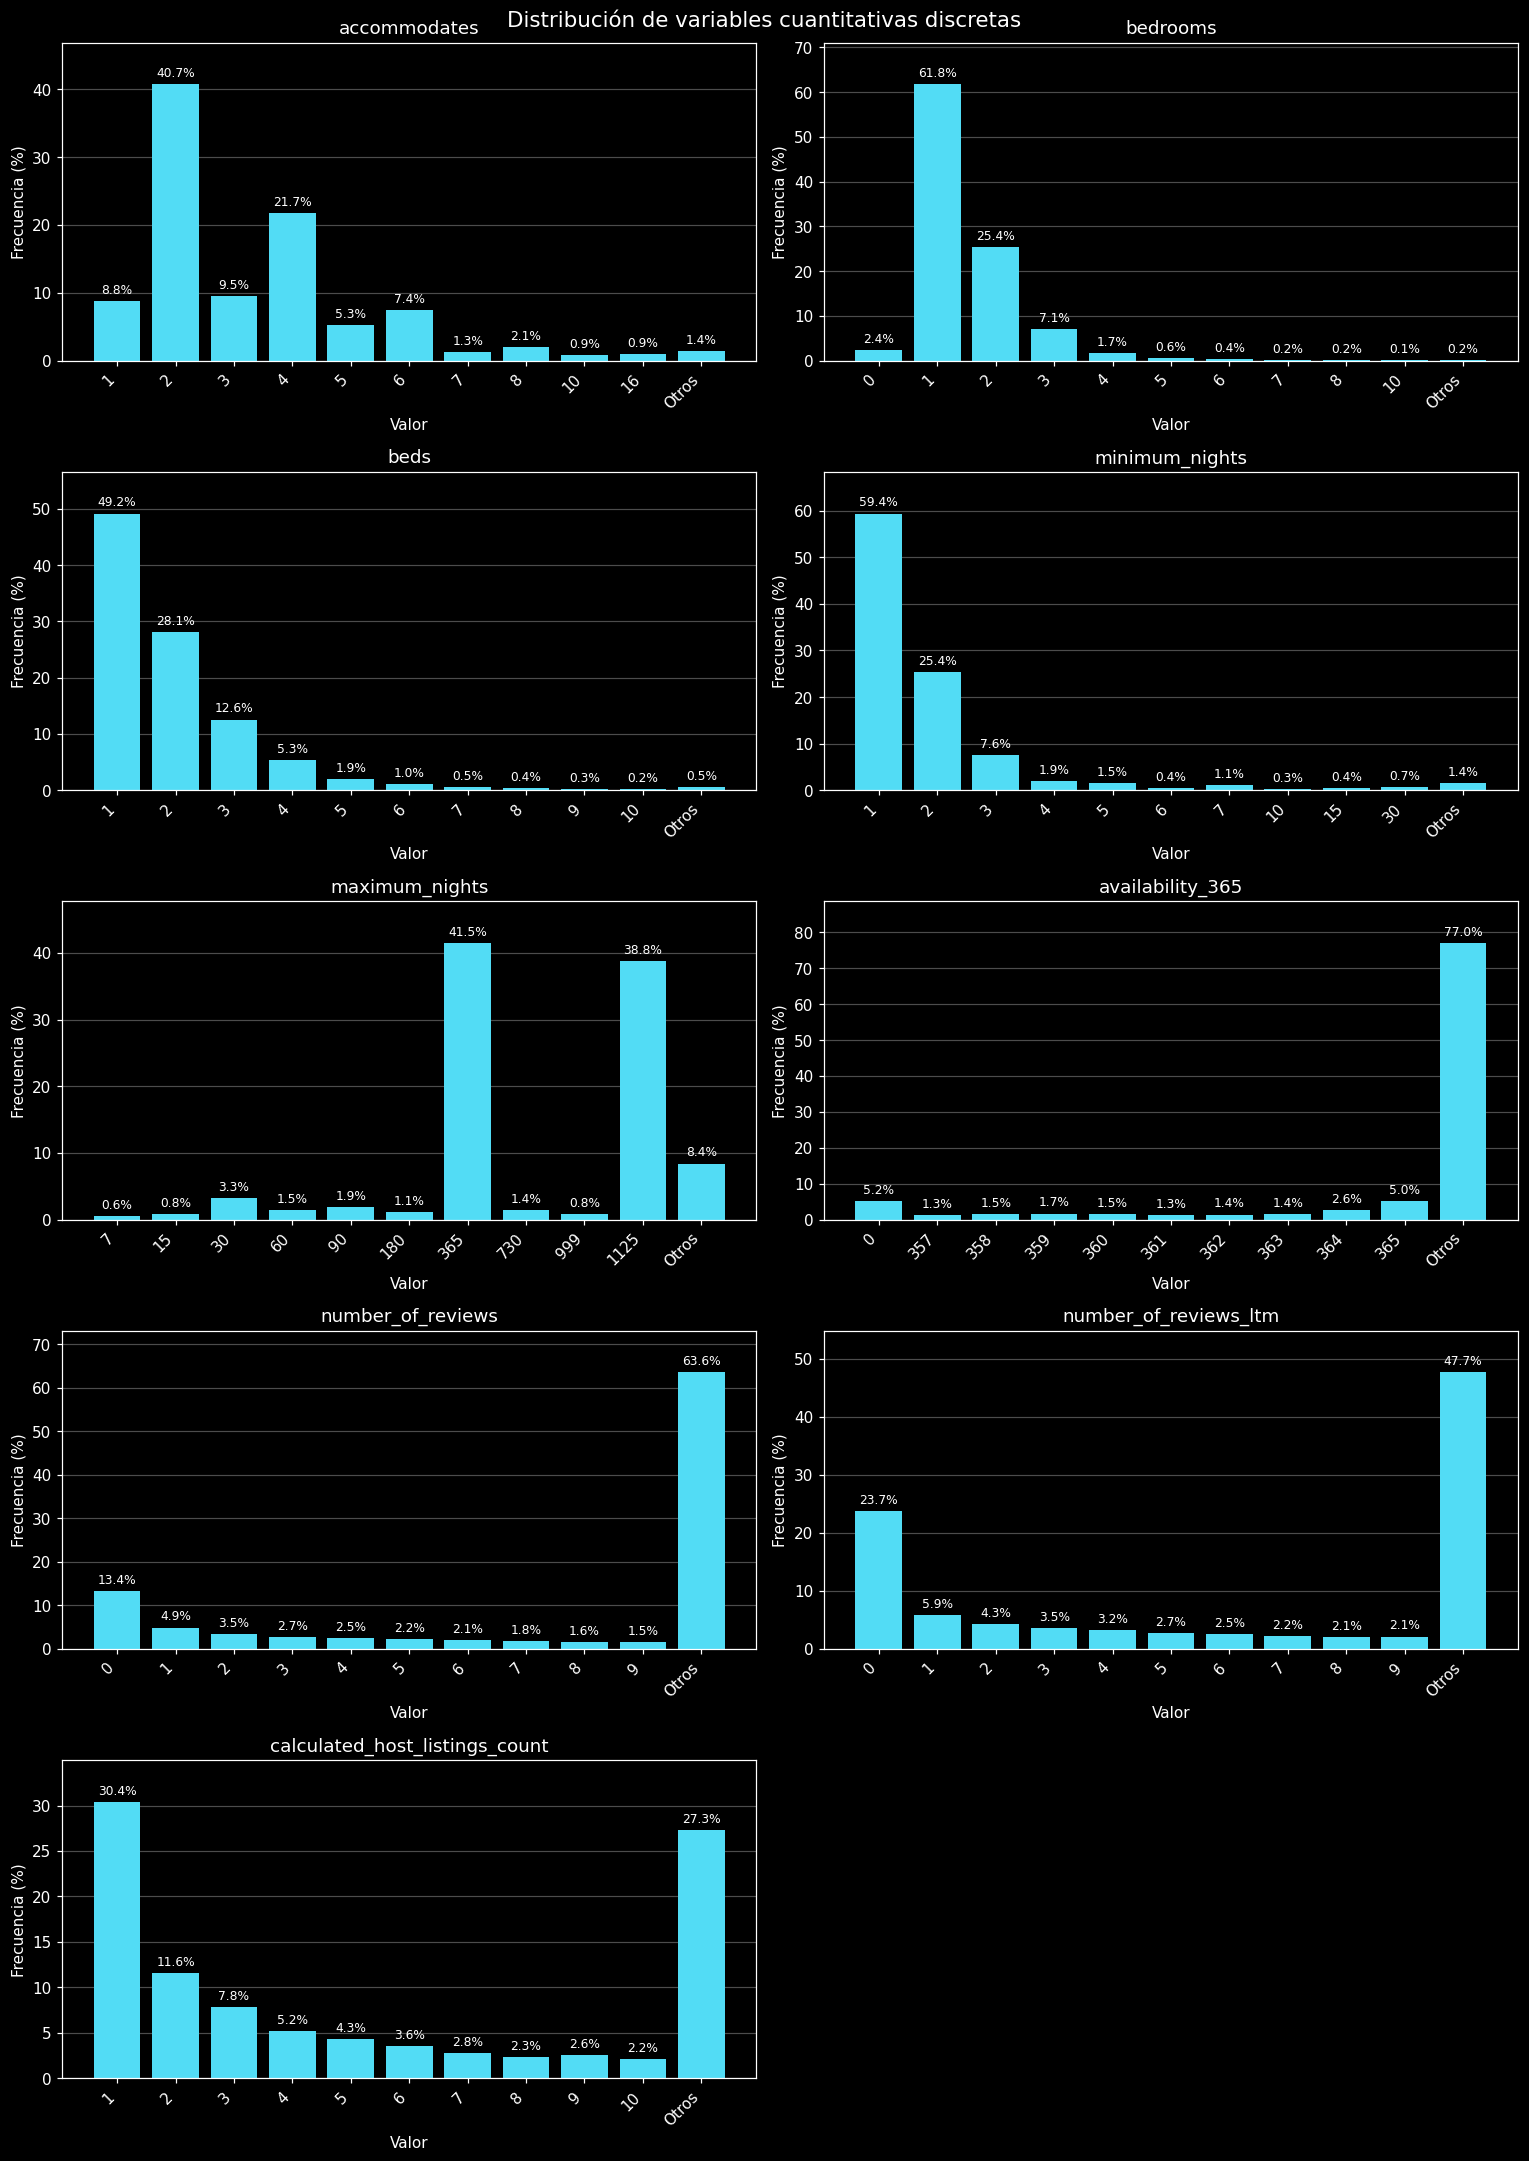

In [ ]:
visualizar_discretas(listings, variables_discretas)

#### Interpretación de resultados

**Observación general:** `%ambos` es idéntico a `%Z` en todas las variables, es decir, todo lo que marca el Z-score ya lo marcaba el IQR. La señal útil es la brecha entre `%IQR` y `%Z`: una brecha grande indica que el IQR sobre-detecta, sobre todo en variables discretas concentradas en pocos valores, donde el IQR es muy pequeño y los límites quedan demasiado estrechos.

#### 1. Variables con valores erróneos o inverosímiles

El `max` está muy por encima del `p99`, por lo que se requieren reglas de dominio y no solo IQR.

| Variable | min | max | Diagnóstico |
|---|---|---|---|
| `maximum_nights` | 1 | 2,147,483,647 | Es 2³¹-1, el máximo de un entero de 32 bits (valor centinela) |
| `precio` | 136.80 | 1,826,199 | Error de captura casi seguro en la cola superior |
| `estimated_revenue_l365d` | 0 | 465,680,793 | Derivada de `precio`, hereda el error |
| `bedrooms` | 0 | 50 | 50 es sospechoso (posible valor por defecto) |
| `beds` | 1 | 50 | Igual que `bedrooms` |

### 2. Variables donde el IQR sobre-detecta (cola natural)

`max` cercano a `p99`: no hay extremos aislados, solo una cola larga legítima.

- **`accommodates`** (p99 = 15, max = 16): casas grandes, se conservan.
- **`calculated_host_listings_count`** (p99 = 181, max = 187): hosts profesionales o inmobiliarias, no son un error.
- ** `minimum_nights`:** `%IQR` alto ( 7.6%) frente a `%Z` bajo ( 0.47%). El límite superior de 3.5 es demasiado estrecho y cortaría valores normales (4 o 5 camas, 7 noches).
- **`number_of_reviews`:** cola larga típica de anuncios populares. Conviene transformación logarítmica en lugar de eliminar.

### 3. Variables sin problema aparente

`estimated_occupancy_l365d`, `hosts_time_as_host_years` y `availability_365` tienen 0% de outliers en ambos métodos y rangos coherentes (0-365 días, 0-15 años).

### 4. Variables donde el IQR no es la prueba adecuada

- **`latitude` y `longitude`:** el 7.75% y 10.63% marcado corresponde a zonas periféricas de una ciudad extensa y asimétrica, no a errores. Sus valores mínimo y máximo están dentro de la CDMX con latitude de 19.17 a 19.55 y longitude -99.35 a -98.97. De acuerdo con los datos geográficos oficiales de la entidad, el territorio de la Ciudad de México se extiende entre los **`19.048333` a `19.592778` en grados decimales de latitud norte** , y entre los **`-99.365000` a `-98.940278` en grados decimales de longitud oeste**. Vamos a dejar los valores como están.
- **`minimum_nights`: El mínimo es 1 noceh lo cual es consistente. Probablemente hayan huespedes que tengan una estancia muy corta.

*Fuente: [INEGI - Aspectos geográficos de la Ciudad de México](https://inegi.org.mx).*

- **`review_scores_rating`:** variable acotada (máximo 5) con sesgo hacia valores altos. No vamos a manejarlo como algo realmente raro.



#### Variables categóricas

El análisis se centra en dos problemas de calidad de datos:

* **Categorías de baja frecuencia.** Niveles que representan una proporción mínima de los registros (por defecto, menos del 1%). Su presencia no implica necesariamente un error, pero produce estimaciones poco confiables y puede afectar el desempeño de los modelos. Su identificación permite decidir si conviene agruparlas en una categoría común (“Otros”) o conservarlas por su relevancia.
* **Variantes de escritura.** Una misma categoría registrada de formas distintas, por diferencias de mayúsculas, minúsculas o espacios. Este error de captura incrementa artificialmente el número de niveles y fragmenta la información de una categoría en varias.

In [ ]:
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", None)

def revision_categorias(df, cols, umbral=0.01):
    """Por columna: niveles, % nulos, categorías raras y variantes de escritura."""
    filas = []
    for c in cols:
        s = df[c].dropna().astype(str)
        freq = s.value_counts(normalize=True)
        variantes = s.groupby(s.str.strip().str.lower()).nunique()
        filas.append({"variable": c,
                      "niveles": s.nunique(), #niveles: número de categorías distintas, excluyendo valores nulos.
                      "nulos_%": round(df[c].isna().mean() * 100, 2),
                      "raras": list(freq[freq < umbral].index),
                      "variantes": list(variantes[variantes > 1].index)})
    return pd.DataFrame(filas)

In [ ]:
revision_categorias(listings, variables_nominales)

,variable,niveles,nulos_%,raras,variantes
0,neighbourhood_cleansed,16,0.00,"[Xochimilco, La Magdalena Contreras, Tláhuac, Milpa Alta]",[]
1,property_type,86,0.00,"[Private room in serviced apartment, Private room in bed and breakfast, Entire guest suite, Private room in casa particular, Room in boutique hotel, Room in aparthotel, Private room in loft, Entire guesthouse, Tiny home, Private room in hostel, Shipping container, Shared room in guesthouse, Shared room in home, Entire townhouse, Shared room in hostel, Entire cabin, Private room in townhouse, Shared room in rental unit, Private room, Casa particular, Private room in tiny home, Entire vacation home, Private room in vacation home, Shared room in hotel, Room in serviced apartment, Private room in cabin, Entire place, Entire villa, Entire cottage, Private room in hut, Private room in dome, Shared room in bed and breakfast, Shared room in casa particular, Holiday park, Camper/RV, Private room in villa, Hut, Room in bed and breakfast, Shared room in condo, Dome, Private room in nature lodge, Tent, Private room in tent, Shared room in boutique hotel, Private room in tower, Private room in yurt, Private room in earthen home, Private room in shipping container, Campsite, Shared room in townhouse, Private room in farm stay, Entire hostel, Entire chalet, Tower, Private room in resort, Private room in castle, Entire home/apt, Room in casa particular, Cave, Private room in cottage, Shared room in tiny home, Castle, Private room in barn, Entire in-law, Private room in lighthouse, Room in hostel, Private room in pension, Private room in minsu, Private room in houseboat, Ranch, Boat, Shared room in barn, Shared room in serviced apartment, Entire bungalow, Treehouse]",[]
2,room_type,4,0.00,"[Shared room, Hotel room]",[]
3,host_is_superhost,2,0.00,[],[]
4,source,1,92.83,[],[]


In [ ]:
def visualizar_nominales(df, variables, top_n=15, mostrar_otras=True,
                         rellenar_na=("source",), columnas=2):
    """
    Barras horizontales con el % de cada categoría por variable.
    Los porcentajes se calculan sobre los registros no nulos
    (o incluyendo 'Sin información' en las variables de `rellenar_na`).
    """
    # Validar columnas
    invalidas = [v for v in variables if v not in df.columns]
    if invalidas:
        raise ValueError(f"Columnas inexistentes: {invalidas}")

    # Validar tipos categóricos
    no_categoricas = [
        v for v in variables
        if not (pd.api.types.is_object_dtype(df[v]) or
                pd.api.types.is_string_dtype(df[v]) or
                isinstance(df[v].dtype, pd.CategoricalDtype) or
                pd.api.types.is_bool_dtype(df[v]))
    ]
    if no_categoricas:
        raise TypeError(f"Variables no categóricas: {no_categoricas}")

    # Datos por variable
    datos_var = {}
    for v in variables:
        if v in rellenar_na:
            datos_var[v] = df[v].astype("object").fillna("Sin información")
        else:
            datos_var[v] = df[v].dropna()

    # Layout: la altura de cada fila depende de la variable con más barras
    n = len(variables)
    columnas = min(n, columnas)
    filas = math.ceil(n / columnas)
    barras_max = max(min(top_n, s.nunique()) + int(mostrar_otras)
                     for s in datos_var.values() if not s.empty)
    alto_fila = 1.5 + 0.35 * barras_max

    fig, axes = plt.subplots(filas, columnas,
                             figsize=(7 * columnas, alto_fila * filas),
                             squeeze=False)

    for ax, (variable, datos) in zip(axes.flat, datos_var.items()):
        if datos.empty:
            ax.set_title(f"{variable}: sin datos")
            ax.axis("off")
            continue

        vc = datos.value_counts()
        total = vc.sum()
        frecuencias = vc.head(top_n)

        # Barra que agrupa lo que queda fuera del top_n
        if mostrar_otras and len(vc) > top_n:
            resto = vc.iloc[top_n:]
            frecuencias = pd.concat(
                [frecuencias, pd.Series({f"Otras ({len(resto)})": resto.sum()})])

        porcentajes = frecuencias / total * 100

        barras = ax.barh(frecuencias.index.astype(str), porcentajes, color=COL["azul"])
        ax.invert_yaxis()  # la más frecuente arriba
        ax.bar_label(barras, labels=[f"{p:.1f}%" for p in porcentajes],
                     padding=3, fontsize=9)

        ax.margins(x=0.15)  # espacio para que no se corten las etiquetas
        ax.set_title(f"{variable}  ({datos.nunique()} niveles)")
        ax.set_xlabel("Frecuencia (%)")
        ax.grid(axis="x", alpha=0.3)
        ax.set_axisbelow(True)

    # Ocultar espacios vacíos
    for ax in axes.flat[n:]:
        ax.axis("off")

    fig.suptitle("Distribución de variables categóricas nominales", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

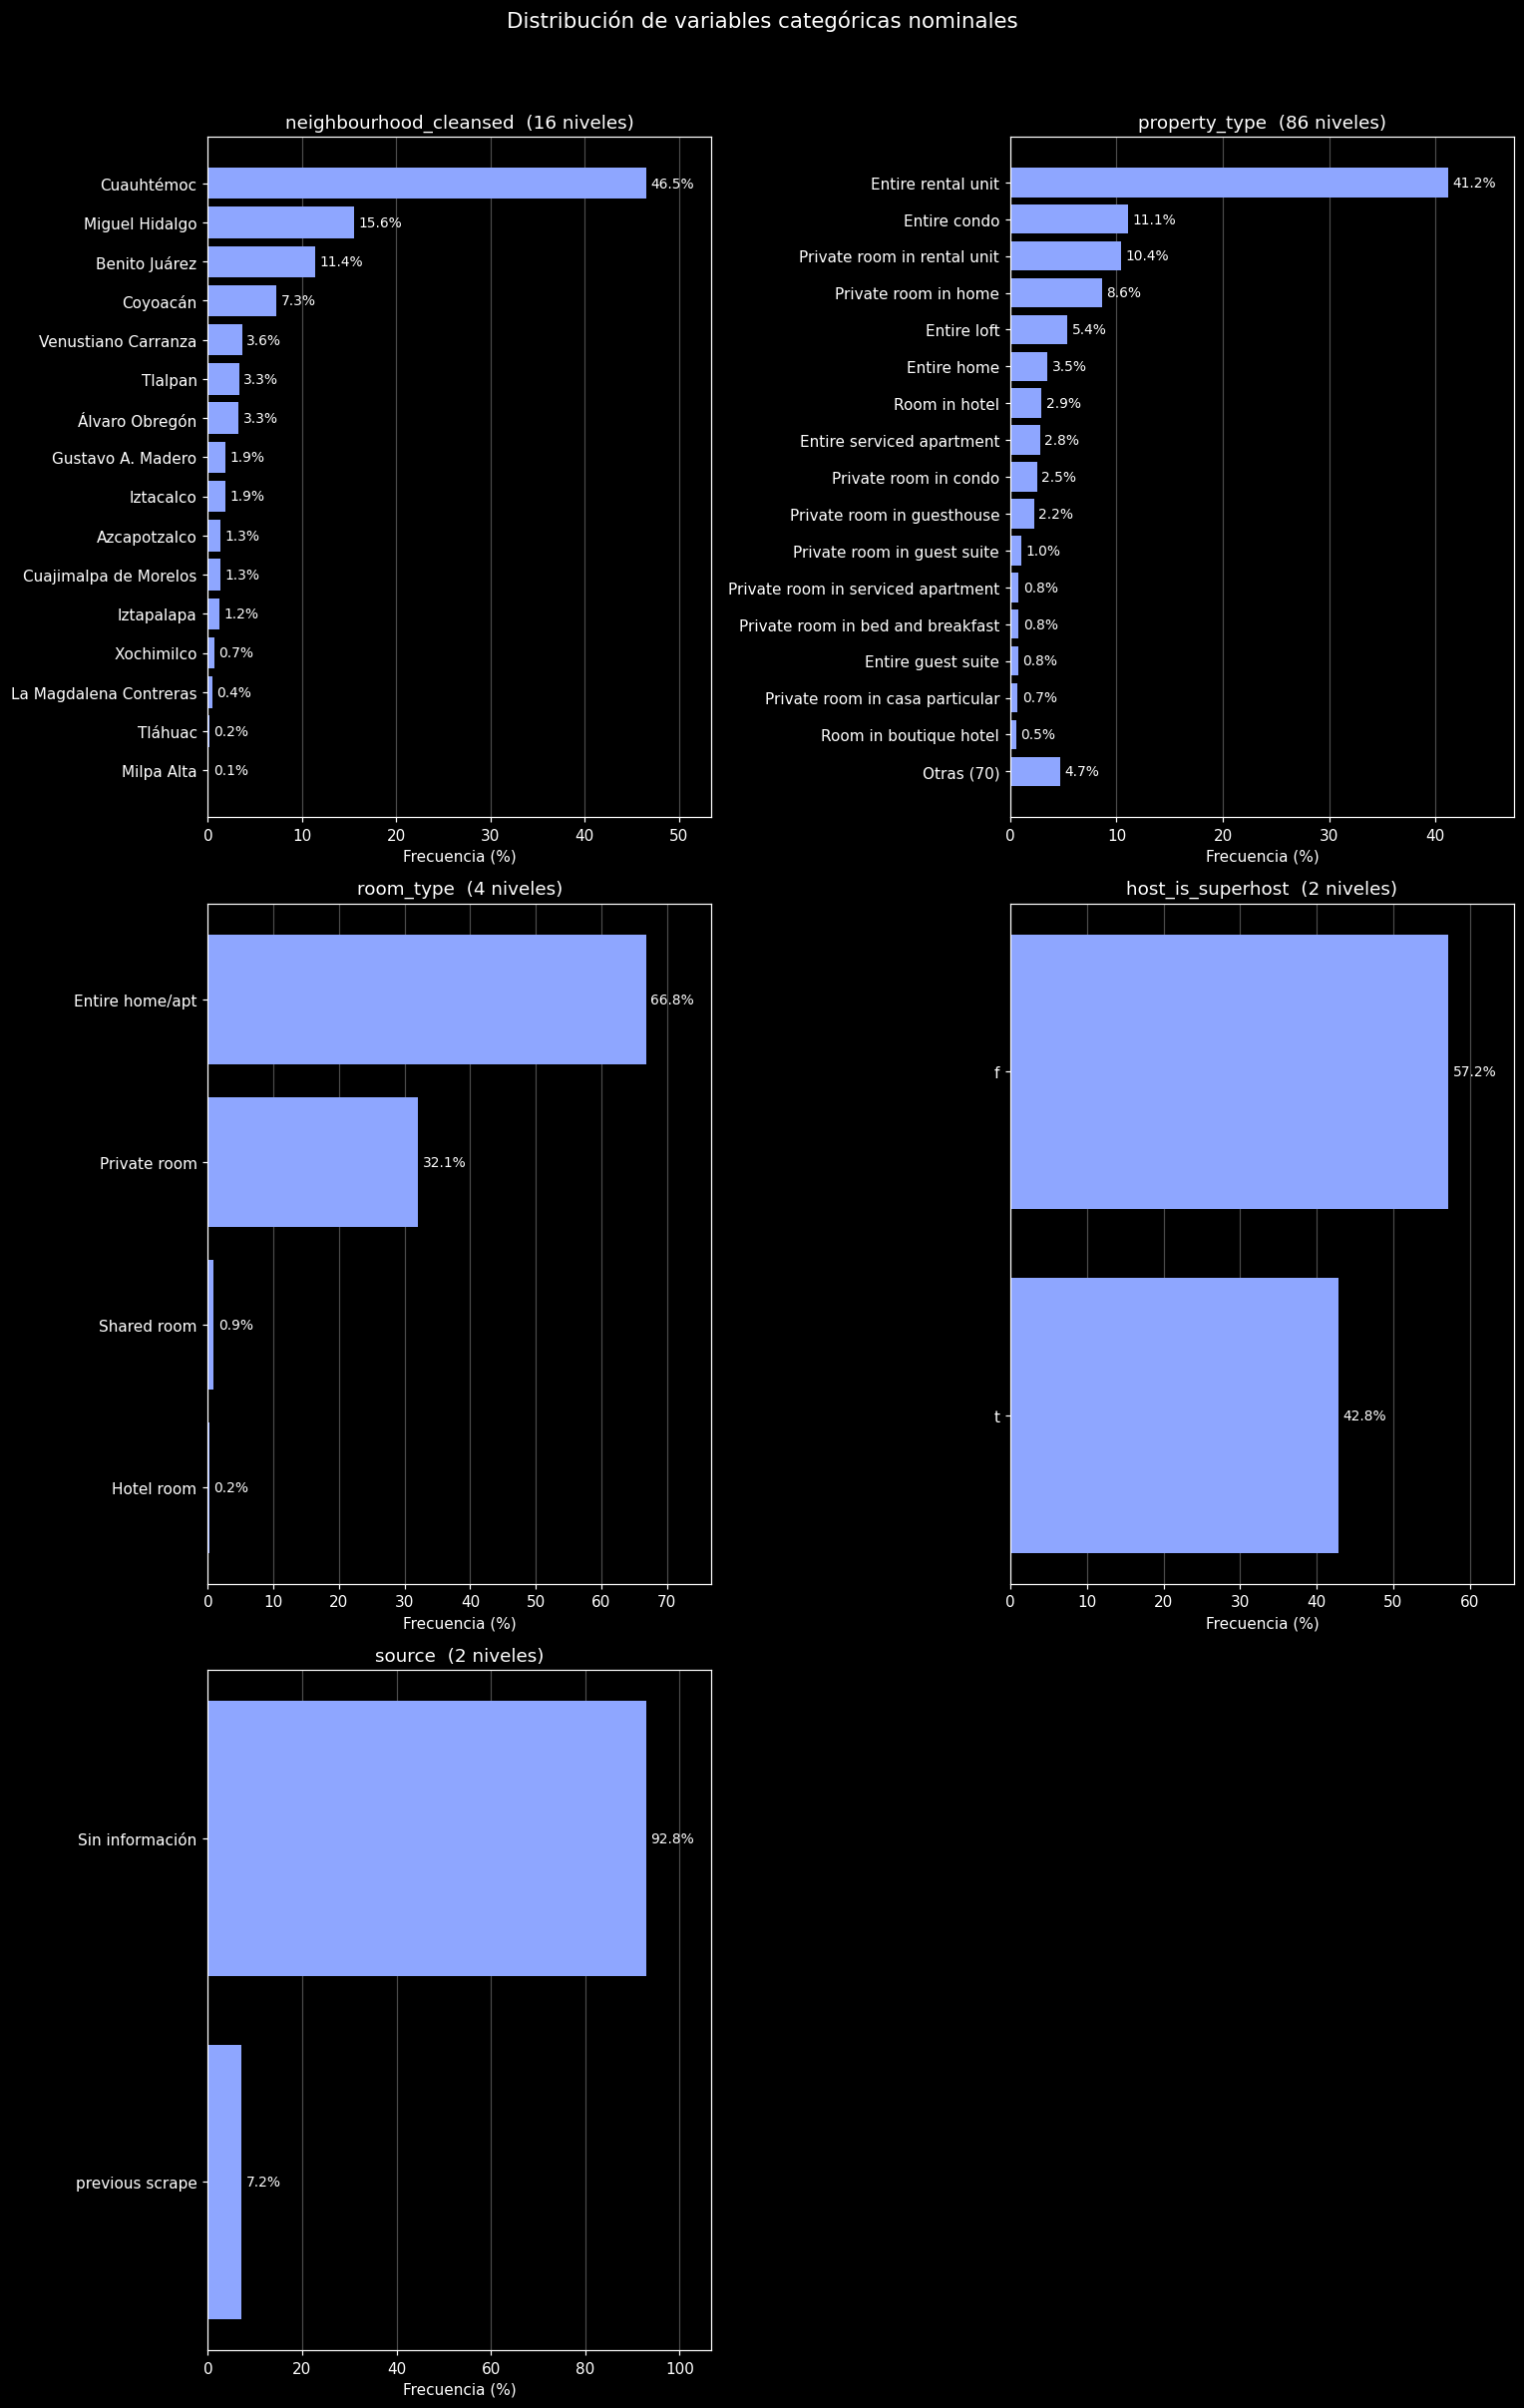

In [ ]:
visualizar_nominales(
    listings,
    variables_nominales,
    top_n=16,
    mostrar_otras=True,
    rellenar_na=("source",),
    columnas=2
)

#### Interpretación de los resultados

Tres variables se conservan sin cambios porque no presentan problemas de calidad. En neighbourhood_cleansed, los 16 niveles corresponden a las alcaldías de CDMX, sin nulos ni variantes de escritura. Las cuatro categorías de baja frecuencia (Xochimilco, La Magdalena Contreras, Tláhuac y Milpa Alta) son alcaldías reales con poca oferta, no errores. En room_type hay solo cuatro niveles, y aunque Shared room (0.9%) y Hotel room (0.2%) son poco frecuentes, son legítimos, y agruparlos haría perder información. Por último, host_is_superhost es una variable binaria (t/f) con una distribución de 42.8% contra 57.2% y sin nulos, por lo que solo requiere convertirse a booleano para el modelado.

En las tres, la baja frecuencia refleja cómo es el mercado y no un problema de datos. Al comparar precios o ingresos por alcaldía, conviene exigir un mínimo de registros por grupo para que las estadísticas de las alcaldías pequeñas sean confiables.

property_type tiene 86 niveles. Según los porcentajes de la gráfica, los que más datos acumulan se reparten así:
rental unit por sí sola concentra el 41.2%.
Los 3 más frecuentes (Entire rental unit, Entire condo y Private room in rental unit) suman cerca de 62.7% de los registros.
Los 5 más frecuentes suman cerca de 76.7%.
Los 11 niveles que superan el 1% suman cerca de 91.6%.
Los otros 75 niveles, todos bajo el 1%, suman solo cerca de 8.4%.

La variable mezcla dos conceptos. Combina el tipo de espacio (Entire, Private room, Shared room, Room in) con el tipo de inmueble (rental unit, condo, home, loft...). Por eso existen “Entire condo”, “Private room in condo” y “Shared room in condo” como niveles separados, y la cantidad de categorías se multiplica de forma artificial.

Etiquetas genéricas o redundantes. Entre las raras aparecen “Private room”, “Entire place”, “Casa particular” (aparte de “Private room in casa particular”) y “Entire home/apt”, que en realidad es un valor de room_type.

En cuanto a source nos sirve para distringuir el 7.2% de previous scrape, que hacer referencia a que el registro no es actual. Se nqueda igual ya que nos sirve de control.



### **3.6. Decisión 2: tratar los faltantes del precio, el ingreso estimado y las reseñas según su origen**

**Problema.** Tres grupos de variables tienen faltantes por encima del 5%: el precio (2,108 anuncios, 6.9%), el ingreso estimado (2,108, 6.9%) y las cuatro variables de reseñas (4,083, 13.4%). Antes de decidir qué hacer con ellos revisamos si se reparten al azar o si se concentran en algún grupo de anuncios. Para eso comparamos los anuncios con y sin dato en otras variables. Si los faltantes fueran al azar, los dos grupos deberían parecerse.

**Precio:**

In [ ]:
def comparar_faltantes(df, variable, otras):
    """Compara los anuncios con y sin dato en `variable`.
    Para variables booleanas reporta el porcentaje; para las numéricas, la mediana."""
    grupo = pd.Series(np.where(df[variable].isna(), "sin dato", "con dato"),
                      index=df.index, name=variable)
    resumen = {"anuncios": grupo.value_counts()}
    for col in otras:
        if df[col].dtype == bool:
            resumen[f"% {col}"] = 100 * df[col].groupby(grupo).mean()
        else:
            resumen[f"mediana {col}"] = df[col].groupby(grupo).median()
    return pd.DataFrame(resumen).round(1)


listings["captura_anterior"] = listings["source"].eq("previous scrape")
OTRAS = ["captura_anterior", "accommodates", "number_of_reviews",
         "number_of_reviews_ltm", "availability_365"]

comparar_faltantes(listings, "price", OTRAS)

/tmp/ipykernel_4405/2803789463.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  listings["captura_anterior"] = listings["source"].eq("previous scrape")


,anuncios,% captura_anterior,mediana accommodates,mediana number_of_reviews,mediana number_of_reviews_ltm,mediana availability_365
price,,,,,,
con dato,28360,1.60,3.00,23.00,9.00,306.00
sin dato,2108,82.00,2.00,8.00,0.00,0.00


Encontramos que los dos grupos son muy distintos. El 82% de los anuncios sin precio proviene de una captura anterior, contra 1.6% de los que sí tienen precio. **Además, los anuncios sin precio tienen una mediana de 0 reseñas en los últimos 12 meses y de 0 días disponibles en el próximo año**: en la práctica no están recibiendo huéspedes. **El faltante del precio no es al azar, sino que depende de si el anuncio sigue activo.** Imputarlo con la mediana le asignaría el precio típico de un anuncio activo a anuncios que ya no operan. Ahora comparamos los anuncios según su origen:


In [ ]:
listings["origen"] = listings["source"].fillna("captura actual")
listings.groupby("origen").agg(
    anuncios=("id", "size"),
    pct_sin_precio=("precio", lambda s: 100 * s.isna().mean()),
    mediana_dias_disponibles=("availability_365", "median"),
    mediana_resenas_12m=("number_of_reviews_ltm", "median"),
)

/tmp/ipykernel_4405/1482602750.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  listings["origen"] = listings["source"].fillna("captura actual")


,anuncios,pct_sin_precio,mediana_dias_disponibles,mediana_resenas_12m
origen,,,,
captura actual,28284,1.34,308.00,9.00
previous scrape,2184,79.12,0.00,0.00


Encontramos que los faltantes de `price` no se reparten al azar. Entre los 28,284 anuncios de la captura actual solo el 1.3% no tiene precio, mientras que entre los 2,184 anuncios recuperados de capturas anteriores el porcentaje sube a 79.1%.

**Ingreso estimado.** Inside Airbnb calcula esta variable como el precio por la ocupación estimada, así que esperamos que le falte el dato a los mismos anuncios que no tienen precio. Lo comprobamos:

In [ ]:
print("Anuncios a los que les falta el ingreso:", listings["estimated_revenue_l365d"].isna().sum())
print("¿Faltan exactamente en los mismos anuncios que el precio?",
      listings["estimated_revenue_l365d"].isna().equals(listings["price"].isna()))

Anuncios a los que les falta el ingreso: 2108
¿Faltan exactamente en los mismos anuncios que el precio? True


Los 2,108 faltantes coinciden uno a uno con los del precio: el ingreso no puede calcularse si no hay precio. Por lo tanto, su faltante tiene el mismo origen y recibe el mismo tratamiento.

**Reseñas.** Hacemos la misma comparación para la calificación:

In [ ]:
comparar_faltantes(listings, "review_scores_rating", OTRAS)

,anuncios,% captura_anterior,mediana accommodates,mediana number_of_reviews,mediana number_of_reviews_ltm,mediana availability_365
review_scores_rating,,,,,,
con dato,26385,6.90,3.00,31.00,12.00,289.00
sin dato,4083,9.00,2.00,0.00,0.00,345.00


Aquí la proporción de anuncios de captura anterior es parecida en los dos grupos (9.0 % contra 6.9 %). La diferencia está en las reseñas: los anuncios sin calificación tienen una mediana de 0 reseñas, contra 31 de los que sí la tienen. Como las otras tres variables de reseñas tienen exactamente el mismo número de faltantes, revisamos las cuatro a la vez contra los anuncios que no tienen ninguna reseña:

In [ ]:
sin_resenas = listings["number_of_reviews"].eq(0)
RESENAS = ["review_scores_rating", "reviews_per_month", "first_review", "last_review"]

pd.DataFrame({
    col: {
        "faltantes": listings[col].isna().sum(),
        "en anuncios sin reseñas": (listings[col].isna() & sin_resenas).sum(),
        "en anuncios con reseñas": (listings[col].isna() & ~sin_resenas).sum(),
    }
    for col in RESENAS
}).T

,faltantes,en anuncios sin reseñas,en anuncios con reseñas
review_scores_rating,4083,4083,0
reviews_per_month,4083,4083,0
first_review,4083,4083,0
last_review,4083,4083,0


La coincidencia es exacta: los 4,083 faltantes de cada variable corresponden justamente a los anuncios sin reseñas, y ningún anuncio con reseñas tiene un faltante en estas variables. Es un faltante estructural: un anuncio sin reseñas no tiene calificación, ni fecha de primera o última reseña, ni un promedio de reseñas por mes.

**Qué hicimos.** Tratamos cada grupo según el origen de sus faltantes:

- **Precio (`price`).** Restringimos el análisis a los anuncios de la captura actual, que son los que representan la oferta activa de la ciudad. Entre ellos eliminamos los 380 que no tienen precio (1.3 %). La mayoría son anuncios nuevos, con una mediana de 0 reseñas. Como el precio es nuestra variable de estudio, estos anuncios no aportan a nuestras preguntas. No los imputamos, porque completar un precio con la mediana inventaría un dato justo en la variable que queremos estudiar y reduciría artificialmente su dispersión.
- **Ingreso estimado (`estimated_revenue_l365d`).** No requiere un tratamiento propio: al eliminar los anuncios sin precio desaparecen también todos sus faltantes.
- **Reseñas (`review_scores_rating`, `reviews_per_month`, `first_review` y `last_review`).** Conservamos los anuncios y dejamos estas variables como faltantes. Imputarlas, por ejemplo la calificación con la mediana de 4.84, equivaldría a inventar una opinión que ningún huésped dio. Cuando usamos alguna de estas variables, trabajamos solo con los anuncios que la tienen.

In [ ]:
vigentes = listings[listings["origen"] == "captura actual"].copy()
con_precio = vigentes.dropna(subset=["precio"]).copy()
print(f"Anuncios de la captura actual: {len(vigentes):,}")
print(f"De ellos, sin precio: {vigentes['precio'].isna().sum():,}")
print(f"Anuncios con precio: {len(con_precio):,}")

Anuncios de la captura actual: 28,284
De ellos, sin precio: 380
Anuncios con precio: 27,904


**Consecuencia.** Pasamos de 30,468 a 27,904 anuncios, es decir, conservamos el 91.6 %. Con esta decisión desaparecen todos los faltantes del precio y del ingreso estimado. También queda fuera la habitación de \$1,826,199 que vimos en la exploración, porque provenía de una captura anterior. De los 27,904 anuncios, 3,512 (12.6 %) siguen sin reseñas. Los conservamos, porque su precio sí es válido, y solo quedan fuera de los cálculos que usan variables de reseñas, como la correlación entre la calificación y el precio en la sección 4. La contraparte es que nuestras conclusiones se refieren a la oferta activa, no a todos los anuncios que alguna vez se publicaron.

### **3.7. Decisión 3: excluir precios que no son creíbles**

En la exploración encontramos precios imposibles, como una habitación para una persona a un millón de pesos por noche, junto con precios muy bajos para alojamientos grandes. Un precio alto no es por sí mismo un error: en la ciudad hay departamentos de lujo y casas para 16 personas. Lo que buscamos son precios que no tienen sentido para el tamaño del alojamiento.

Asi que en lugar del precio total usamos el **precio por huésped**, es decir, el precio dividido entre la capacidad máxima, para comparar alojamientos de distinto tamaño. Como los precios son muy asimétricos, trabajamos con su logaritmo base 10 y aplicamos la regla de Tukey: calculamos el primer cuartil $Q_1$, el tercer cuartil $Q_3$ y el rango intercuartílico $IQR = Q_3 - Q_1$, y marcamos como no creíbles los valores fuera del intervalo

$$[\,Q_1 - 3\cdot IQR,\; Q_3 + 3\cdot IQR\,].$$

La regla usual para detectar atípicos usa $1.5\cdot IQR$; con $3\cdot IQR$ solo marcamos los valores extremadamente alejados del resto, para no eliminar alojamientos caros pero reales.

In [ ]:
con_precio["precio_huesped"] = con_precio["precio"] / con_precio["accommodates"]
log_ph = np.log10(con_precio["precio_huesped"])
q1, q3 = log_ph.quantile([0.25, 0.75])
ric = q3 - q1
limite_inf, limite_sup = 10 ** (q1 - 3 * ric), 10 ** (q3 + 3 * ric)

muy_bajo = con_precio["precio_huesped"] < limite_inf
muy_alto = con_precio["precio_huesped"] > limite_sup
print(f"Mediana del precio por huésped: ${con_precio['precio_huesped'].median():,.0f}")
print(f"Intervalo aceptado: de ${limite_inf:,.0f} a ${limite_sup:,.0f} por huésped por noche")
print(f"Anuncios por debajo: {muy_bajo.sum()}   Anuncios por encima: {muy_alto.sum()}")

Mediana del precio por huésped: $516
Intervalo aceptado: de $36 a $7,557 por huésped por noche
Anuncios por debajo: 19   Anuncios por encima: 65


In [ ]:
excluidos = con_precio[muy_bajo | muy_alto].sort_values("precio_huesped", ascending=False)
pd.concat([excluidos.head(6), excluidos.tail(3)])[
    ["precio", "precio_huesped", "property_type", "room_type", "accommodates"]]

,precio,precio_huesped,property_type,room_type,accommodates
11723,"1,000,300.00","1,000,300.00",Private room in home,Private room,1
23422,"790,057.15","395,028.58",Entire rental unit,Entire home/apt,2
10688,"500,000.00","100,000.00",Entire home,Entire home/apt,5
4784,"105,383.00","52,691.50",Entire rental unit,Entire home/apt,2
4531,"90,116.67","45,058.33",Entire rental unit,Entire home/apt,2
30345,"76,487.50","38,243.75",Entire rental unit,Entire home/apt,2
29775,138.81,23.14,Entire cabin,Entire home/apt,6
12202,289.73,22.29,Private room in guesthouse,Private room,13
29442,252.00,21.00,Private room in tent,Private room,12


La mediana del precio por huésped es de \$516 por noche, y el intervalo aceptado va de \$36 a \$7,557 por huésped. Quedan fuera 84 anuncios: 65 por encima y 19 por debajo.

En la tabla aparecen los casos más extremos de cada lado. Arriba están la recámara para una persona a un millón de pesos y departamentos para dos personas a más de \$76,000 por noche. Abajo aparecen, por ejemplo, una residencia y una terraza que declaran capacidad para 12 o 13 personas con precios de \$250 a \$290. En estos últimos casos el error probablemente está en la capacidad y no en el precio, pero en ambos casos el precio por huésped no es confiable y preferimos no usarlos.

In [ ]:
analisis = con_precio[~(muy_bajo | muy_alto)].copy()
pd.DataFrame({
    "antes": con_precio["precio"].describe(),
    "después": analisis["precio"].describe(),
}).T[["count", "mean", "50%", "std", "min", "max"]]

,count,mean,50%,std,min,max
antes,"27,904.00","2,271.12","1,502.93","9,026.26",136.80,"1,000,300.00"
después,"27,820.00","2,103.35","1,500.00","2,897.34",136.80,"94,729.00"


En consecuencia, eliminamos solo el 0.3% de los anuncios con precio (84 de 27,904), pero el efecto sobre las medidas sensibles a valores extremos es alta: la desviación estándar baja de \$9,026 a \$2,897, a menos de una tercera parte, y la media baja de \$2,271 a \$2,103. La mediana prácticamente no cambia (de \$1,503 a \$1,500). Esto confirma que los valores eliminados distorsionaban la media y la desviación estándar, pero no el precio típico.

### **3.8. Decisión 4: analizar el precio en escala logarítmica**

Aun sin los valores no creíbles, el precio es muy asimétrico: la mayoría de los anuncios se concentra en precios bajos y unos pocos llegan a decenas de miles de pesos. En una gráfica en escala original casi todos los datos quedan apretados contra el eje.

Asi que comparamos la distribución del precio en escala original y en logaritmo base 10. Con el logaritmo, una distancia fija en el eje representa una misma proporción: de \$500 a \$5,000 hay la misma distancia que de \$5,000 a \$50,000.

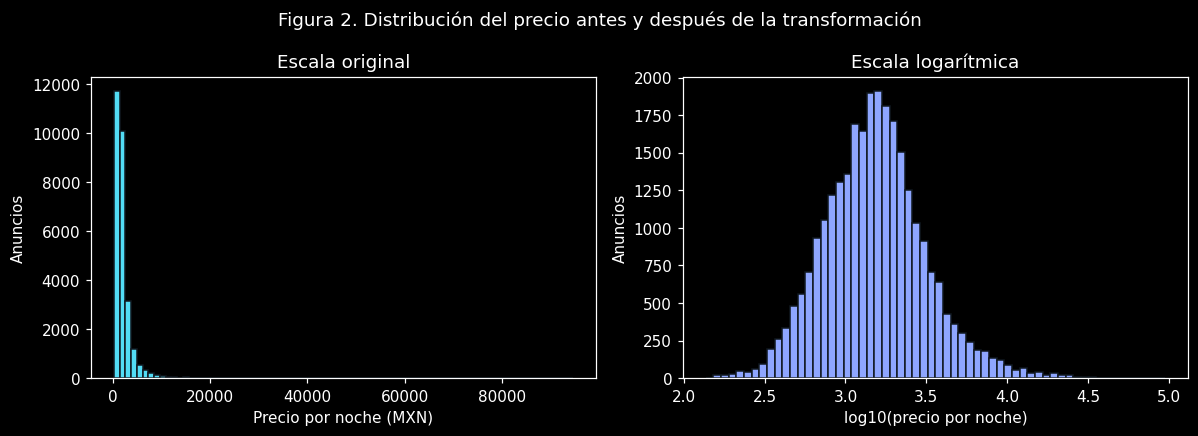

Coeficiente de asimetría del precio:        11.97
Coeficiente de asimetría de log10(precio):  0.45


In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].hist(analisis["precio"], bins=80, color=COL["cyan"], edgecolor="#101820")
ejes[0].set(title="Escala original", xlabel="Precio por noche (MXN)", ylabel="Anuncios")
ejes[1].hist(np.log10(analisis["precio"]), bins=60, color=COL["azul"], edgecolor="#101820")
ejes[1].set(title="Escala logarítmica", xlabel="log10(precio por noche)", ylabel="Anuncios")
fig.suptitle("Figura 2. Distribución del precio antes y después de la transformación")
plt.tight_layout()
plt.show()

print(f"Coeficiente de asimetría del precio:        {analisis['precio'].skew():.2f}")
print(f"Coeficiente de asimetría de log10(precio):  {np.log10(analisis['precio']).skew():.2f}")

En escala original la distribución tiene un coeficiente de asimetría de 11.97: casi todos los anuncios quedan en las primeras barras y el resto de la gráfica está vacío. En escala logarítmica la asimetría baja a 0.45 y la distribución toma forma de campana, en la que sí se distinguen el centro y la dispersión.

Por esto pensamos graficar el precio con ejes logarítmicos. Los resúmenes numéricos los seguimos reportando en pesos, que es la unidad que se interpreta directamente, y preferimos la mediana y los cuartiles a la media y la desviación estándar.

### **3.9. Decisión 5: Tratamiento de outliers en `maximum_nights`**

La variable presenta un valor máximo de 2,147,483,647, equivalente a 2³¹-1, el límite de un entero de 32 bits. Se trata de un valor que indica que no existe límite y no de una cifra real. Además, el IQR no resulta una prueba adecuada para esta variable, ya que se trata de una variable discreta con picos en valores de configuración habituales, por lo que sus límites resultarían demasiado estrechos y marcarían como atípicos valores legítimos.

Se estableció una regla de dominio en lugar de un umbral estadístico. Según la documentación de integración de Rentals United con Airbnb, los límites de
estancia aceptados por la plataforma van de 1 a 1,125 noches, y valores superiores se reducen automáticamente a 1,125 [Rentals United, Price and availability](https://docs.rentalsunited.com/hc/en-gb/articles/34003672254109-Step-5-Price-and-availability). Por ello, 1,125 se tomó como el tope de la variable, y los valores superiores como ausencia práctica de límite.
Previo al tope, se creó la variable indicadora `sin_limite_noches` (`maximum_nights >= 1125`) para conservar la información de qué anuncios no establecen límite máximo de estancia.

In [ ]:
analisis['maximum_nights'].max()

2147483647.0

In [ ]:
# Bandera creada antes de modificar la variable
analisis["sin_limite_noches"] = analisis["maximum_nights"] >= 1125

# Tope en 1,125 noches
analisis.loc[analisis["maximum_nights"] > 1125, "maximum_nights"] = 1125


In [ ]:
# 1. Banderas (antes de modificar la variable)
analisis["maximum_nights_topado"] = analisis["maximum_nights"] > 1125   # qué se modificó
analisis["sin_limite_noches"] = analisis["maximum_nights"] >= 1125      # característica del anuncio

# 2. Tope en 1,125 noches
analisis.loc[analisis["maximum_nights"] > 1125, "maximum_nights"] = 1125


# 3. Verificación
print(analisis["maximum_nights"].max())                  # esperado: 1125
print(analisis["maximum_nights_topado"].sum())           # N de registros topados
print(round(analisis["maximum_nights_topado"].mean() * 100, 2))   # X% del total
print(analisis["sin_limite_noches"].sum())              # topados + los que ya tenían 1125

1125.0
0
0.0
10716


### **3.10. Decisión 6: Tratamiento de outliers en `bedrooms` y `beds`**

Al explorar `bedrooms` y `beds` encontramos algo que no cuadra: ambas variables llegan a un máximo de 50, cuando el 99% de los anuncios tiene 6 recámaras o menos y 8 camas o menos. Esos valores de 50 están aislados del resto de la distribución y aparecen en anuncios cuya capacidad (`accommodates`) no los respalda. Es decir, no parecen casos reales, sino valores puestos por defecto o errores de captura.

Primero probamos el criterio del rango intercuartílico (IQR), pero no funciona bien con variables discretas y concentradas como estas. En `beds`, su límite superior es de 3.5, así que marca como atípicos valores perfectamente normales, como 4 o 5 camas. Por eso el IQR señala 10.2% de registros, mientras que el criterio Z señala solo 1.35%. Necesitábamos una regla más precisa.

**La regla que usamos.** Marcamos como sospechoso un anuncio si cumple alguna de estas dos condiciones:

1. **Tiene un valor de 50** en `bedrooms` o en `beds`, que tratamos como valor por defecto.
2. **Tiene una proporción de camas por recámara poco creíble.** Para cada anuncio con al menos una recámara calculamos cuántas camas hay por recámara (`beds / bedrooms`). Marcamos los casos que quedan en los extremos de esa distribución, por debajo del percentil 0.1% o por encima del 99.9%. La idea es detectar combinaciones raras entre las dos variables sin imponer un tope arbitrario.

Usamos percentiles y no un tope fijo, como "máximo 5 camas por recámara", porque así dejamos que los datos digan qué es normal en esta ciudad, sin imponer un número que elegimos nosotros.

In [ ]:
# 1. Ver como quedaría antes de hacer el cambio para asegurarnos de que nos se quitan demasiados valores
base = analisis[analisis["bedrooms"] >= 1].copy()
base["camas_por_recamara"] = base["beds"] / base["bedrooms"]

# 2. Limites de razonabilidad: 0.1% y 99.9%
lim_inf = base["camas_por_recamara"].quantile(0.001)
lim_sup = base["camas_por_recamara"].quantile(0.999)

# 3. Banderas de registros que se harían nulos
val_50 = (analisis["bedrooms"] == 50) | (analisis["beds"] == 50)
razon = analisis["beds"] / analisis["bedrooms"].where(analisis["bedrooms"] >= 1)
fuera_relacion = (razon < lim_inf) | (razon > lim_sup)

total = len(analisis)
afectados = val_50 | fuera_relacion

# 2. Cuánto se haría nulo
print(f"Límites de razón: {lim_inf:.2f} a {lim_sup:.2f}")
print(f"val_50:          {val_50.sum():>6}  ({val_50.mean()*100:.3f}%)")
print(f"fuera_relacion:  {fuera_relacion.sum():>6}  ({fuera_relacion.mean()*100:.3f}%)")
print(f"Total afectados: {afectados.sum():>6}  ({afectados.mean()*100:.3f}%)")

# 3. Si ya había nulos, no cuentes dos veces los que ya lo eran
print("Ya nulos en bedrooms:", analisis["bedrooms"].isna().sum())
print("Ya nulos en beds:    ", analisis["beds"].isna().sum())

Límites de razón: 0.25 a 6.00
val_50:               4  (0.014%)
fuera_relacion:      35  (0.126%)
Total afectados:     39  (0.140%)
Ya nulos en bedrooms: 22
Ya nulos en beds:     393


In [ ]:
analisis[fuera_relacion].assign(razon=razon)[
    ["bedrooms", "beds", "accommodates", "razon"]
].sort_values("razon")

,bedrooms,beds,accommodates,razon
12369,25.00,1.00,1,0.04
18351,21.00,1.00,16,0.05
7037,16.00,1.00,2,0.06
19525,14.00,1.00,1,0.07
12016,13.00,1.00,2,0.08
12018,23.00,2.00,3,0.09
13745,10.00,1.00,1,0.10
14763,10.00,1.00,1,0.10
13746,10.00,1.00,1,0.10
14761,10.00,1.00,1,0.10


In [ ]:
# Conteos por regla y solapamiento
solo_50 = (val_50 & ~fuera_relacion).sum()
solo_rel = (fuera_relacion & ~val_50).sum()
ambas = (val_50 & fuera_relacion).sum()

print(f"Solo valor 50:           {solo_50:>6}")
print(f"Solo fuera de relación:  {solo_rel:>6}")
print(f"Ambas reglas:            {ambas:>6}")
print(f"Total únicos afectados:  {afectados.sum():>6}")

# Cuántos de los afectados tienen razón no calculable (bedrooms = 0 o nulo)
print("Razón no calculable entre afectados:", (afectados & razon.isna()).sum())

Solo valor 50:                4
Solo fuera de relación:      35
Ambas reglas:                 0
Total únicos afectados:      39
Razón no calculable entre afectados: 1


La tabla muestra los 35 anuncios marcados por su proporción de camas por recámara, ordenados de la proporción más baja a la más alta. Al revisarlos, ninguno parece un alojamiento real, y los errores van en dos direcciones.

Los de arriba de la tabla tienen demasiadas recámaras para las camas que declaran. Hay un anuncio con 25 recámaras y una sola cama para un huésped, y otros con 10 o 14 recámaras y una cama. En casi todos la cama sí coincide con la capacidad, así que el dato dudoso parece ser el número de recámaras.

Los de abajo tienen demasiadas camas para tan pocas recámaras. Hay anuncios con una recámara y 7 u 8 camas para un huésped, uno con una recámara y 16 camas para dos personas, y otro con 6 recámaras y 42 camas.

Como no sabemos cuál de las dos variables es la equivocada, ni si algún caso es legítimo, preferimos dejar ambas en nulo y conservamos el resto de la información del anuncio. Son 35 casos de 27,820, así que la muestra casi no cambia.



In [ ]:
# Trazabilidad
analisis["bedrooms_beds_corregido"] = afectados

# Aplicar
analisis.loc[afectados, ["bedrooms", "beds"]] = np.nan

# Verificación
print(analisis["bedrooms_beds_corregido"].sum())          # esperado: 39
print(analisis["bedrooms"].max(), analisis["beds"].max())  # nuevos máximos

39
28.0 40.0


Convertimos a valor nulo tanto `bedrooms` como `beds` en esos registros. Elegimos nulo y no un tope porque en estos casos no sabemos cuántas recámaras o camas tenía realmente el anuncio. Anulamos ambas variables a la vez porque, si la relación entre ellas es incoherente, no podemos saber cuál de las dos es la errónea. Los demás valores altos se conservaron, ya que guardan una relación razonable entre camas y recámaras.

Creamos la variable indicadora `bedrooms_beds_corregido`, que vale verdadero en los registros modificados, para poder rastrearlos o excluirlos después.

**Un caso aparte:** Los anuncios con `bedrooms = 0` no se trataron como outliers, porque la proporción camas por recámara no se puede calcular con cero recámaras. Una hipótesis es que sean alojamientos con un uso distinto al de un hospedaje tradicional (por ejemplo, espacios para eventos). Esto podría investigarse revisando los enlaces de procedencia de esos anuncios.

### **3.11. Decisión 7: Tratamiento de categorías de baja frecuencia en `property_type`**

La variable `property_type` presenta 86 niveles, de los cuales 75 aparecen en menos del 1% de los registros y en conjunto suman solo 8.4%. Como se describió en el análisis exploratorio, la cardinalidad se multiplica de forma artificial porque la variable mezcla dos conceptos: el tipo de espacio (`Entire`, `Private room`, `Shared room`, `Room in`) y el tipo de inmueble (`rental unit`, `condo`, `home`, `loft`). Además, entre las categorías raras aparecen etiquetas genéricas o redundantes (`Private room`, `Entire place`, `Entire home/apt`), cuya información ya está contenida en `room_type`.


In [ ]:

# property_type: agrupar categorías raras (< 1%) en "Other"
UMBRAL = 0.01

freq = analisis['property_type'].value_counts(normalize=True)
niveles_frecuentes = freq[freq >= UMBRAL].index

# Se conserva la columna original por trazabilidad.
# Los nulos (si los hubiera) se mantienen como NaN y no se mezclan con "Other".
analisis['property_type_grouped'] = analisis['property_type'].where(
    analisis['property_type'].isin(niveles_frecuentes) | analisis['property_type'].isna(),
    'Other'
)

# Verificación
print("Niveles originales en property_type:", analisis['property_type'].nunique())
print("Niveles después de agrupar:        ", analisis['property_type_grouped'].nunique())
print("Niveles conservados (sin 'Other'): ", len(niveles_frecuentes))
print("Registros agrupados en 'Other':    ", (analisis['property_type_grouped'] == 'Other').sum())
print("% en 'Other':                      ",
      round((analisis['property_type_grouped'] == 'Other').mean() * 100, 1))

print("\nDistribución de property_type_grouped:")
print((analisis['property_type_grouped'].value_counts(normalize=True) * 100).round(1))

Niveles originales en property_type: 82
Niveles después de agrupar:         12
Niveles conservados (sin 'Other'):  11
Registros agrupados en 'Other':     2307
% en 'Other':                       8.3

Distribución de property_type_grouped:
property_type_grouped
Entire rental unit            41.20
Entire condo                  10.90
Private room in rental unit   10.10
Private room in home           8.70
Other                          8.30
Entire loft                    5.60
Entire home                    3.50
Room in hotel                  3.00
Entire serviced apartment      2.80
Private room in condo          2.40
Private room in guesthouse     2.30
Private room in guest suite    1.00
Name: proportion, dtype: float64



Los niveles con una frecuencia menor al 1% se agruparon en una categoría única llamada `Other`. Con este umbral se conservaron 11 niveles propios (91.6% de los registros) y se agruparon **2307** registros en `Other` (8.4%), con lo que la variable pasó de 86 a 12 niveles.

Se optó por agrupar y no por eliminar registros, ya que las categorías raras son anuncios válidos y su eliminación implicaría perder información de otras variables. Tampoco se separaron el tipo de espacio y el tipo de inmueble, porque el primero ya está representado en `room_type` y la separación requeriría reglas de texto adicionales con poco beneficio para el modelado. Se creó la variable `property_type_grouped` y se conservó `property_type` original por trazabilidad. Los valores nulos, si los hubiera, no se mezclaron con `Other`.

### 3.12. Variables para el análisis

Por último, traducimos la modalidad al español, renombramos algunas columnas y construimos las variables que necesitamos para responder las preguntas de investigación: el logaritmo del precio y el número de anuncios que tiene cada anfitrión dentro de la captura actual, agrupado en cuatro tamaños.

In [ ]:
MODALIDADES = {
    "Entire home/apt": "Alojamiento completo",
    "Private room": "Habitación privada",
    "Shared room": "Habitación compartida",
    "Hotel room": "Habitación de hotel",
}
TAMANOS = ["1 anuncio", "2 a 9", "10 a 49", "50 o más"]

anuncios_por_anfitrion = vigentes.groupby("host_id").size()

analisis = analisis.rename(columns={
    "neighbourhood_cleansed": "alcaldia", "accommodates": "capacidad", "bedrooms": "recamaras"})
analisis["modalidad"] = analisis["room_type"].map(MODALIDADES)
analisis["log_precio"] = np.log10(analisis["precio"])
analisis["anuncios_anfitrion"] = analisis["host_id"].map(anuncios_por_anfitrion)
analisis["tamano_anfitrion"] = pd.cut(analisis["anuncios_anfitrion"],
                                      bins=[0, 1, 9, 49, np.inf], labels=TAMANOS)

pd.Series({
    "Anuncios en listings": len(listings),
    "Anuncios de la captura actual": len(vigentes),
    "Con precio": len(con_precio),
    "Base final (sin precios no creíbles)": len(analisis),
}).to_frame("anuncios")

,anuncios
Anuncios en listings,30468
Anuncios de la captura actual,28284
Con precio,27904
Base final (sin precios no creíbles),27820


La base de análisis queda con 27,820 anuncios, el 91.3 % de los que venían en el archivo original.

In [ ]:
# Otener las columnas del df analisis
analisis.columns
#Ver su shape
analisis.shape


(27820, 38)

## **4. Visualización y respuesta a las preguntas**

### 4.1. ¿Cómo se distribuye el precio anunciado por noche y cómo difiere entre tipos de alojamiento por alcaldía?

**Enfoque.** La pregunta tiene dos partes y las respondemos en ese orden:

1. Distribución del precio, en toda la base y por tipo de alojamiento.
2. Diferencias entre tipos de alojamiento dentro de cada alcaldía.

Decisiones de método:

- Como "tipo de alojamiento" usamos `modalidad` (alojamiento completo, habitación privada, habitación compartida y habitación de hotel) y no `property_type`, porque esta última mezcla el tipo de espacio con el tipo de inmueble y tiene 86 niveles (Decisión 7).
- Como el precio es muy asimétrico (Decisión 4), lo resumimos con **mediana y cuartiles** y lo graficamos en **escala logarítmica**.

In [ ]:
from matplotlib.ticker import FuncFormatter, NullFormatter

MIN_N = 5
COMPARABLES = ["Alojamiento completo", "Habitación privada"]
COLORES = {"Alojamiento completo": COL["cyan"], "Habitación privada": COL["naranja"]}

def formato_pesos(eje):
    # Etiquetas en pesos (en vez de 10^3) para un eje logarítmico
    eje.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
    eje.set_minor_formatter(NullFormatter())

#### 4.1.1. Distribución del precio por noche

La tabla siguiente resume el precio de toda la base y de cada modalidad con cinco números:

- **anuncios**: cuántos anuncios hay en el grupo.
- **media**: el promedio.
- **mediana**: el precio que deja la mitad de los anuncios por debajo y la otra mitad por encima.
- **Q1 (25 %) y Q3 (75 %)**: el 25 % de los anuncios cuesta menos que Q1 y el 75 % cuesta menos que Q3. Entre Q1 y Q3 está la mitad central de los precios, y su amplitud indica qué tan dispersos son.

In [ ]:
def resumen(df, por):
    return (df.groupby(por, observed=True)["precio"]
            .agg(anuncios="size", media="mean",
                 q1=lambda s: s.quantile(0.25), mediana="median",
                 q3=lambda s: s.quantile(0.75)))

todos = resumen(analisis.assign(modalidad="Todos los anuncios"), "modalidad")
por_modalidad = resumen(analisis, "modalidad").sort_values("mediana", ascending=False)

distribucion = (pd.concat([todos, por_modalidad])
                .rename(columns={"q1": "Q1 (25 %)", "q3": "Q3 (75 %)"}))
display(distribucion.round(2))

,anuncios,media,Q1 (25 %),mediana,Q3 (75 %)
modalidad,,,,,
Todos los anuncios,27820,"2,103.35",943.46,"1,500.00","2,320.00"
Habitación de hotel,71,"4,009.73","1,298.50","2,088.00","6,290.50"
Alojamiento completo,18601,"2,550.41","1,325.00","1,829.00","2,693.00"
Habitación privada,8907,"1,193.82",608.00,849.00,"1,249.50"
Habitación compartida,241,652.11,283.50,400.00,704.00


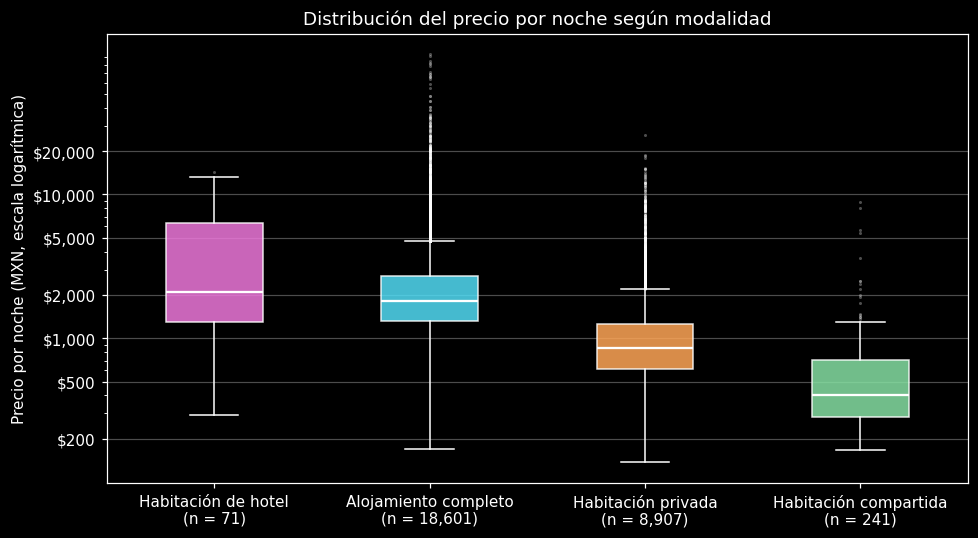

In [ ]:
orden = por_modalidad.index.tolist()
datos = [analisis.loc[analisis["modalidad"] == m, "precio"] for m in orden]

fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(datos, patch_artist=True, medianprops=dict(color="white", linewidth=1.5),
                flierprops=dict(marker=".", markersize=2, alpha=0.3, markeredgecolor="white"))
for caja, m in zip(bp["boxes"], orden):
    caja.set_facecolor(COLOR_MODALIDAD.get(m, COL["azul"]))
    caja.set_alpha(0.85)
ax.set_xticks(range(1, len(orden) + 1))
ax.set_xticklabels([f"{m}\n(n = {len(d):,})" for m, d in zip(orden, datos)])
ax.set_yscale("log")
ax.set_yticks([200, 500, 1000, 2000, 5000, 10000, 20000])
formato_pesos(ax.yaxis)
ax.set(title="Distribución del precio por noche según modalidad",
       ylabel="Precio por noche (MXN, escala logarítmica)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación.**
- De manera general, la mediana es de \$1,500 y la media de \$2,103. La media es mayor porque unos pocos anuncios muy caros la jalan hacia arriba (cola derecha), por eso usamos la mediana como valor típico.

- El tipo de alojamiento muestra la diferencia de precios con mayor claridad. La mediana de un alojamiento completo (\$1,829) es más del doble que la de una habitación privada (\$849) y más de cuatro veces la de una habitación compartida (\$400).

- Las cajas de los alojamientos completos y alojamientos privados casi no se superponen, esto tiene sentido ya que el 75 % de las habitaciones privadas cuesta menos de unos \$1,250 (su Q3), y el 75 % de los alojamientos completos cuesta más de \$1,325 (su Q1).

- Las habitaciones de hotel tienen la mediana más alta (\$2,088), pero son solo 71 anuncios, ademas su caja es la más ancha: la mitad central de sus precios va de cerca de \$1,300 a cerca de \$6,300, así que su "precio típico" es poco representativo.
<br>



#### 4.1.2. Diferencias entre tipos de alojamiento por alcaldía

Para comparar los precios típicos de cada modalidad dentro de cada alcaldía necesitamos suficientes anuncios en cada grupo: con 1 o 2 anuncios, la "mediana" es simplemente el precio de ese anuncio y no describe nada típico. Por eso primero contamos cuántos anuncios hay en cada combinación de alcaldía y modalidad.

In [ ]:
conteo_grupos = (analisis.groupby(["alcaldia", "modalidad"], observed=True)
                 .size().unstack(fill_value=0))
display(conteo_grupos)

n_comparables = conteo_grupos[COMPARABLES].sum().sum()
print(f"Alojamientos completos + habitaciones privadas: {n_comparables:,} de {len(analisis):,} anuncios "
      f"({n_comparables / len(analisis):.1%})")

modalidad,Alojamiento completo,Habitación compartida,Habitación de hotel,Habitación privada
alcaldia,,,,
Azcapotzalco,247,2,0,132
Benito Juárez,1846,11,5,1274
Coyoacán,1029,6,3,994
Cuajimalpa de Morelos,254,0,0,100
Cuauhtémoc,9552,168,46,3209
Gustavo A. Madero,289,9,0,245
Iztacalco,334,4,0,213
Iztapalapa,197,5,0,157
La Magdalena Contreras,55,1,0,61


Alojamientos completos + habitaciones privadas: 27,508 de 27,820 anuncios (98.9%)


La tabla muestra que las **habitaciones compartidas y de hotel** tienen muy pocos anuncios en casi todas las alcaldías (por ejemplo, Álvaro Obregón tiene 1 habitación compartida), incluso algunas ni tienen; solo Cuauhtémoc tiene al menos 30 de cada una (168 y 46). En cambio, los **alojamientos completos y las habitaciones privadas** son casi toda la base y tienen datos en todas las alcaldías. Por lo tanto, al abarcar el 98.9% de los datos se consideró que para esta pregunta es suficiente trabajar con esos dos tipos de cuarto para poder responderla.

Se puede observar que tanto Tláhuac como Milpa Alta son los que tienen la menor cantidad de anuncios (siendo 46 y 25 respectivamente), sin embargo podemos notar que esos anuncios estan concentrados en **alojamientos completos** y **habitaciones privadas**. Por lo tanto a pesar de tener pocos datos aun logran reunir los requisitos para entrar dentro del análisis.



La siguiente tabla tiene una fila por alcaldía y muestra, para cada una:

- **anuncios completos** y **anuncios privados**: cuántos anuncios de cada modalidad hay en la alcaldía.
- **mediana completos** y **mediana privadas**: el precio típico por noche de cada modalidad en esa alcaldía.
- **# veces más caro**: la mediana de completos dividida entre la de privadas. Un 2.0 significa que, en esa alcaldía, el precio típico de un alojamiento completo es el doble que el de una habitación privada.

In [ ]:
sub = analisis[analisis["modalidad"].isin(COMPARABLES)]

grupos = (sub.groupby(["alcaldia", "modalidad"], observed=True)["precio"]
          .agg(anuncios="size", mediana="median",
               q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
          .reset_index())

# Nos quedamos con las alcaldías que cumplen el mínimo en las dos modalidades
suficientes = grupos[grupos["anuncios"] >= MIN_N]
con_ambas = suficientes.groupby("alcaldia")["modalidad"].nunique().eq(len(COMPARABLES))
alcaldias_ok = con_ambas[con_ambas].index
suficientes = suficientes[suficientes["alcaldia"].isin(alcaldias_ok)]

ancha = suficientes.pivot(index="alcaldia", columns="modalidad", values=["anuncios", "mediana"])
tabla = pd.DataFrame({
    "anuncios completos": ancha[("anuncios", "Alojamiento completo")].astype(int),
    "mediana completos":  ancha[("mediana",  "Alojamiento completo")],
    "anuncios privadas":  ancha[("anuncios", "Habitación privada")].astype(int),
    "mediana privadas":   ancha[("mediana",  "Habitación privada")],
})
tabla["# veces más caro"] = tabla["mediana completos"] / tabla["mediana privadas"]
tabla = tabla.sort_values("mediana completos", ascending=False)

print("Alcaldías excluidas por tener menos de", MIN_N, "anuncios en alguna modalidad:",
      sorted(set(grupos["alcaldia"]) - set(alcaldias_ok)))
display(tabla.round(2))

Alcaldías excluidas por tener menos de 5 anuncios en alguna modalidad: []


,anuncios completos,mediana completos,anuncios privadas,mediana privadas,# veces más caro
alcaldia,,,,,
Miguel Hidalgo,3170,"2,205.77",1086,971.58,2.27
Cuajimalpa de Morelos,254,"1,938.75",100,961.55,2.02
Cuauhtémoc,9552,"1,933.36",3209,940.90,2.05
Tlalpan,413,"1,615.00",497,761.00,2.12
Álvaro Obregón,504,"1,599.50",393,897.00,1.78
Coyoacán,1029,"1,597.00",994,849.00,1.88
Benito Juárez,1846,"1,580.74",1274,765.84,2.06
Iztacalco,334,"1,365.70",213,820.00,1.67
La Magdalena Contreras,55,"1,353.00",61,910.00,1.49


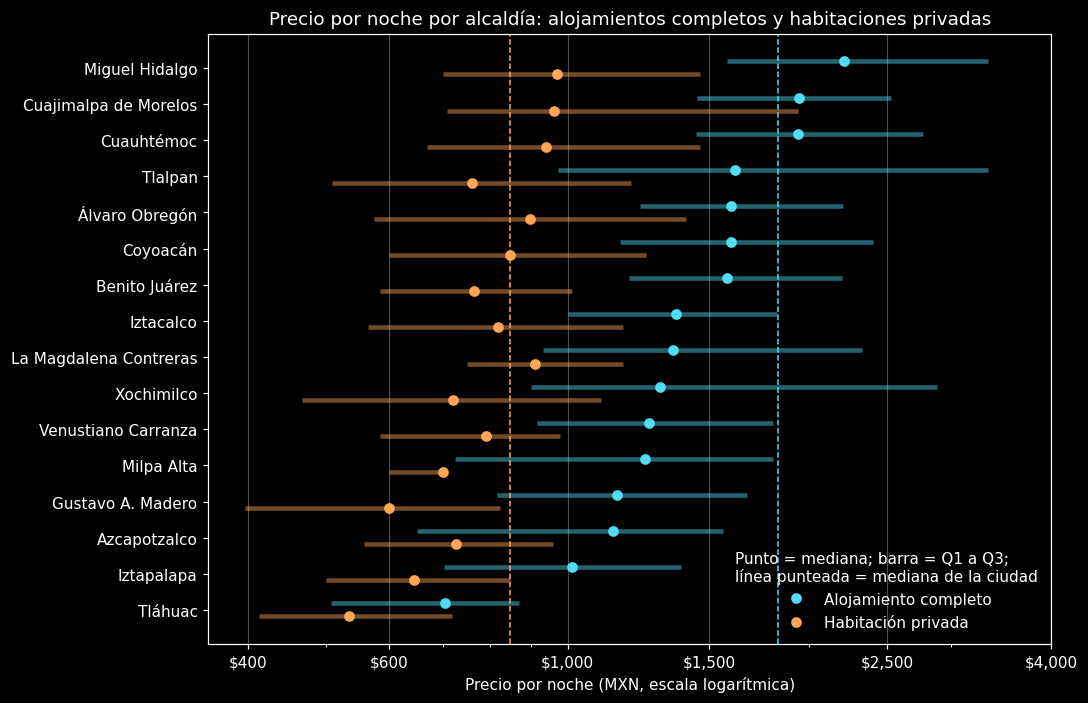

In [ ]:
posicion = np.arange(len(tabla))
desfase = {"Alojamiento completo": -0.18, "Habitación privada": 0.18}

fig, ax = plt.subplots(figsize=(10, 6.5))
for modalidad in COMPARABLES:
    d = (suficientes[suficientes["modalidad"] == modalidad]
         .set_index("alcaldia").loc[tabla.index])
    y = posicion + desfase[modalidad]
    ax.hlines(y, d["q1"], d["q3"], color=COLORES[modalidad], linewidth=3, alpha=0.45)   # Q1 a Q3
    ax.plot(d["mediana"], y, "o", color=COLORES[modalidad], label=modalidad)             # mediana
    ax.axvline(analisis.loc[analisis["modalidad"] == modalidad, "precio"].median(),
               color=COLORES[modalidad], linestyle="--", linewidth=1)                     # mediana de la ciudad

ax.set_yticks(posicion)
ax.set_yticklabels(tabla.index)
ax.invert_yaxis()                                  # la alcaldía con mayor mediana de completos arriba
ax.set_xscale("log")
ax.set_xticks([400, 600, 1000, 1500, 2500, 4000])
formato_pesos(ax.xaxis)
ax.set(title="Precio por noche por alcaldía: alojamientos completos y habitaciones privadas",
       xlabel="Precio por noche (MXN, escala logarítmica)")
ax.legend(title="Punto = mediana; barra = Q1 a Q3;\nlínea punteada = mediana de la ciudad",
          loc="lower right", frameon=False)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación:**

- **Las mismas alcaldías encabezan ambos tipos.** Miguel Hidalgo, Cuajimalpa de Morelos y Cuauhtémoc tienen las medianas más altas tanto en alojamientos completos (\$2,206, \$1,939 y \$1,933) como en habitaciones privadas (\$972, \$962 y \$941). En el extremo bajo se encuentran Tláhuac e Iztapalapa.
- **La ubicación pesa más en los alojamientos completos.** Su mediana va de \$703 (Tláhuac) a \$2,206 (Miguel Hidalgo), más del triple. En las habitaciones privadas va de \$535 (Tláhuac) a \$972 (Miguel Hidalgo), menos del doble.
- **La brecha entre tipos cambia según la alcaldía.** Un alojamiento completo cuesta de 1.3 veces (Tláhuac) a 2.3 veces (Miguel Hidalgo) lo que una habitación privada. La brecha supera 2 veces en Miguel Hidalgo, Tlalpan, Benito Juárez, Cuauhtémoc y Cuajimalpa de Morelos.
- **Hay que leer las diferencias con cuidado.** Las barras (Q1 a Q3) de la gráfica anterior son anchas y se traslapan entre muchas alcaldías, esto significa que dentro de una misma alcaldía hay anuncios baratos y caros de cada tipo. Solo las diferencias grandes (las alcaldías de arriba frente a las de abajo) son claras.
<br><br>



**Respuesta a la pregunta.**

**¿Cómo se distribuye el precio anunciado por noche?** El precio se concentra en valores relativamente bajos, con una cola de alojamientos muy caros: la mediana es de \$1,500 y la media de \$2,103. Como la media es mayor, usamos la mediana como el precio típico.

**¿Cómo difiere entre tipos de alojamiento?** El tipo de alojamiento es la diferencia más clara. La mediana de un alojamiento completo (\$1,829) es más del doble que la de una habitación privada (\$849) y más de cuatro veces la de una habitación compartida (\$400), ademas las cajas de completos y privadas casi no se superponen (observe primer gráfica de la pregunta). Las habitaciones de hotel tienen la mediana más alta (\$2,088), pero son solo 71 alojamientos y sus precios son muy dispersos, por lo que su valor típico es poco representativo.

**¿Y cómo cambia por alcaldía?** Comparamos alojamientos completos y habitaciones privadas, que son el 98.9 % de la base, en las 16 alcaldías:

- En todas las alcaldías el alojamiento completo es más caro que la habitación privada, pero la brecha cambia: va de 1.3 veces (Tláhuac) a 2.3 veces (Miguel Hidalgo).
- Miguel Hidalgo, Cuajimalpa de Morelos y Cuauhtémoc son las alcaldías más caras en ambos tipos de alojamiento, y Tláhuac tiene las medianas más bajas en ambos.
- La ubicación pesa más en los alojamientos completos: su mediana va de \$703 (Tláhuac) a \$2,206 (Miguel Hidalgo), más del triple, mientras que en las habitaciones privadas va de \$535 a \$972, menos del doble.

### 4.2. ¿Cómo se relaciona la distancia de los alojamientos al centro de la ciudad con sus precios anunciados?

#### 4.2.1. Ingeniería de variables y distribución de la distancia al centro (`dist_centro_km`)

Notemos como las variables `latitude` y `longitude` parecen ser las óptimas para responder está sección (además de la variable de observación precio), pero el problema, que es más que obvio, es que la unidad de medida inicial no es la mejor para medir distancias en km, entonces construimos una nueva variable dedicada exclusivamente para esta pregunta la cual llamaremos `dist_centro_km`. Este análisis recurre, en su mayoría, a uno de tipo bivariado entre la variable recién creada y la definida anteriormente como precio.

Para hacer la ingeniería de variables, solo hace falta una búsqueda para determinar la ubicación del zócalo en coordenadas y averiguar qué métrica nos permite calcular distancias entre dos coordenadas del tipo; usaremos la métrica *Haversine* en kilómetros respecto las coordenadas de cada anuncio y el zócalo de la Ciudad de México **(19.432608,-99.133209)**.

A continuación se crea y realiza un análisis exploratorio de la nueva variable.

,count,mean,std,min,5%,25%,50%,75%,80%,95%,99%,max
dist_centro_km,"27,820.00",6.14,4.14,0.02,1.39,3.59,5.01,7.40,8.22,15.58,19.51,31.76
precio,"27,820.00","2,103.35","2,897.34",136.80,489.00,943.46,"1,500.00","2,320.00","2,617.60","5,338.21","12,099.54","94,729.00"


,variable,n,media,mediana,desv_std,RIC,asimetria
0,dist_centro_km,27820,6.14,5.01,4.14,3.81,1.67
1,precio,27820,"2,103.35","1,500.00","2,897.34","1,376.54",11.97


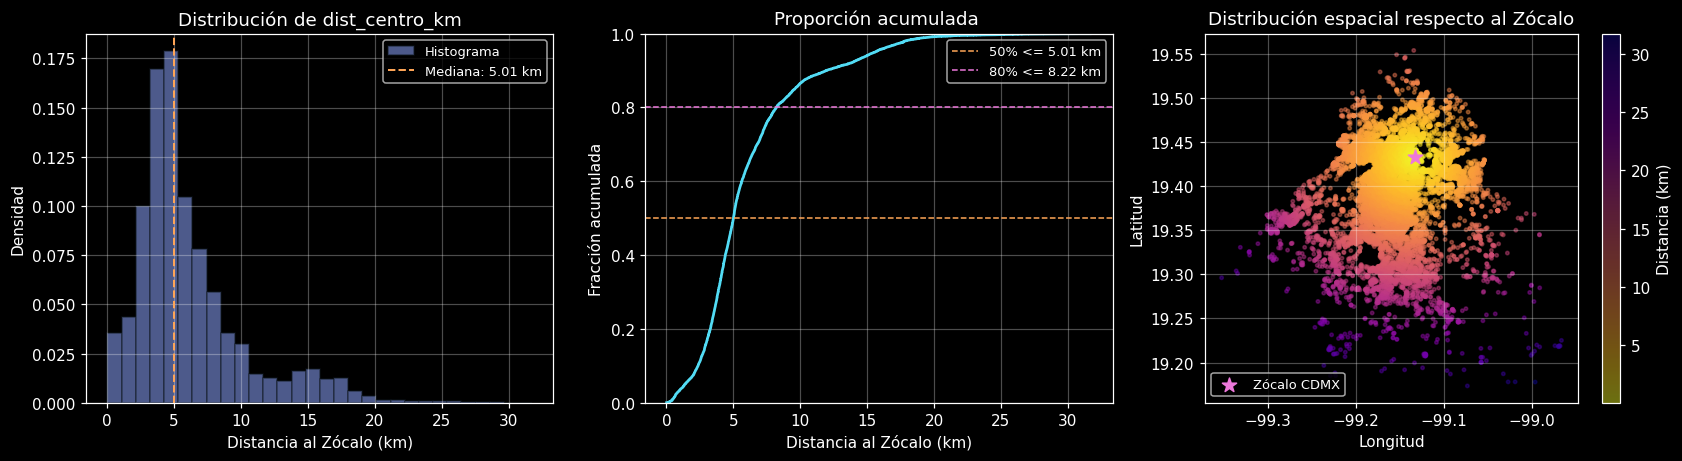

In [ ]:
from scipy.stats import gaussian_kde

LAT_ZOCALO, LON_ZOCALO = 19.432608, -99.133209

def haversine_km(lat, lon, lat_ref=LAT_ZOCALO, lon_ref=LON_ZOCALO):
    r_tierra = 6371.0088
    lat1, lon1 = np.radians(lat), np.radians(lon)
    lat2, lon2 = np.radians(lat_ref), np.radians(lon_ref)
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * r_tierra * np.arcsin(np.minimum(1.0, np.sqrt(a)))

# Copia de trabajo para la pregunta apartir de  `analisis`
df_p2 = analisis.assign(
    dist_centro_km=lambda d: haversine_km(d["latitude"], d["longitude"]).round(3)
)

# Controles de integridad
assert len(df_p2) == len(analisis), "Cambió el número de filas."
assert df_p2["dist_centro_km"].notna().all(), "Se generaron nulos en dist_centro_km."

# Centro, dispersión, forma y percentiles
vars_p2 = ["dist_centro_km", "precio"]
display(df_p2[vars_p2].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.80, 0.95, 0.99]).T.round(2))

resumen = []
for col in vars_p2:
    s = df_p2[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    resumen.append({
        "variable": col,
        "n": s.size,
        "media": s.mean(),
        "mediana": s.median(),
        "desv_std": s.std(ddof=1),
        "RIC": q3 - q1,
        "asimetria": s.skew(),
    })
display(pd.DataFrame(resumen).round(2))

# Visualización univariada y espacial de dist_centro_km
x = df_p2["dist_centro_km"].to_numpy()
x_ord = np.sort(x)
y_ecdf = np.arange(1, len(x_ord) + 1) / len(x_ord)
p50, p80 = np.quantile(x, [0.50, 0.80])

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))


# Panel 1: Distribución en Histograma
axes[0].hist(x, bins=30, density=True, color=COL["azul"], alpha=0.55, edgecolor="#101820", label="Histograma")
grid = np.linspace(x.min(), x.max(), 250)
axes[0].axvline(p50, color=COL["naranja"], ls="--", lw=1.3, label=f"Mediana: {p50:.2f} km")
axes[0].set(title="Distribución de dist_centro_km", xlabel="Distancia al Zócalo (km)", ylabel="Densidad")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8.5)

# Panel 2: Distribución acumulativa
axes[1].step(x_ord, y_ecdf, where="post", color=COL["cyan"], lw=1.8)
axes[1].axhline(0.50, color=COL["naranja"], ls="--", lw=1, label=f"50% <= {p50:.2f} km")
axes[1].axhline(0.80, color=COL["rosa"], ls="--", lw=1, label=f"80% <= {p80:.2f} km")
axes[1].set(title="Proporción acumulada ", xlabel="Distancia al Zócalo (km)",
            ylabel="Fracción acumulada", ylim=(0, 1))
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8.5)

# Panel 3: Display de todos los registros en un mapa de calor figurando como una proyección cartesiana
sc = axes[2].scatter(df_p2["longitude"], df_p2["latitude"], c=df_p2["dist_centro_km"],
                     cmap="plasma_r", s=5, alpha=0.45)
axes[2].scatter([LON_ZOCALO], [LAT_ZOCALO], color=COL["rosa"], s=95, marker="*", label="Zócalo CDMX")
fig.colorbar(sc, ax=axes[2], label="Distancia (km)")
axes[2].set(title="Distribución espacial respecto al Zócalo", xlabel="Longitud", ylabel="Latitud")
axes[2].grid(alpha=0.3)
axes[2].legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
plt.show()

**Observaciones**

Según la lecturas y gráficos, la variable creada presenta asimetría positiva (constatamos con el histograma y de forma numérica: **1.67**), sumado a la diferencia entre una media de **6.14 km** y mediana de **5.01 km**. Los cuartiles indican que el **50%** de la oferta se concentra entre **3.59 km** y **7.40 km** con **RIC = 3.81 km**, y el **80%** se ubica a menos de **8.22 km**. Aunque podemos observar en el histograma aún hay oferta pasando el umbral e incluso una ligera elevación entre **14 km** y **16 km**. La mancha urbana nos da un panorama complementario a lo ya dicho sobre la distribución de la variable.

#### 4.2.2. Discretización de la distancia y relación bivariada con el precio

Vamos a discretizar la variable `dist_centro_km` con propósito analítico, bajando la granularidad esperamos obtener una mejor relación con el comportamiento no lineal que observaremos. A partir de los cuantiles observados en `dist_centro_km` (**Q1 = 3.59 km**, **Q3 = 7.40 km**, **P95 = 15.58 km**), y de la estructura urbana de la ciudad, podemos proponer múltiples opciones para discretizar la variable continua:
Inicialmente dos formas utilizando cuatro anillos, el primero de forma bruta tomar los **cuantiles observados** y el segundo con criterio/sentido **territorial/de negocio** buscando un alivio visual entre segmentos:
- **<= 3 km (Centro):** primer cuadro y colonias inmediatas al Zócalo.
- **3–7 km (Intermedio):** franja donde se agrupa el núcleo central de la oferta.
- **7–15 km (Periferia urbana):** zonas habitacionales consolidadas e intermedias.
- **> 15 km (Exterior):** cola superior.

También, contrastemos esta partición contra **quintiles** y **octiles** para verificar si la relación con `precio` depende de cómo se cortan los kilómetros. Adicionalmente calculamos correlaciones globales (**Pearson** en `precio` y `log_precio`, y **Spearman**).

,par,n,pearson_r,spearman_rho
0,dist_centro_km vs precio,27820,-0.01,-0.08
1,dist_centro_km vs log_precio,27820,-0.08,-0.08


--- A) Anillos urbanos (pd.cut) ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
anillo_centro,,,,,,,,,,
<= 3 km,"4,585.00",16.48,2.12,"1,786.93","1,000.00","1,428.00","1,999.00",999.00,358.93,0.12
3–7 km,"15,321.00",55.07,4.66,"2,289.37","1,049.50","1,649.00","2,515.50","1,466.00",640.37,-0.04
7–15 km,"6,255.00",22.48,8.98,"1,895.15",800.00,"1,286.86","2,100.00","1,300.00",608.29,-0.09
> 15 km,"1,659.00",5.96,17.07,"2,045.00",703.00,"1,150.50","2,108.00","1,405.00",894.50,-0.04


--- B) Cuantiles (pd.qcut, q=4) ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
dist_q4,,,,,,,,,,
Q1: 0.01–3.59 km,"6,955.00",25.00,2.63,"1,909.20","1,017.84","1,491.00","2,130.69","1,112.86",418.20,0.15
Q2: 3.59–5.01 km,"6,971.00",25.06,4.27,"2,392.28","1,100.00","1,721.50","2,591.26","1,491.26",670.78,0.03
Q3: 5.01–7.40 km,"6,945.00",24.96,5.88,"2,224.91",955.90,"1,564.80","2,552.00","1,596.10",660.11,-0.05
Q4: 7.40–31.76 km,"6,949.00",24.98,10.33,"1,886.34",753.00,"1,225.00","2,012.00","1,259.00",661.34,-0.04


--- B) Quintiles (pd.qcut, q=5) ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
dist_q5,,,,,,,,,,
Q1: 0.01–3.28 km,"5,565.00",20.00,2.37,"1,836.80",999.00,"1,440.00","2,033.00","1,034.00",396.80,0.10
Q2: 3.28–4.40 km,"5,565.00",20.00,3.86,"2,202.54","1,111.00","1,694.08","2,457.00","1,346.00",508.46,-0.04
Q3: 4.40–5.63 km,"5,562.00",19.99,5.01,"2,530.41","1,076.64","1,730.00","2,700.00","1,623.36",800.41,-0.07
Q4: 5.63–8.22 km,"5,566.00",20.01,6.79,"2,045.07",859.12,"1,471.72","2,400.00","1,540.88",573.35,-0.05
Q5: 8.22–31.76 km,"5,562.00",19.99,11.94,"1,902.08",760.00,"1,213.84","1,980.75","1,220.75",688.24,-0.04


--- C) Octiles (pd.qcut, q=8) ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
dist_q8,,,,,,,,,,
O1: 0.01–2.63 km,"3,478.00",12.50,1.71,"1,665.22",985.12,"1,387.50","1,905.74",920.62,277.72,0.08
O2: 2.63–3.59 km,"3,477.00",12.50,3.17,"2,153.25","1,075.50","1,648.57","2,368.00","1,292.50",504.68,0.05
O3: 3.59–4.27 km,"3,489.00",12.54,3.94,"2,199.70","1,100.00","1,661.00","2,409.11","1,309.11",538.70,-0.09
O4: 4.27–5.01 km,"3,482.00",12.52,4.65,"2,585.25","1,100.00","1,786.50","2,767.11","1,667.11",798.75,0.01
O5: 5.01–5.87 km,"3,465.00",12.46,5.34,"2,312.78",990.00,"1,586.67","2,575.00","1,585.00",726.11,-0.09
O6: 5.87–7.40 km,"3,480.00",12.51,6.63,"2,137.42",922.00,"1,526.84","2,538.12","1,616.12",610.59,0.03
O7: 7.40–10.32 km,"3,471.00",12.48,8.53,"1,793.52",820.00,"1,295.00","2,000.00","1,180.00",498.52,0.01
O8: 10.32–31.76 km,"3,478.00",12.50,14.82,"1,978.98",707.50,"1,150.25","2,047.88","1,340.38",828.73,0.04


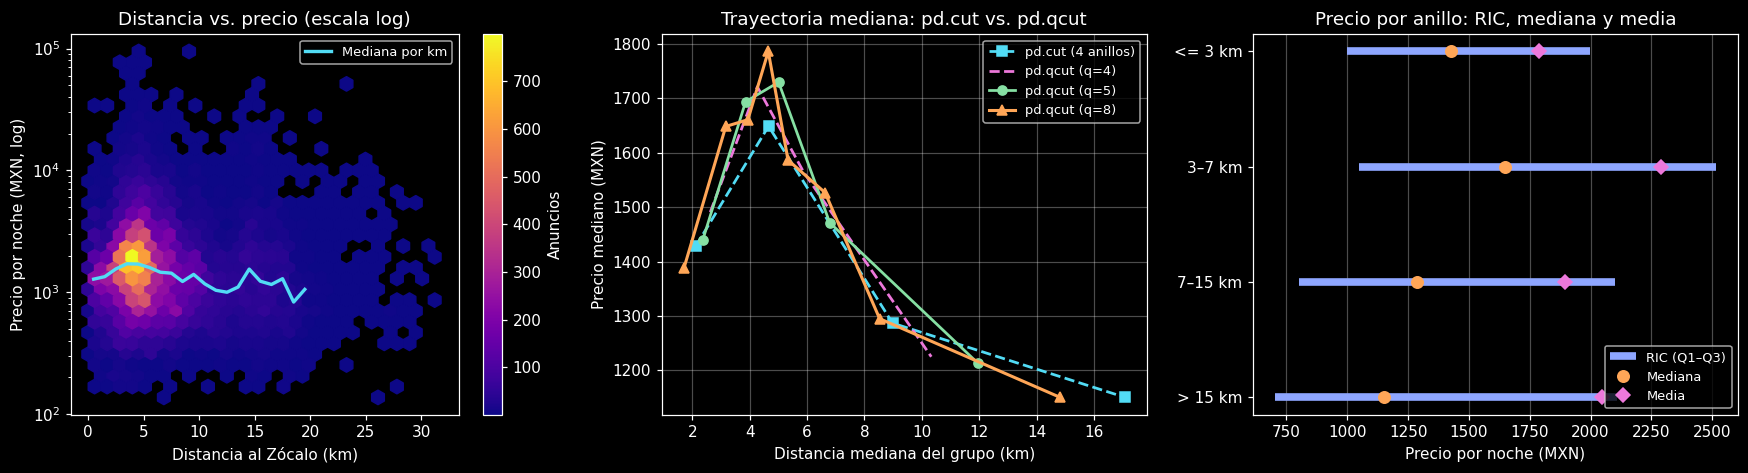

In [ ]:
# --- Paso 2: Discretización (pd.cut vs pd.qcut) y análisis bivariado base ---
ORDEN_ANILLOS = ["<= 3 km", "3–7 km", "7–15 km", "> 15 km"]

def etiquetas_qcut(serie, q, prefijo):
    cats = pd.qcut(serie, q=q, duplicates="drop")
    nombres = [f"{prefijo}{i+1}: {max(0.0, iv.left):.2f}–{iv.right:.2f} km"
               for i, iv in enumerate(cats.cat.categories)]
    return cats.cat.rename_categories(nombres)

df_p2 = df_p2.assign(
    anillo_centro=pd.cut(df_p2["dist_centro_km"], [-np.inf, 3, 7, 15, np.inf], labels=ORDEN_ANILLOS),
    dist_q4=lambda d: etiquetas_qcut(d["dist_centro_km"], 4, "Q"),
    dist_q5=lambda d: etiquetas_qcut(d["dist_centro_km"], 5, "Q"),
    dist_q8=lambda d: etiquetas_qcut(d["dist_centro_km"], 8, "O"),
)

# Correlaciones globales sobre la base completa (n = 27,820)
corr_global = pd.DataFrame([
    {"par": "dist_centro_km vs precio",
     "n": len(df_p2),
     "pearson_r": df_p2["dist_centro_km"].corr(df_p2["precio"], method="pearson"),
     "spearman_rho": df_p2["dist_centro_km"].corr(df_p2["precio"], method="spearman")},
    {"par": "dist_centro_km vs log_precio",
     "n": len(df_p2),
     "pearson_r": df_p2["dist_centro_km"].corr(df_p2["log_precio"], method="pearson"),
     "spearman_rho": df_p2["dist_centro_km"].corr(df_p2["log_precio"], method="spearman")},
]).round(3)
display(corr_global)

# Función compacta de resumen por grupos
def resumen_grupo(df, col_grupo):
    return (
        df.groupby(col_grupo, observed=False)
        .apply(lambda g: pd.Series({
            "anuncios": len(g),
            "%": len(g) / len(df) * 100,
            "dist_mediana_km": g["dist_centro_km"].median(),
            "media": g["precio"].mean(),
            "q1": g["precio"].quantile(0.25),
            "mediana": g["precio"].median(),
            "q3": g["precio"].quantile(0.75),
            "RIC": g["precio"].quantile(0.75) - g["precio"].quantile(0.25),
            "brecha_media_med": g["precio"].mean() - g["precio"].median(),
            "spearman_rho": g["dist_centro_km"].corr(g["precio"], method="spearman"),
        }), include_groups=False)
        .round(2)
    )

res_cut = resumen_grupo(df_p2, "anillo_centro")
res_q4 = resumen_grupo(df_p2, "dist_q4")
res_q5  = resumen_grupo(df_p2, "dist_q5")
res_q8  = resumen_grupo(df_p2, "dist_q8")

print("--- A) Anillos urbanos (pd.cut) ---")
display(res_cut)
print("--- B) Cuantiles (pd.qcut, q=4) ---")
display(res_q4)
print("--- B) Quintiles (pd.qcut, q=5) ---")
display(res_q5)
print("--- C) Octiles (pd.qcut, q=8) ---")
display(res_q8)

# Visualización bivariada base y contraste de discretización (3 paneles)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# Quiero agradecer a la documentación de matplotlib por tener referencias visuales de mucha ayuda, asi encontrando una de mis favoritas "Hexbin" <3
# Panel 1: Hexbin en escala log (coherente con Decisión 4) + mediana por km
hb = axes[0].hexbin(df_p2["dist_centro_km"], df_p2["precio"], gridsize=28, mincnt=1,
                    cmap="plasma", yscale="log")
fig.colorbar(hb, ax=axes[0], label="Anuncios")
bins_km = np.arange(0, 21, 1)
perf = (df_p2[df_p2["dist_centro_km"] <= 20]
        .groupby(pd.cut(df_p2.loc[df_p2["dist_centro_km"] <= 20, "dist_centro_km"], bins_km), observed=False)["precio"]
        .agg(mediana="median", n="size"))
perf["km"] = bins_km[:-1] + 0.5
perf = perf[perf["n"] >= 15]
axes[0].plot(perf["km"], perf["mediana"], color=COL["cyan"], lw=2.2, label="Mediana por km")
axes[0].set(title="Distancia vs. precio (escala log)", xlabel="Distancia al Zócalo (km)",
            ylabel="Precio por noche (MXN, log)")
axes[0].legend(fontsize=8.5)

# Panel 2: Trayectoria del precio mediano en pd.cut vs pd.qcut (q=4 ; q=5 ; q=8)
axes[1].plot(res_cut["dist_mediana_km"], res_cut["mediana"], "s--", color=COL["cyan"], lw=1.8, label="pd.cut (4 anillos)")
axes[1].plot(res_q4["dist_mediana_km"],  res_q4["mediana"],  "--",  color=COL["rosa"],  lw=1.8, label="pd.qcut (q=4)")
axes[1].plot(res_q5["dist_mediana_km"],  res_q5["mediana"],  "o-",  color=COL["verde"],  lw=1.8, label="pd.qcut (q=5)")
axes[1].plot(res_q8["dist_mediana_km"],  res_q8["mediana"],  "^-",  color=COL["naranja"], lw=2.0, label="pd.qcut (q=8)")
axes[1].set(title="Trayectoria mediana: pd.cut vs. pd.qcut",
            xlabel="Distancia mediana del grupo (km)", ylabel="Precio mediano (MXN)")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8.5)

# Panel 3: Intervalos Q1–Q3, mediana y media por anillo (muestra efecto de la cola alta)
for i, (anillo, fila) in enumerate(res_cut.iterrows()):
    axes[2].hlines(i, fila["q1"], fila["q3"], color=COL["azul"], lw=5, label="RIC (Q1–Q3)" if i == 0 else "")
    axes[2].plot(fila["mediana"], i, "o", color=COL["naranja"], ms=7.5, label="Mediana" if i == 0 else "")
    axes[2].plot(fila["media"],   i, "D", color=COL["rosa"],    ms=6.5, label="Media"   if i == 0 else "")
axes[2].set_yticks(range(len(res_cut)), res_cut.index)
axes[2].invert_yaxis()
axes[2].set(title="Precio por anillo: RIC, mediana y media", xlabel="Precio por noche (MXN)")
axes[2].grid(axis="x", alpha=0.3)
axes[2].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()

**Observaciones**
Nota: Nos auxiliamos de `log_precio` por cómo anteriormente nos ayudó a reducir la cola de `precio`, cuidándonos de valores extremos al calcular los coeficientes de correlación.

La correlación global es muy débil y confirmamos que la asociación lineal entre `dist_centro_km` y `precio` es prácticamente nula **r = -0.01**, y al evaluar `log_precio` se mantiene baja **r = -0.08, ρ = -0.08**. La primera gráfica, tipo "Hexbin" junto a una media por km dibujada linea naranja, es muy noble para mostrarnos la concentración de los datos en forma de mapa de calor sin saturarnos, la media no lineal nos confirma la no correlación.

- **Patrón consistente en todos los cortes:** Tanto en los anillos de negocio como en los cuantiles (`q = 4`, `5` y `8`), el precio mediano sube desde el primer cuadro hasta un pico intermedio y luego desciende hacia la periferia, no encontramos mucha variación explicativa, sin embargo:

  - En los anillos de negocio, el máximo está en **3–7 km** **\$1,649.00**, **55.07%** de la oferta, pero agrupa más de la mitad de los datos en un solo tramo

  - En Cuartiles, equilibrar al **25.0%** por grupo divide el núcleo central y revela que el pico ocurre antes de los **5 km** y **Q2: 3.59–5.01 km**, con **1,721.50** pesos, bajando en **Q3: 5.01–7.40 km** a **\$1,564.80**.

  - En octiles se ubica el máximo exacto en **O4: 4.27–5.01 km** **\$1,786.50** cayendo de forma continua hasta **O8** **\$1,150.25**.

Como analistas del mercado, contemplando todas las oportunidades futuras del análisis, hemos decidido ser conservadores y escoger la segmentación bajo el criterio de negocio, llamase los **4 anillos urbanos**. Esta segmentación nos ofrece alivio visual junto a fronteras fijas para la exposición, mapeo y spoiler: cruce en cuadrantes.

#### 4.2.3. Escenario complementario: definición de un comportamiento típico segmentando precios

Dado que `analisis` ya excluyó precios atípicos, sin sentido o sin aportación lógica al contexto, concluimos que las tarifas altas corresponden a oferta legítima. Para complementar la pregunta vamos analizar el patrón del mercado en **escala lineal**, de aquellos anuncios en la generalidad y medir qué tanto influye ese segmento superior la media y las correlaciones, evaluamos un escenario complementario acotando por la frontera vista de **Q3 + 1.5 × RIC**, la cual llamaremos segmento típico separando un segmento alto , manteniendo intacta la base `analisis`.

Nota: Con base en el contraste anterior, conservamos los **4 anillos urbanos** como referencia espacial fija para mantener fronteras interpretables y comparables entre escenarios.


Frontera descriptiva (Q3 + 1.5*RIC): $4,384.81 MXN


,escenario,n,%,dist_mediana_km,media,mediana,desv_std,pearson_r,spearman_rho
0,Base completa (analisis),27820,100.00,5.01,"2,103.35","1,500.00","2,897.34",-0.01,-0.08
1,"Segmento típico (<= $4,385)",25783,92.68,4.99,"1,590.36","1,417.00",887.48,-0.10,-0.11
2,"Segmento alto (> $4,385)",2037,7.32,5.14,"8,596.52","6,317.00","7,694.91",0.03,0.02


--- Base Completa por anillo urbano ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
anillo_centro,,,,,,,,,,
<= 3 km,"4,585.00",16.48,2.12,"1,786.93","1,000.00","1,428.00","1,999.00",999.00,358.93,0.12
3–7 km,"15,321.00",55.07,4.66,"2,289.37","1,049.50","1,649.00","2,515.50","1,466.00",640.37,-0.04
7–15 km,"6,255.00",22.48,8.98,"1,895.15",800.00,"1,286.86","2,100.00","1,300.00",608.29,-0.09
> 15 km,"1,659.00",5.96,17.07,"2,045.00",703.00,"1,150.50","2,108.00","1,405.00",894.50,-0.04


--- Segmento típico por anillo urbano ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
anillo_centro,,,,,,,,,,
<= 3 km,"4,396.00",17.05,2.11,"1,524.49",980.00,"1,393.98","1,897.00",917.00,130.52,0.10
3–7 km,"14,023.00",54.39,4.64,"1,699.10",992.50,"1,549.00","2,228.00","1,235.50",150.10,-0.06
7–15 km,"5,853.00",22.70,8.98,"1,447.73",770.00,"1,204.25","1,908.75","1,138.75",243.48,-0.10
> 15 km,"1,511.00",5.86,17.08,"1,325.31",672.50,"1,044.00","1,789.94","1,117.44",281.31,-0.06


--- Segmento Alto por anillo urbano ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
anillo_centro,,,,,,,,,,
<= 3 km,189.00,9.28,2.44,"7,891.00","4,800.00","6,200.00","8,352.00","3,552.00","1,691.00",0.18
3–7 km,"1,298.00",63.72,4.88,"8,666.41","5,114.08","6,358.45","8,850.18","3,736.11","2,307.96",-0.02
7–15 km,402.00,19.73,9.07,"8,409.44","5,000.00","6,099.50","8,880.80","3,880.80","2,309.94",0.15
> 15 km,148.00,7.27,17.01,"9,392.68","5,122.33","6,925.00","10,753.94","5,631.61","2,467.68",-0.15


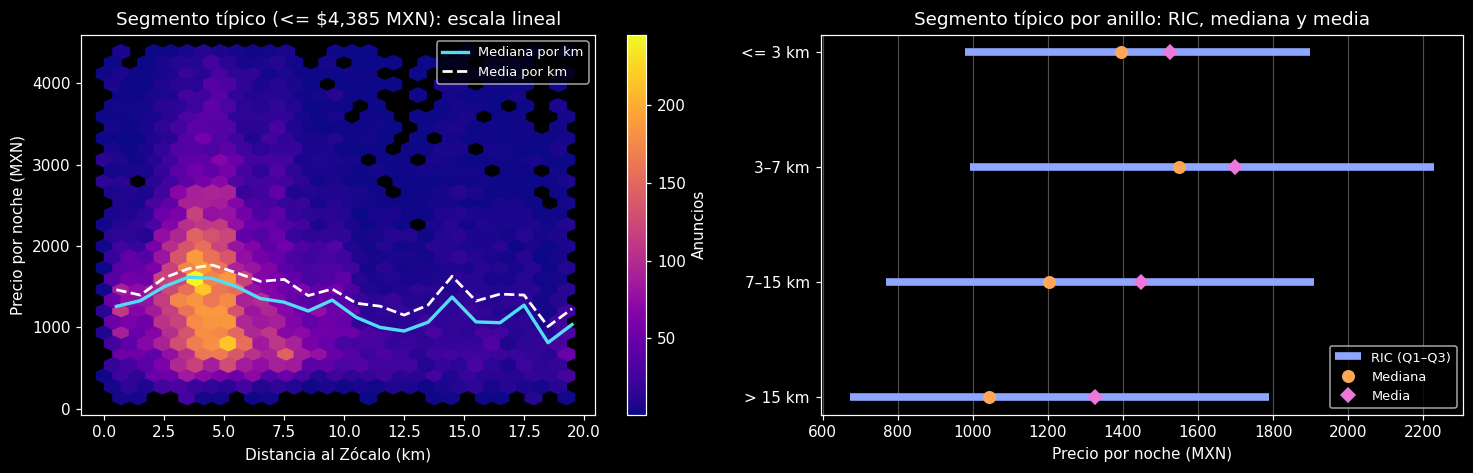

In [ ]:
# --- Paso 3: Escenario complementario alrededor del segmento típico ---
q1_p, q3_p = df_p2["precio"].quantile([0.25, 0.75])
umbral_alto = q3_p + 1.5 * (q3_p - q1_p)

df_tipico = df_p2[df_p2["precio"] <= umbral_alto].copy()
df_alto   = df_p2[df_p2["precio"] >  umbral_alto].copy()

print(f"Frontera descriptiva (Q3 + 1.5*RIC): ${umbral_alto:,.2f} MXN")

# Comparativa de escenarios: base completa vs. segmento típico vs. segmento alto
comp_seg = pd.DataFrame([
    {
        "escenario": nombre,
        "n": len(sub),
        "%": len(sub) / len(df_p2) * 100,
        "dist_mediana_km": sub["dist_centro_km"].median(),
        "media": sub["precio"].mean(),
        "mediana": sub["precio"].median(),
        "desv_std": sub["precio"].std(ddof=1),
        "pearson_r": sub["dist_centro_km"].corr(sub["precio"], method="pearson"),
        "spearman_rho": sub["dist_centro_km"].corr(sub["precio"], method="spearman"),
    }
    for nombre, sub in [
        ("Base completa (analisis)", df_p2),
        (f"Segmento típico (<= ${umbral_alto:,.0f})", df_tipico),
        (f"Segmento alto (> ${umbral_alto:,.0f})", df_alto),
    ]
]).round(2)
display(comp_seg)

# Resúmenes en base completa (reutilizando resumen_grupo)
res_cut_com = resumen_grupo(df_p2, "anillo_centro")
print("--- Base Completa por anillo urbano ---")
display(res_cut_com)

# Resúmenes en el segmento típico (reutilizando resumen_grupo)
res_cut_tip = resumen_grupo(df_tipico, "anillo_centro")
print("--- Segmento típico por anillo urbano ---")
display(res_cut_tip)

# Resúmenes en el segmento alto (reutilizando resumen_grupo)
res_cut_alt = resumen_grupo(df_alto, "anillo_centro")
print("--- Segmento Alto por anillo urbano ---")
display(res_cut_alt)

# Visualización en escala lineal (2 paneles)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

# Panel 1: Hexbin lineal + mediana y media por km
hb = axes[0].hexbin(df_tipico["dist_centro_km"].clip(upper=df_tipico["dist_centro_km"].quantile(0.99)),
                    df_tipico["precio"], gridsize=28, mincnt=1, cmap="plasma")
fig.colorbar(hb, ax=axes[0], label="Anuncios")

bins_km = np.arange(0, 21, 1)
sub_t = df_tipico[df_tipico["dist_centro_km"] <= 20]
perf = (sub_t.groupby(pd.cut(sub_t["dist_centro_km"], bins_km), observed=False)["precio"]
        .agg(mediana="median", media="mean", n="size"))
perf["km"] = bins_km[:-1] + 0.5
perf = perf[perf["n"] >= 15]

axes[0].plot(perf["km"], perf["mediana"], color=COL["cyan"], lw=2.2, label="Mediana por km")
axes[0].plot(perf["km"], perf["media"],   color="white",    lw=1.8, ls="--", label="Media por km")
axes[0].set(title=f"Segmento típico (<= ${umbral_alto:,.0f} MXN): escala lineal",
            xlabel="Distancia al Zócalo (km)", ylabel="Precio por noche (MXN)")
axes[0].legend(fontsize=8.5)

# Panel 2: Convergencia de media y mediana por anillo
for i, (anillo, fila) in enumerate(res_cut_tip.iterrows()):
    axes[1].hlines(i, fila["q1"], fila["q3"], color=COL["azul"], lw=5, label="RIC (Q1–Q3)" if i == 0 else "")
    axes[1].plot(fila["mediana"], i, "o", color=COL["naranja"], ms=7.5, label="Mediana" if i == 0 else "")
    axes[1].plot(fila["media"],   i, "D", color=COL["rosa"],    ms=6.5, label="Media"   if i == 0 else "")
axes[1].set_yticks(range(len(res_cut_tip)), res_cut_tip.index)
axes[1].invert_yaxis()
axes[1].set(title="Segmento típico por anillo: RIC, mediana y media", xlabel="Precio por noche (MXN)")
axes[1].grid(axis="x", alpha=0.3)
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()

**Observaciones**

- **Justificación de la frontera:** Se utiliza el límite superior del rango intercuartílico (**\$4,384.81 MXN**) por ser un criterio robusto que no depende de la media contaminada por la cola alta.
- **Convergencia de media, mediana y caída en dispersión:** Al acotar al `Segmento típico`, la desviación estándar (`desv_std`) cae **69.4%** (de **\$2,897.34** a **\$887.48 MXN**) y la brecha global entre media y mediana se reduce de **\$603.35** a solo **\$173.36 MXN** (**\$1,590.36** vs. **\$1,417.00**). El efecto más claro ocurre en **> 15 km**: en la base completa su media (**\$2,045.00**) quedaba inflada por los **148** anuncios del `Segmento alto` (media **\$9,392.68**, mediana **\$6,925.00**); en el `Segmento típico` la media baja **35.2%** a **\$1,325.31** (brecha de **\$281.31**), logrando que media y mediana desciendan en el mismo orden tras el pico de **3–7 km** (**\$1,549.00** → **\$1,204.25** → **\$1,044.00**).
- **Correlaciones relevantes:**
  - *Efecto global:* En el `Segmento típico`, Pearson converge con Spearman (**r = -0.10**, **ρ = -0.11**), evidenciando una relación negativa consistente pero **débil**; en el `Segmento alto`, la asociación es prácticamente nula (**r = 0.03**, **ρ = 0.02**), es decir, los alojamientos de alto valor no se abaratan al alejarse del Zócalo.
  - *Cambios de signo por tramo:* En **<= 3 km** la correlación es positiva en los tres escenarios (**ρ = +0.12** base, **+0.10** típico, **+0.18** alto), confirmando que salir del primer cuadro encarece la tarifa hacia la franja de **3–7 km**. En **7–15 km** aparece la pendiente negativa más clara del mercado típico (**ρ = -0.10**), mientras que el segmento alto muestra signo opuesto (**ρ = +0.15**), reforzando que la oferta cara sigue otra lógica espacial.
- **Lectura rápida de las gráficas:** En el *hexbin* (escala lineal), retirar el **7.32%** superior permite leer precios directos en pesos: la media y la mediana viajan casi paralelas, se distinguen **dos núcleos de densidad** entre **3 y 5.5 km** (cerca de **\$1,600** y **\$800–\$900 MXN**) y persiste un repunte local hacia **14.5 km**. En el gráfico de intervalos por anillo, la media (rombo rojo) ya queda centrada dentro de cada `RIC` y replica exactamente el orden descendente de la mediana a partir de **3–7 km**.


Incluso en el segmento típico la correlación global es muy débil (`ρ = -0.11`), esto tal vez se pueda explicar gracias a que los anillos atrapan una distribución de anuncios (la mancha urbana de la CDMX y el zócalo como punto de vista) que es muy asimétrica. Recordemos que al tomar anillos (radios) estamos viendo al mismo tiempo para todas las direcciones. En este punto podemos concluir o hacernos una última pregunta. ¿Es posible segmentar la dimensión del espacio de otra forma?, Al observar el mapa cartesiano de los anuncios, podemos pensar en puntos cardinales y por lo tanto en cuadrantes. Verificamos a continuación si la relación distancia–precio cambia según la **dirección cardinal** (Poniente vs. Oriente y cuatro cuadrantes).

#### 4.2.4. Dirección cardinal: ¿importa más hacia dónde se aleja el alojamiento que cuántos kilómetros?

Dividimos los anuncios en cuatro cuadrantes ortogonales respecto al Zócalo (`Norponiente`, `Surponiente`, `Nororiente`, `Suroriente`) y en dos sectores (`Poniente` vs. `Oriente`) para evaluar si la baja correlación radial se debe a que distintas direcciones de la ciudad presentan niveles tarifarios o pendientes opuestas.

--- Concentración del segmento alto por sector (base completa) ---


,anuncios,n_alto,tasa_alto_pct,part_alto_pct
sector_eo,,,,
Oriente (E),3156,100,3.17,4.91
Poniente (W),24664,1937,7.85,95.09


--- Segmento típico por cuadrante cardinal ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
cuadrante,,,,,,,,,,
Norponiente (NW),"5,382.00",20.87,4.12,"1,632.77",987.68,"1,487.17","2,083.25","1,095.57",145.60,0.13
Surponiente (SW),"17,345.00",67.27,5.00,"1,652.11",954.00,"1,490.90","2,167.00","1,213.00",161.21,-0.18
Nororiente (NE),929.00,3.60,4.79,"1,042.10",649.00,898.00,"1,288.00",639.00,144.10,-0.21
Suroriente (SE),"2,127.00",8.25,6.90,"1,218.92",687.92,"1,000.00","1,522.00",834.08,218.92,-0.13


--- Segmento típico: Poniente vs. Oriente ---


,anuncios,%,dist_mediana_km,media,q1,mediana,q3,RIC,brecha_media_med,spearman_rho
sector_eo,,,,,,,,,,
Poniente (W),"22,727.00",88.15,4.90,"1,647.53",960.00,"1,490.00","2,148.00","1,188.00",157.53,-0.10
Oriente (E),"3,056.00",11.85,5.85,"1,165.17",674.00,969.16,"1,439.75",765.75,196.00,-0.11


--- Precio mediano (MXN): Cuadrante × Anillo (segmento típico) ---


anillo_centro,<= 3 km,3–7 km,7–15 km,> 15 km
cuadrante,,,,
Norponiente (NW),"1,410.34","1,481.76","1,800.00",NaN
Surponiente (SW),"1,466.10","1,633.75","1,201.00","1,100.00"
Nororiente (NE),"1,137.66",835.00,910.00,NaN
Suroriente (SE),978.00,"1,200.00",865.33,847.00


--- Tamaño muestral (n): Cuadrante × Anillo ---


anillo_centro,<= 3 km,3–7 km,7–15 km,> 15 km
cuadrante,,,,
Norponiente (NW),1974,2339,1069,0
Surponiente (SW),1971,10252,3928,1194
Nororiente (NE),198,596,135,0
Suroriente (SE),253,836,721,317


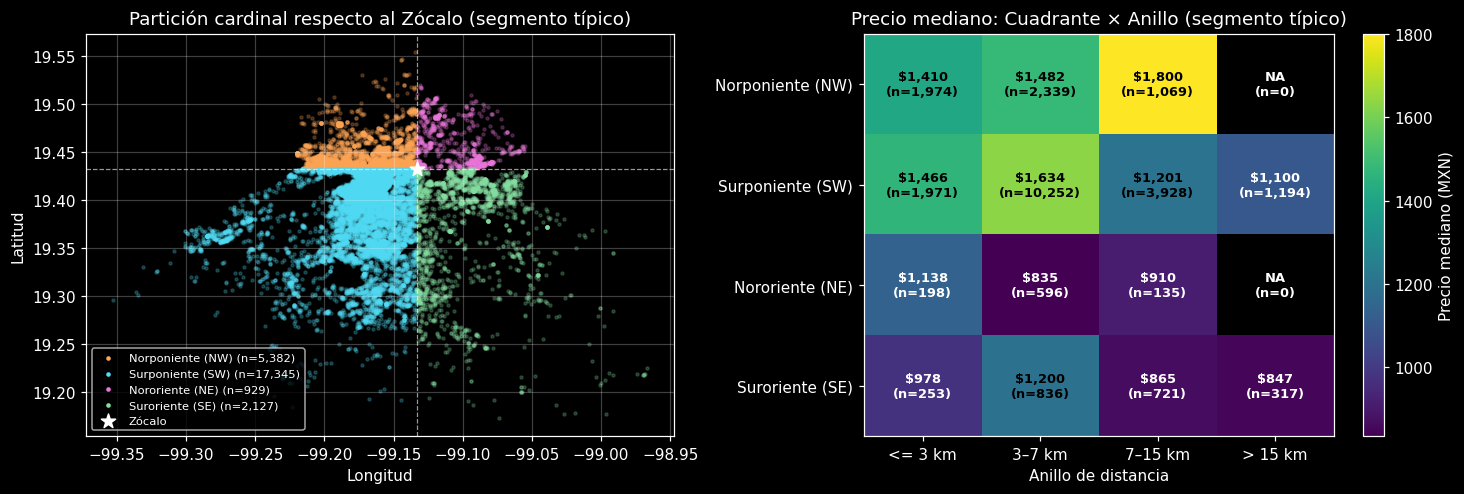

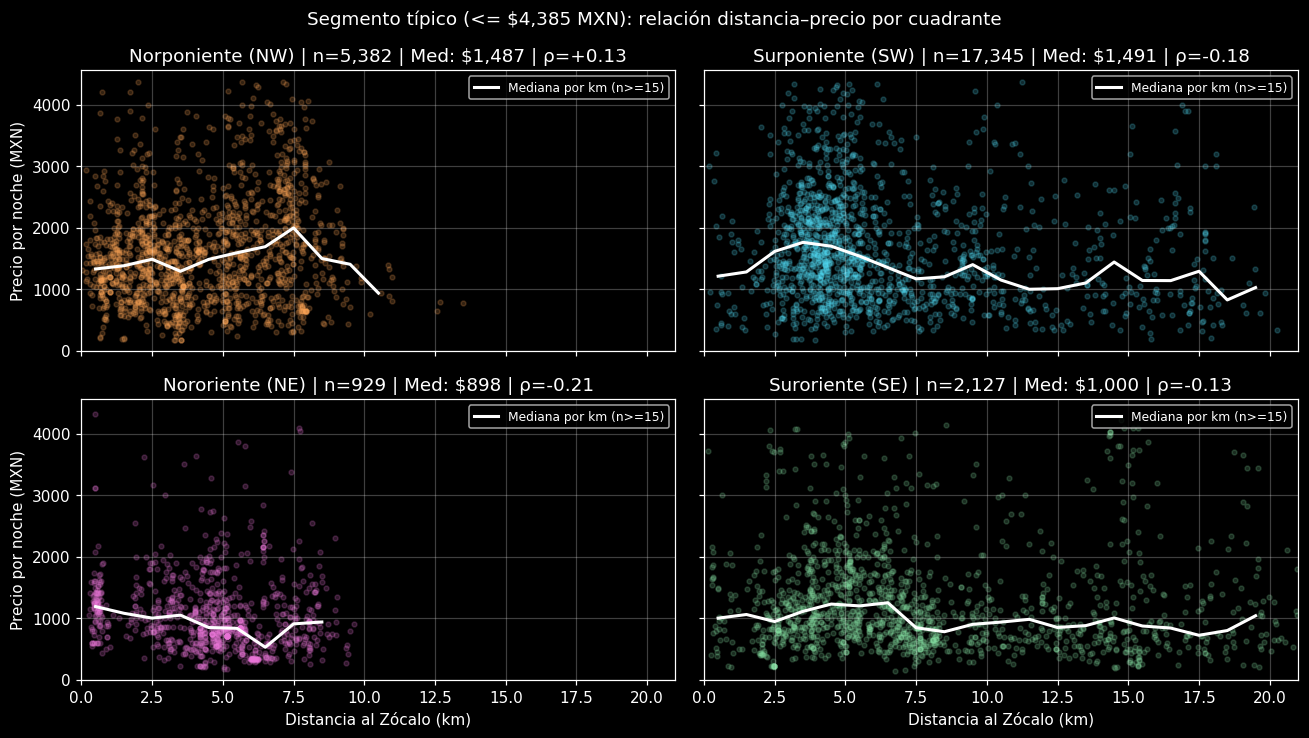

In [ ]:
# --- Paso 4: Hipótesis direccional (cuadrantes cardinales respecto al Zócalo) ---
ORDEN_CUAD = ["Norponiente (NW)", "Surponiente (SW)", "Nororiente (NE)", "Suroriente (SE)"]
COLORES_CUAD = {
    "Norponiente (NW)": COL["naranja"],
    "Surponiente (SW)": COL["cyan"],
    "Nororiente (NE)": COL["rosa"],
    "Suroriente (SE)": COL["verde"],
}

def asignar_cuadrante(df):
    norte = df["latitude"] >= LAT_ZOCALO
    oeste = df["longitude"] < LON_ZOCALO
    cuad = np.select(
        [norte & oeste, (~norte) & oeste, norte & (~oeste), (~norte) & (~oeste)],
        ORDEN_CUAD,
        default="",
    )
    sector = np.where(oeste, "Poniente (W)", "Oriente (E)")
    return df.assign(cuadrante=cuad, sector_eo=sector)

df_p2_c   = asignar_cuadrante(df_p2)
df_tip_c  = asignar_cuadrante(df_tipico)

# Distribución del segmento alto (> umbral) por sector Poniente vs. Oriente (base completa)
res_alto_eo = (
    df_p2_c.assign(es_alto=df_p2_c["precio"] > umbral_alto)
    .groupby("sector_eo")
    .agg(anuncios=("precio", "size"), n_alto=("es_alto", "sum"), tasa_alto_pct=("es_alto", lambda s: s.mean() * 100))
    .assign(part_alto_pct=lambda d: d["n_alto"] / d["n_alto"].sum() * 100)
    .round(2)
)
print("--- Concentración del segmento alto por sector (base completa) ---")
display(res_alto_eo)

# Resumen bivariado por cuadrante y por Poniente vs. Oriente (segmento típico)
res_cuad = resumen_grupo(df_tip_c, "cuadrante").reindex(ORDEN_CUAD)
res_eo   = resumen_grupo(df_tip_c, "sector_eo").reindex(["Poniente (W)", "Oriente (E)"])

print("--- Segmento típico por cuadrante cardinal ---")
display(res_cuad)
print("--- Segmento típico: Poniente vs. Oriente ---")
display(res_eo)

# Matriz Cuadrante × Anillo (mediana y conteo n en segmento típico)
mat_med = df_tip_c.pivot_table(index="cuadrante", columns="anillo_centro", values="precio",
                               aggfunc="median", observed=False).reindex(index=ORDEN_CUAD, columns=ORDEN_ANILLOS).round(2)
mat_n   = df_tip_c.pivot_table(index="cuadrante", columns="anillo_centro", values="precio",
                               aggfunc="size", observed=False).reindex(index=ORDEN_CUAD, columns=ORDEN_ANILLOS)
print("--- Precio mediano (MXN): Cuadrante × Anillo (segmento típico) ---")
display(mat_med)
print("--- Tamaño muestral (n): Cuadrante × Anillo ---")
display(mat_n)

# Figura A: Mapa de cuadrantes + Heatmap Cuadrante × Anillo
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

for c in ORDEN_CUAD:
    sub = df_tip_c[df_tip_c["cuadrante"] == c]
    axes[0].scatter(sub["longitude"], sub["latitude"], s=4, alpha=0.22,
                    color=COLORES_CUAD[c], label=f"{c} (n={len(sub):,})")
axes[0].axhline(LAT_ZOCALO, color="white", ls="--", lw=0.8, alpha=0.6)
axes[0].axvline(LON_ZOCALO, color="white", ls="--", lw=0.8, alpha=0.6)
axes[0].scatter([LON_ZOCALO], [LAT_ZOCALO], s=95, marker="*", color="white", zorder=5, label="Zócalo")
axes[0].set(title="Partición cardinal respecto al Zócalo (segmento típico)", xlabel="Longitud", ylabel="Latitud")
axes[0].grid(alpha=0.25)
leg = axes[0].legend(loc="lower left", fontsize=7.5)
for h in leg.legend_handles:
    h.set_alpha(1)   # que los puntos de la leyenda se vean sólidos

vals = mat_med.to_numpy(dtype=float)
im = axes[1].imshow(vals, cmap="viridis", aspect="auto")
axes[1].set_xticks(range(len(ORDEN_ANILLOS)), ORDEN_ANILLOS)
axes[1].set_yticks(range(len(ORDEN_CUAD)), ORDEN_CUAD)
umbral_txt = np.nanmedian(vals)
for i in range(len(ORDEN_CUAD)):
    for j in range(len(ORDEN_ANILLOS)):
        v, n_c = mat_med.iloc[i, j], int(mat_n.iloc[i, j])
        txt = f"${v:,.0f}\n(n={n_c:,})" if pd.notna(v) else "NA\n(n=0)"
        axes[1].text(j, i, txt, ha="center", va="center", fontsize=8.5, fontweight="bold",
                     color="black" if (pd.notna(v) and v > umbral_txt) else "white")
fig.colorbar(im, ax=axes[1], label="Precio mediano (MXN)")
axes[1].set(title="Precio mediano: Cuadrante × Anillo (segmento típico)", xlabel="Anillo de distancia")

plt.tight_layout()
plt.show()

# Figura B: Facetas 2×2 (mismas escalas) — Distancia vs. Precio por cuadrante
bins_km = np.arange(0, 21, 1)
fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), sharex=True, sharey=True)

for ax, c in zip(axes.flat, ORDEN_CUAD):
    sub = df_tip_c[df_tip_c["cuadrante"] == c]
    muestra = sub.sample(n=min(1500, len(sub)), random_state=2026)
    ax.scatter(muestra["dist_centro_km"], muestra["precio"], s=10, alpha=0.20, color=COLORES_CUAD[c])

    sub_t = sub[sub["dist_centro_km"] <= 20]
    perf = (sub_t.groupby(pd.cut(sub_t["dist_centro_km"], bins_km), observed=False)["precio"]
            .agg(mediana="median", n="size").reset_index())
    perf["km"] = bins_km[:-1] + 0.5
    perf = perf[perf["n"] >= 15]
    ax.plot(perf["km"], perf["mediana"], color="white", lw=2.0, label="Mediana por km (n>=15)")

    rho = res_cuad.loc[c, "spearman_rho"]
    med = res_cuad.loc[c, "mediana"]
    ax.set_title(f"{c} | n={len(sub):,} | Med: ${med:,.0f} | ρ={rho:+.2f}")
    ax.set_xlim(0, 21)
    ax.set_ylim(0, umbral_alto * 1.04)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right", fontsize=8)

for ax in axes[1, :]:
    ax.set_xlabel("Distancia al Zócalo (km)")
for ax in axes[:, 0]:
    ax.set_ylabel("Precio por noche (MXN)")
fig.suptitle(f"Segmento típico (<= ${umbral_alto:,.0f} MXN): relación distancia–precio por cuadrante")
plt.tight_layout()
plt.show()

# Verificación final de integridad sobre `analisis`
assert analisis.shape == (27820, 38), "Alerta: se modificó el DataFrame `analisis`."

**Observaciones**

- **Brecha Poniente vs. Oriente:** El Poniente (W) concentra el **88.15%** del segmento típico (**22,727** anuncios) y el **95.09%** del segmento alto (**1,937** de **2,037**, tasa de **7.85%** frente a **3.17%** en Oriente (E)), con una mediana **53.7%** superior (**\$1,490.00** vs. **\$969.16 MXN**).
- **Confirmación de correlaciones opuestas:** Se confirma que la baja correlación global (**ρ = -0.10** en Poniente y **-0.11** en Oriente) resulta de pendientes contrarias entre cuadrantes. Mientras Surponiente (SW) (**ρ = -0.18**), Nororiente (NE) (**ρ = -0.21**) y Suroriente (SE) (**ρ = -0.13**) bajan al alejarse del Zócalo, **Norponiente (NW) invierte la relación `ρ = +0.13**, subiendo de **\$1,410.34** (<= 3 km) a **\$1,481.76** (3–7 km) hasta alcanzar el máximo de toda la matriz en **7–15 km (\$1,800.00, n = 1,069)**.
- **Diferencia a igual distancia:** En el mismo anillo **3–7 km**, SW (**\$1,633.75**) es **95.7%** más caro que NE (**\$835.00**); en **7–15 km**, NW (**\$1,800.00**) supera en **108.0%** a SE (**\$865.33**).

#### 4.2.5. Respuesta a la pregunta

En los **27,820** anuncios activos de `analisis`, **no existe una relación lineal ni monótona simple entre `dist_centro_km` y `precio`** (**r = -0.01** en pesos; **r = -0.08** en `log_precio`; **ρ = -0.08**): alejarse del Zócalo no abarata las tarifas de forma uniforme.

- **Consistencia en el mercado típico:** Al acotar el **92.68%** central (`<= $4,384.81 MXN`, **n = 25,783**), la dispersión cae **69.4%**, desaparece el desfase de la media en **`> 15 km`** (**\$2,045.00** → **\$1,325.31**) y la correlación sigue siendo débil (**r = -0.10**, **ρ = -0.11**), mientras el segmento alto (**7.32%**) no muestra relación con la distancia (**ρ = 0.02**).

- **Predominio de la dirección cardinal:** Importa más hacia dónde se ubica el inmueble que cuántos kilómetros se aleja del Zócalo; el **Poniente** cobra **53.7%** más en mediana que el **Oriente** y `Norponiente (NW)` se encarece con la distancia (**ρ = +0.13**), compensando parcialmente la caída del resto de la ciudad.

### 4.3. ¿Qué tanto se relaciona el precio con las características del alojamiento: modalidad, capacidad y número de recámaras?

#### 4.3.1. Precio por modalidad

Primero comparamos las cuatro modalidades. **Esto se ve más a detalle en la sección 4.1.**

In [ ]:
def cuartiles(grupos):
    """Número de anuncios, mediana, cuartiles y RIC del precio para cada grupo."""
    tabla = grupos["precio"].agg(
        anuncios="size", mediana="median",
        q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
    tabla["ric"] = tabla["q3"] - tabla["q1"]
    return tabla

cuartiles(analisis.groupby("modalidad")).sort_values("mediana", ascending=False)

,anuncios,mediana,q1,q3,ric
modalidad,,,,,
Habitación de hotel,71,"2,088.00","1,298.50","6,290.50","4,992.00"
Alojamiento completo,18601,"1,829.00","1,325.00","2,693.00","1,368.00"
Habitación privada,8907,849.00,608.00,"1,249.50",641.50
Habitación compartida,241,400.00,283.50,704.00,420.50


La modalidad marca una diferencia grande. Un alojamiento completo tiene una mediana de \$1,829, más del doble que una habitación privada (\$849) y más de cuatro veces una habitación compartida (\$400). Las habitaciones de hotel tienen la mediana más alta (\$2,088), pero son solo 71 anuncios con un rango intercuartílico muy amplio (\$4,992), así que no les damos mucho peso.

#### 4.3.2. Precio según la capacidad

Revisamos cómo cambia el precio con la capacidad en las dos modalidades que tienen datos suficientes: los alojamientos completos y las habitaciones privadas, que juntas suman el 98.9 % de la base. En una habitación privada, la capacidad indica cuántas personas caben en esa habitación. Además del precio total calculamos el precio por huésped, para ver si los alojamientos grandes resultan más baratos por persona. Nos limitamos a capacidades de 1 a 8 huéspedes.

In [ ]:

MODALIDADES_CAPACIDAD = [
    "Alojamiento completo",
    "Habitación privada",
    "Habitación compartida",
    "Habitación de hotel"
]

por_capacidad = (
    analisis[
        (analisis["modalidad"].isin(MODALIDADES_CAPACIDAD))
        & (analisis["capacidad"].between(1, 8))
    ]
    .groupby(["modalidad", "capacidad"])
    .agg(
        anuncios=("precio", "size"),
        mediana_precio=("precio", "median"),
        mediana_por_huesped=("precio_huesped", "median")
    )
)

por_capacidad.unstack("modalidad").round(0)


anuncios                                            \
modalidad Alojamiento completo Habitación compartida Habitación de hotel   
capacidad                                                                  
1                       172.00                153.00                4.00   
2                     5,676.00                 43.00               44.00   
3                     2,222.00                  5.00                7.00   
4                     5,385.00                 11.00                8.00   
5                     1,386.00                  4.00                 NaN   
6                     1,986.00                 14.00                1.00   
7                       336.00                   NaN                 NaN   
8                       566.00                  5.00                1.00   

                                   mediana_precio                        \
modalidad Habitación privada Alojamiento completo Habitación compartida   
capacidad                                                                 
1                   2,029.00               892.00                362.00   
2                   5,585.00             1,500.00                800.00   
3                     461.00             1,593.00                400.00   
4                     583.00             1,918.00                550.00   
5                      80.00             1,962.00              1,304.00   
6                      79.00             2,485.00                374.00   
7                      15.00             2,647.00                   NaN   
8                      22.00             3,408.00                345.00   

                                                  mediana_por_huesped  \
modalidad Habitación de hotel Habitación privada Alojamiento completo   
capacidad                                                               
1                      486.00             624.00               892.00   
2                    1,720.00             884.00               750.00   
3                    1,693.00             995.00               531.00   
4                    5,058.00           1,308.00               480.00   
5                         NaN           1,323.00               392.00   
6                    5,992.00           1,480.00               414.00   
7                         NaN           1,545.00               378.00   
8                    4,176.00           1,965.00               426.00   

                                                                        
modalidad Habitación compartida Habitación de hotel Habitación privada  
capacidad                                                               
1                        362.00              486.00             624.00  
2                        400.00              860.00             442.00  
3                        133.00              564.00             332.00  
4                        138.00            1,265.00             327.00  
5                        261.00                 NaN             265.00  
6                         62.00              999.00             247.00  
7                           NaN                 NaN             221.00  
8                         43.00              522.00             246.00

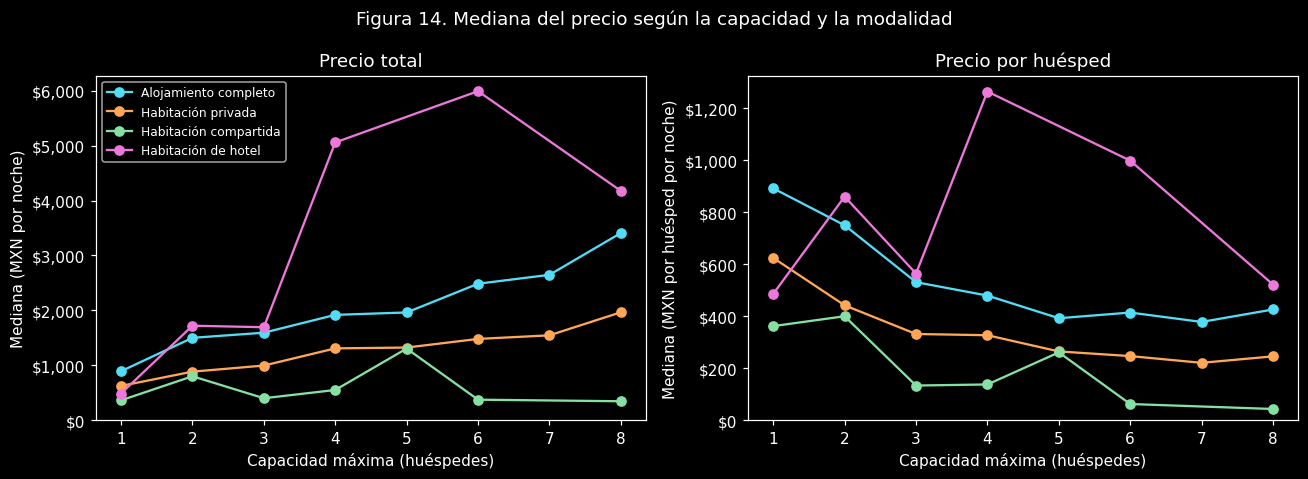

In [ ]:

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True)

for modalidad in MODALIDADES_CAPACIDAD:
    if modalidad not in por_capacidad.index.get_level_values("modalidad"):
        continue

    d = por_capacidad.loc[modalidad]
    color = COLOR_MODALIDAD[modalidad]

    ejes[0].plot(
        d.index, d["mediana_precio"], "o-",
        color=color, label=modalidad
    )
    ejes[1].plot(
        d.index, d["mediana_por_huesped"], "o-",
        color=color, label=modalidad
    )

ejes[0].set(
    title="Precio total",
    xlabel="Capacidad máxima (huéspedes)",
    ylabel="Mediana (MXN por noche)"
)

ejes[1].set(
    title="Precio por huésped",
    xlabel="Capacidad máxima (huéspedes)",
    ylabel="Mediana (MXN por huésped por noche)"
)

for ax in ejes:
    ax.set_xticks(range(1, 9))
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda v, _: f"${v:,.0f}")
    )

ejes[0].legend(fontsize=8)

fig.suptitle(
    "Figura 14. Mediana del precio según la capacidad y la modalidad"
)

plt.tight_layout()
guardar("fig14_precio_capacidad.png", fig)



En los **alojamientos completos y las habitaciones privadas**, el precio total aumenta conforme crece la capacidad, mientras que el precio por huésped disminuye. En los alojamientos completos, la mediana pasa de \$1,500 para dos huéspedes a \$3,408 para ocho, mientras que el precio por persona baja de \$750 a \$426. En las habitaciones privadas, el precio total aumenta de \$884 a \$1,965 y el precio por huésped disminuye de \$442 a \$246.

Las **habitaciones compartidas** presentan generalmente los precios más bajos, aunque su comportamiento es irregular. Por ejemplo, la mediana alcanza \$1,304 para cinco huéspedes, pero este resultado se basa en solo cuatro anuncios.

Las **habitaciones de hotel** registran los precios más elevados en algunas capacidades, particularmente cuatro (\$5,058) y seis huéspedes (\$5,992). Sin embargo, estas cifras deben interpretarse con cautela, ya que corresponden a ocho y un anuncio, respectivamente.

En conjunto, **los alojamientos de mayor capacidad tienden a ser más económicos por persona, especialmente en las modalidades de alojamiento completo y habitación privada**. No obstante, este patrón no puede generalizarse con la misma confianza a las habitaciones compartidas y de hotel debido a su menor representación y mayor variabilidad.

**Nota:** El precio por huésped supone ocupación a capacidad máxima. Además, los resultados incluyen grupos con menos de 30 anuncios, por lo que algunas medianas son poco representativas, especialmente en habitaciones de hotel y compartidas, así como en habitaciones privadas para siete y ocho huéspedes.


#### 4.3.3. Correlación con las características del alojamiento

Para resumir la relación del precio con varias características a la vez usamos el **coeficiente de correlación de Spearman**. Mide si una variable tiende a crecer cuando la otra crece, aunque la relación no sea una línea recta, y no se deja dominar por los valores extremos. Toma valores entre $-1$ y $1$; cerca de $0$ indica que no hay una relación monótona.

In [ ]:
# Definimos la lista de las columnas que representan las características del alojamiento
CARACTERISTICAS = ['capacidad', 'recamaras', 'beds', 'review_scores_rating', 'number_of_reviews', 'availability_365']

# Calculamos la correlación utilizando la base completa de análisis
correlaciones = (analisis[['precio', *CARACTERISTICAS]]
 .corr(method='spearman')['precio']
 .drop('precio')
 .rename(index={'capacidad': 'Capacidad (huéspedes)', 'recamaras': 'Recámaras', 'beds': 'Camas', 'review_scores_rating': 'Calificación', 'number_of_reviews': 'Número de reseñas', 'availability_365': 'Días disponibles al año'})
 .sort_values(ascending=False)
 .to_frame('correlación de Spearman (Todos los alojamientos)'))

display(correlaciones)

,correlación de Spearman (Todos los alojamientos)
Capacidad (huéspedes),0.57
Recámaras,0.50
Camas,0.46
Calificación,0.15
Número de reseñas,-0.03
Días disponibles al año,-0.07


Entre los alojamientos completos, las características físicas son las que muestran la asociación más clara con el precio por noche: la capacidad de huéspedes (0.57), el número de recámaras (0.50) y el número de camas (0.46). Son correlaciones positivas de fuerza moderada a fuerte: los alojamientos más grandes tienden a ser notablemente más caros, aunque persisten variaciones individuales. Por otro lado, la calificación general del alojamiento tiene una asociación positiva muy débil con el precio (0.15), mientras que los días disponibles al año (-0.07) y el número de reseñas totales (-0.03) presentan correlaciones prácticamente nulas, lo que indica que estas variables no influyen linealmente en la tarifa asignada por el anfitrión.



### 4.3.4. Respuesta a la pregunta

Las características del alojamiento se relacionan con el precio, principalmente a través de la modalidad y el tamaño.

- **Modalidad.** Es la característica que presenta las diferencias de precio más evidentes. Los alojamientos completos tienen una mediana de \$1,829, frente a \$849 en habitaciones privadas y \$400 en compartidas. Las habitaciones de hotel presentan la mediana más alta (\$2,088), pero su muestra es pequeña (71 anuncios), por lo que el resultado debe interpretarse con cautela.

- **Capacidad.** En los alojamientos completos y las habitaciones privadas, el precio total generalmente aumenta con la capacidad, pero no de forma proporcional. Entre dos y ocho huéspedes, el precio por persona disminuye de \$750 a \$426 en alojamientos completos y de \$442 a \$246 en habitaciones privadas. En las habitaciones compartidas y de hotel el comportamiento es más irregular debido a la menor cantidad de anuncios.

- **Recámaras y camas.** Considerando todas las modalidades, la capacidad presenta la mayor correlación positiva con el precio (0.57), seguida del número de recámaras (0.50) y camas (0.46). Estas asociaciones indican que los alojamientos de mayor tamaño tienden a presentar precios más altos, aunque existen variaciones individuales.

- **Otras variables.** La calificación presenta una correlación positiva débil (0.15), mientras que el número de reseñas (-0.03) y la disponibilidad anual (-0.07) muestran asociaciones prácticamente nulas con el precio.

En resumen, **el precio se relaciona principalmente con la modalidad y las características físicas del alojamiento**. Los espacios de mayor capacidad suelen ser más caros en términos absolutos, pero más económicos por huésped. Sin embargo, existe una variabilidad considerable entre anuncios similares, y los resultados de las modalidades con pocas observaciones deben interpretarse con cautela.


### 4.4. ¿Existe una asociación entre el precio de un alojamiento y su calificación general?

Es un supuesto comun que a mejor precio mejor calidad. Un alojamiento que cobra más proyecta prestigio, y se espera que los huéspedes lo recompensen con mejores reseñas. Pero también puede pasar lo contrario: quien paga más, espera más, y es más fácil decepcionarlo.
Con los datos de Airbnb en la Ciudad de México podemos poner a prueba esa intuición.

Para ello tendremos en cosideración lo siguiente.

1. **Solo anuncios con score rating visible.** Un anuncio sin reseñas no tiene calificación todavía, entonces no se imputa, porque inventaríamos una opinión que ningún huésped dio.
2. **Spearman como medida principal.** Los precios son muy asimétricos y las calificaciones se amontonan arriba. Como con Spearman se comparan posiciones, no es tan sensible a precios extremos. Como contraste, Pearson sobre con precios log.

3. **Reputación bien respaldada.** Una calificación de 5.0 con una sola reseña no es tan significativa para representar la reputación de un alojamiento. Es pertinente que agrupemos los anuncios por número de reseñas por cuantiles y revisamos si la asociación cambia según qué tan respaldada está la calificación.

**Nota**: lo que buscamos es una **asociación**. Aunque la encontremos, NO demuestra que cobrar más **causa** mejor o peor reputación.

In [ ]:
# Celda 1: base y grupos por número de reseñas (cuartiles)
cal = analisis.dropna(subset=["review_scores_rating"]).copy()

#Para crear los grupos, se calculan los cuartiles de la variable "number_of_reviews"
#Así garantizamos que cada grupo tenga aproximadamente el mismo número de anuncios.
c1, c2, c3 = cal["number_of_reviews"].quantile([.25, .5, .75]).astype(int)
cal["nivel_resenas"] = pd.cut(
    cal["number_of_reviews"],
    bins=[0, c1, c2, c3, np.inf],
    labels=[f"1–{c1}", f"{c1+1}–{c2}", f"{c2+1}–{c3}", f"{c3+1} o más"])

print(f"Con calificación: {len(cal):,} de {len(analisis):,} ({100*len(cal)/len(analisis):.1f} %)")

# ¿Los grupos están balanceados y la calificación se comporta distinto en cada uno?
(cal.groupby("nivel_resenas", observed=True)["review_scores_rating"]
    .agg(anuncios="size", mediana="median", media="mean",
         RIC=lambda s: s.quantile(.75) - s.quantile(.25),
         pct_menor_4_5=lambda s: 100 * (s < 4.5).mean())
    .round(2))

Con calificación: 24,350 de 27,820 (87.5 %)


,anuncios,mediana,media,RIC,pct_menor_4_5
nivel_resenas,,,,,
1–9,6303,5.00,4.64,0.50,20.85
10–32,5977,4.83,4.77,0.26,10.06
33–91,6006,4.83,4.80,0.17,4.13
92 o más,6064,4.83,4.81,0.15,2.13


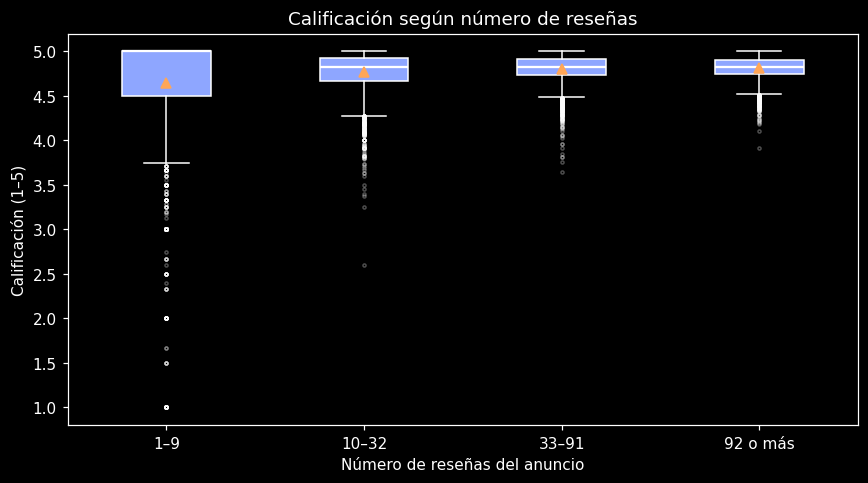

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
grupos_box = [g["review_scores_rating"].to_numpy()
              for _, g in cal.groupby("nivel_resenas", observed=True)]
etiquetas = list(cal["nivel_resenas"].cat.categories)

bp = ax.boxplot(grupos_box, tick_labels=etiquetas, patch_artist=True,
                showmeans=True, medianprops=dict(color="white", linewidth=1.5),
                flierprops=dict(markersize=2, alpha=0.3, markeredgecolor="white"))
for caja in bp["boxes"]:
    caja.set_facecolor(COL["azul"])
ax.set(xlabel="Número de reseñas del anuncio", ylabel="Calificación (1–5)",
       title="Calificación según número de reseñas")
plt.tight_layout()
plt.show()

24,350 de 27,820 anuncios (87.5 %) tienen calificación; el resto no tiene reseñas y queda fuera. Los cuatro grupos por número de reseñas tienen tamaños parecidos (aprox 6,000 cada uno).

- La calificación es alta en todos los grupos: la mediana en todos los grupos es cercana al 5. Parece que el precio no influye para que el precio marque diferencias.
- La media es menor que la mediana, por una cola de calificaciones bajas. Por eso usamos la mediana como medida típica.
- Con pocas reseñas la calificación es poco confiable. De 1–9 a 92 o más reseñas, el RIC baja de 0.50 a 0.15 y los anuncios bajo 4.5 pasan de 20.85 % a 2.13 %.

Por eso tenemos que ver la asociación con el precio **dentro de cada grupo** y no mezclando todos.

#### Asociación entre precio y calificación

Para ver si hay asociación entre el precio y la calificación usaremos los coeficientes de correlación,  ya que resumen en un solo número entre −1 y 1, si ambas variables **suben o bajan juntas** a lo largo de los anuncios.

- **Spearman**. Se usa porque el precio es muy asimétrico y la calificación está acotada en 5 y concentrada a valores altos: al trabajar con posiciones y no con valores, los precios extremos no lo distorsionan.
- **Pearson con precio logaritmico ** . Mide qué tan bien se ajusta una línea recta entre las dos variables. Sirve para verificar que la conclusión no dependa del coeficiente elegido.

**Sobre qué anuncios se calcula.**

- **Todos** los anuncios con calificación: la respuesta general.
- **Cada grupo de número de reseñas:** revisa si el resultado cambia cuando la calificación es menos confiable.

In [ ]:
def asociacion(df):
    d = df[["log_precio", "review_scores_rating"]].dropna()
    return pd.Series({
        "n": len(d),
        "Spearman": d["log_precio"].corr(d["review_scores_rating"], method="spearman"),
        "Pearson": d["log_precio"].corr(d["review_scores_rating"]),
    })

grupos = {"Todos": cal}
for nivel, g in cal.groupby("nivel_resenas", observed=True):
    grupos[nivel] = g

pd.DataFrame({k: asociacion(v) for k, v in grupos.items()}).T.round(3)

,n,Spearman,Pearson
Todos,"24,350.00",0.15,0.11
1–9,"6,303.00",0.11,0.09
10–32,"5,977.00",0.15,0.17
33–91,"6,006.00",0.18,0.21
92 o más,"6,064.00",0.25,0.29


 La asociación entre precio y calificación es **positiva pero débil**: Spearman = 0.15 y Pearson = 0.11 con los 24,350 anuncios. Los anuncios más caros tienden a estar algo mejor calificados, pero el precio explica muy poco de la calificación.

- **La asociación crece con el número de reseñas.** Spearman pasa de 0.11 (1–9 reseñas) a 0.25 (92 o más), y Pearson de 0.09 a 0.29. Cuando la calificación está mejor respaldada, la relación con el precio se ve más clara, aunque sigue siendo débil.
- **Los dos coeficientes coinciden en signo y tendencia**, así que la conclusión no depende del método.
- **El coeficiente global (0.15) queda por debajo del de los grupos con más reseñas.** Mezclar anuncios con calificaciones poco confiables diluye la asociación.

**Limitación.** Que el coeficiente aumente con las reseñas no significa que acumular reseñas fortalezca la relación. Los anuncios con muchas reseñas son también los más antiguos y populares, y pueden diferir en otras características.

#### ¿Se repite el patrón en cada alcaldía?

Hasta ahora vimos una asociación positiva y débil en toda la ciudad (Spearman = 0.15) que crece con el número de reseñas. Falta saber si ese patrón se repite en cada alcaldía o si depende de la ubicación, que es el eje de nuestra pregunta de investigación.

Para ello calculamos el coeficiente de Spearman entre `log_precio` y calificación para cada combinación de **alcaldía × grupo de número de reseñas**, y lo comparamos con el valor global. Vamos a conservar los grupos de reseñas ya que si calculáramos un solo coeficiente por alcaldía, las diferencias entre alcaldías podrían deberse a que unas tienen más anuncios con pocas reseñas.

Es imporntante ver que  cada valor se muestra con su número de anuncios (`n`) ya que si sin menos de 3 no va a ser posible calcular el coeficiente. En dado caso, solo quedan vacías las celdas con menos de 3 anuncios, donde el coeficiente no está definido.

**Nota** Importan los patrones que se repiten en varias alcaldías o grupos, no un valor aislado. Las alcaldías con más anuncios (Cuauhtémoc, Miguel Hidalgo, Benito Juárez) son la referencia más confiable.

In [ ]:
def spearman_celda(g):
    # único requisito: 3 anuncios; con menos, el coeficiente no está definido
    return (g["log_precio"].corr(g["review_scores_rating"], method="spearman")
            if len(g) >= 3 else np.nan)

cruce = cal.groupby(["alcaldia", "nivel_resenas"], observed=True)
rho = cruce.apply(spearman_celda, include_groups=False).unstack()

# n_celda se alinea con rho
n_celda = (cruce.size().unstack()
              .reindex(index=rho.index, columns=rho.columns)
              .fillna(0).astype(int))

orden = n_celda.sum(axis=1).sort_values(ascending=False).index   # alcaldías grandes arriba
rho, n_celda = rho.loc[orden], n_celda.loc[orden]

print("Forma de rho:", rho.shape, "| forma de n_celda:", n_celda.shape)
print(f"Celdas con coeficiente: {int(rho.notna().sum().sum())} de {rho.size}")
print(f"Celdas con menos de 30 anuncios: {int((n_celda < 30).sum().sum())}")
rho.round(2)

Forma de rho: (16, 4) | forma de n_celda: (16, 4)
Celdas con coeficiente: 62 de 64
Celdas con menos de 30 anuncios: 14


nivel_resenas,1–9,10–32,33–91,92 o más
alcaldia,,,,
Cuauhtémoc,0.17,0.21,0.29,0.35
Miguel Hidalgo,0.06,0.15,0.18,0.26
Benito Juárez,0.07,0.13,0.11,0.16
Coyoacán,0.10,0.12,0.11,0.13
Venustiano Carranza,0.18,0.35,0.39,0.28
Álvaro Obregón,0.03,-0.02,0.01,-0.00
Tlalpan,0.22,-0.05,0.15,0.04
Iztacalco,0.01,0.28,0.20,0.31
Gustavo A. Madero,0.08,0.16,0.28,0.65


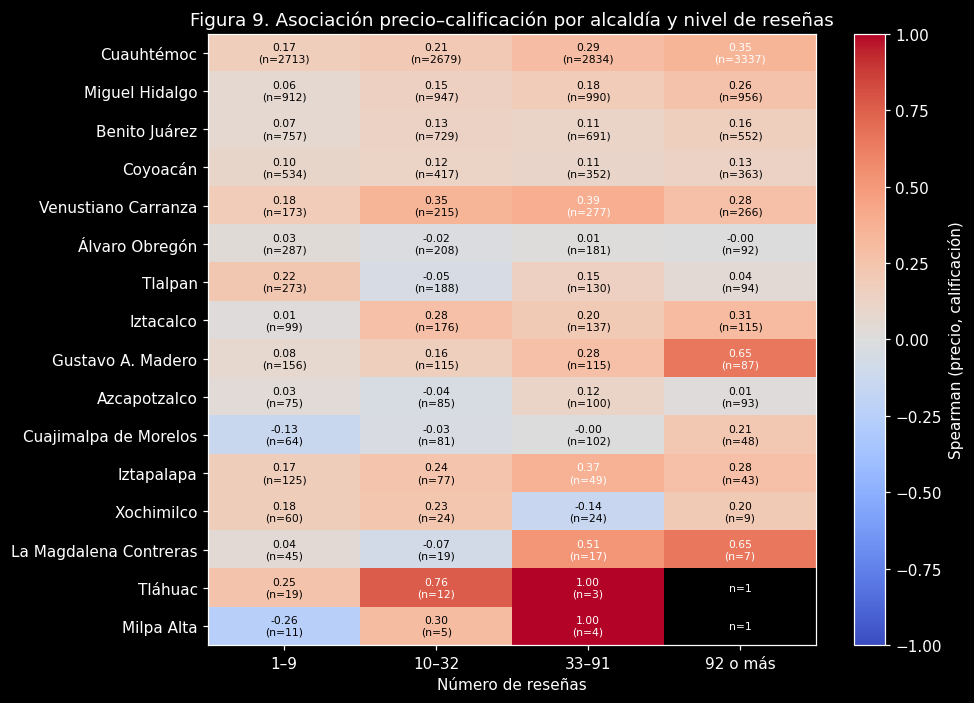

In [ ]:
valores, conteos = rho.to_numpy(), n_celda.to_numpy()

fig, ax = plt.subplots(figsize=(9, 6.5))
im = ax.imshow(np.ma.masked_invalid(valores), cmap=MAPA_DIVERGENTE,
               vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(valores.shape[1])); ax.set_xticklabels(rho.columns)
ax.set_yticks(range(valores.shape[0])); ax.set_yticklabels(rho.index)

for i in range(valores.shape[0]):
    for j in range(valores.shape[1]):
        v, k = valores[i, j], conteos[i, j]
        texto = f"n={k}" if np.isnan(v) else f"{v:.2f}\n(n={k})"
        ax.text(j, i, texto, ha="center", va="center", fontsize=7,
                color="black" if (not np.isnan(v) and abs(v) < 0.35) else "white")

fig.colorbar(im, ax=ax, label="Spearman (precio, calificación)")
ax.set(xlabel="Número de reseñas",
       title="Figura 9. Asociación precio–calificación por alcaldía y nivel de reseñas")
plt.tight_layout(); plt.show()

Como vemos en el mapa de calor, el patrón sigue siendo positivo y débil.

Hay que tener en cuenta que:
- **Alcaldías grandes (más de 500 anuncios):** el coeficiente es positivo en todas. En Cuauhtémoc, Miguel Hidalgo y Benito Juárez **crece con el número de reseñas** (por ejemplo, Cuauhtémoc de 0.17 a 0.35). En Coyoacán se mantiene estable (0.10 a 0.13).
- **Sin asociación:** Álvaro Obregón se mantiene en 0 en los cuatro grupos (entre −0.02 y 0.03, con 92 a 287 anuncios por celda). Azcapotzalco también ronda 0, salvo un 0.12 en el grupo de 33–91.
- **Valores altos:** Gustavo A. Madero llega a 0.65 con 92 o más reseñas (n = 87) y Venustiano Carranza a 0.39. Son celdas medianas, pero el resultado es más llamativo que en las alcaldías grandes.
- **Valores extremos en celdas pequeñas:** los 1.00 de Tláhuac y Milpa Alta (n = 3 y 4) y los 0.76 y 0.65 de Tláhuac y La Magdalena Contreras (n = 12 y 7) no nos pueden dar una interpretación concisa ya que cuenta con tan pocos anuncios que el coeficiente es inestable.

**Conclusión.** En la ciudad, los alojamientos más caros tienden a estar algo mejor calificados, sobre todo cuando la calificación está respaldada por muchas reseñas. Pero el precio no dice nada de la calificación en todas partes (Álvaro Obregón) y la relación es más marcada en unas alcaldías que en otras.

**Consideraciones**

- Unas 14 de las 64 celdas tienen menos de 30 anuncios y sus valores son poco confiables (confírmenlo con su conteo).
- La tabla mezcla modalidades: una alcaldía con más habitaciones privadas puede tener un coeficiente distinto por esa razón y no por su ubicación.
- Es asociación, no causalidad.


### 4.5. ¿Los anfitriones comerciales (con 10 o más anuncios) cobran distinto que los particulares dentro de una misma alcaldía y tipo de alojamiento?

Comparar directamente el precio de ambos grupos podría ser engañoso ya que  si los anfitriones
comerciales tienen la mayoría de sus anuncios en alcaldías caras o en alojamientos
completos, su precio sería más alto por *dónde* y *qué* ofrecen, no necesariamente porque
cobren más que un particular con un alojamiento similar. Por ello seguimos cuatro puntos de análisis:

1. **Describimos** cómo se compone cada grupo (modalidad y ubicación).
2. **Comparamos** precios dentro de cada combinación de alcaldía y modalidad.
3. **Resumimos** la diferencia, sin ponderar y ponderada por número de anuncios.

Usamos la mediana en lugar del promedio porque la distribución del precio es muy
asimétrica, unos pocos anuncios con precios muy altos elevarían el promedio, mientras que
la mediana representa mejor el precio de un anuncio típico y es menos sensible a
valores extremos.


**Nota sobre la definición de anfitrión comercial.** No existe un umbral estándar en la
literatura pues se han usado 2 o más anuncios (Li et al., 2015), 3 o más (Schneiderman, 2014)
y valores como 10 y 20 (Ke, 2017). Seguimos a Ke (2017), quien analiza el mercado
completo de Airbnb y examina umbrales de 10 y 20 anuncios para identificar a operadores
de gran escala, cuya actividad difícilmente corresponde a una persona que renta su
propia vivienda. El autor advierte que el número de anuncios por anfitrión varía en
varios órdenes de magnitud, por lo que cualquier umbral es una decisión metodológica y
no una frontera natural.

*Referencia:* Ke, Q. (2017). *Sharing Means Renting? An Entire-marketplace Analysis of
Airbnb*. arXiv:1701.01645. https://arxiv.org/abs/1701.01645

#### 4.5.1. ¿Qué y dónde ofrece cada grupo?

In [ ]:
COM, PAR = "Comercial (10+)", "Particular (<10)"
COLORES = {COM: "#C0392B", PAR: "#2E86C1"}

analisis["grupo_anfitrion"] = np.where(analisis["anuncios_anfitrion"] >= 10, COM, PAR)

composicion = analisis.groupby("grupo_anfitrion").agg(
    anuncios=("id", "count"),
    anfitriones=("host_id", "nunique"),
    precio_mediano=("precio", "median"),
)
composicion["anuncios por anfitrión"] = (composicion["anuncios"] / composicion["anfitriones"]).round(1)
composicion["% de anuncios"] = (composicion["anuncios"] / len(analisis) * 100).round(1)

diferencia_bruta = (composicion.loc[COM, "precio_mediano"] / composicion.loc[PAR, "precio_mediano"] - 1) * 100
display(composicion)
print(f"Diferencia en la mediana del precio: {diferencia_bruta:.1f}%")

,anuncios,anfitriones,precio_mediano,anuncios por anfitrión,% de anuncios
grupo_anfitrion,,,,,
Comercial (10+),8328,394,"1,712.50",21.10,29.90
Particular (<10),19492,11594,"1,410.00",1.70,70.10


Diferencia en la mediana del precio: 21.5%


Los anfitriones comerciales son solo 394, pero administran 8,328 anuncios (29.9 % del
total), unos 21 por anfitrión frente a 1.7 entre los particulares. Si
su precio mediano es 21 % mayor. Antes de atribuir esa
diferencia al tipo de anfitrión, revisamos **qué** y **dónde** ofrece cada grupo.

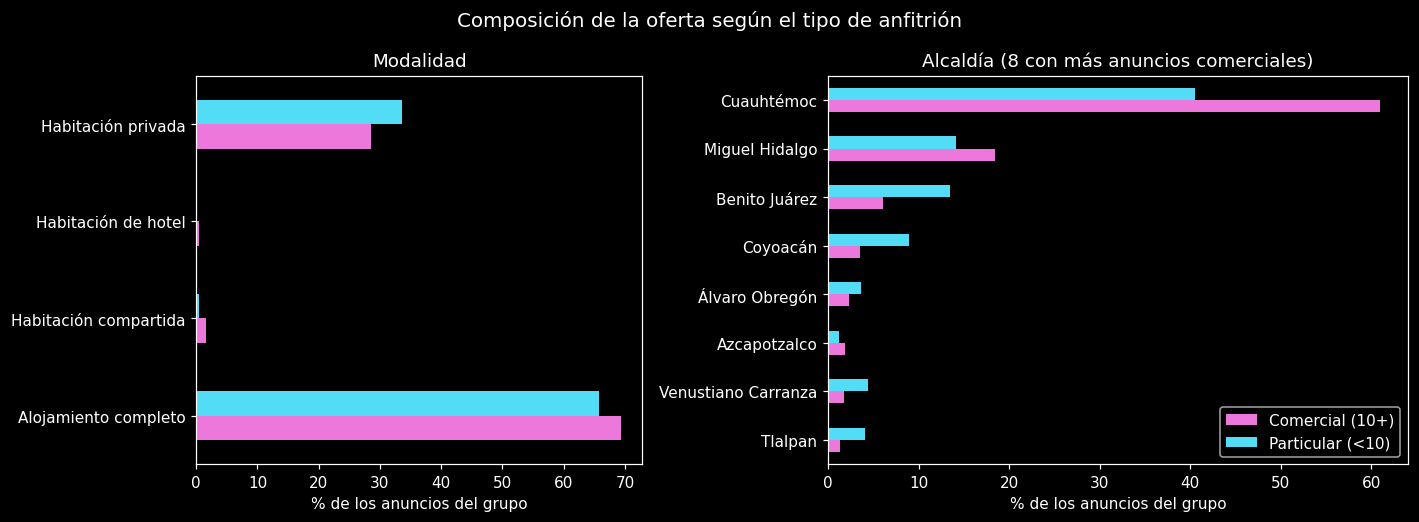

In [ ]:
mod = pd.crosstab(analisis["grupo_anfitrion"], analisis["modalidad"], normalize="index").mul(100)
ubic = pd.crosstab(analisis["alcaldia"], analisis["grupo_anfitrion"], normalize="columns").mul(100)
top_ubic = ubic.sort_values(COM, ascending=False).head(8)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})

mod.T.plot.barh(ax=axes[0], color=[COLORES[g] for g in mod.index])
axes[0].set(title="Modalidad", xlabel="% de los anuncios del grupo", ylabel="")
axes[0].get_legend().remove()

top_ubic[::-1].plot.barh(ax=axes[1], color=[COLORES[g] for g in top_ubic.columns])
axes[1].set(title="Alcaldía (8 con más anuncios comerciales)",
            xlabel="% de los anuncios del grupo", ylabel="")
axes[1].legend(title="")

fig.suptitle("Composición de la oferta según el tipo de anfitrión", fontsize=13)
plt.tight_layout()
plt.show()

Los anuncios de ambos tipos de anfitrión tienen una mezcla de modalidades muy parecida,
cerca de dos tercios son alojamientos completos (69.4 % de los anuncios de anfitriones
comerciales y 65.8 % de los de anfitriones particulares) y casi un tercio son
habitaciones privadas. La diferencia está en la **ubicación** pues el 61 % de los anuncios de
anfitriones comerciales está en Cuauhtémoc y el 18.4 % en Miguel Hidalgo (casi 80 % entre
ambas), frente al 55 % de los anuncios de anfitriones particulares. En cambio, los
anuncios de anfitriones particulares tienen mayor presencia en Benito Juárez, Coyoacán,
Tlalpan y Venustiano Carranza.

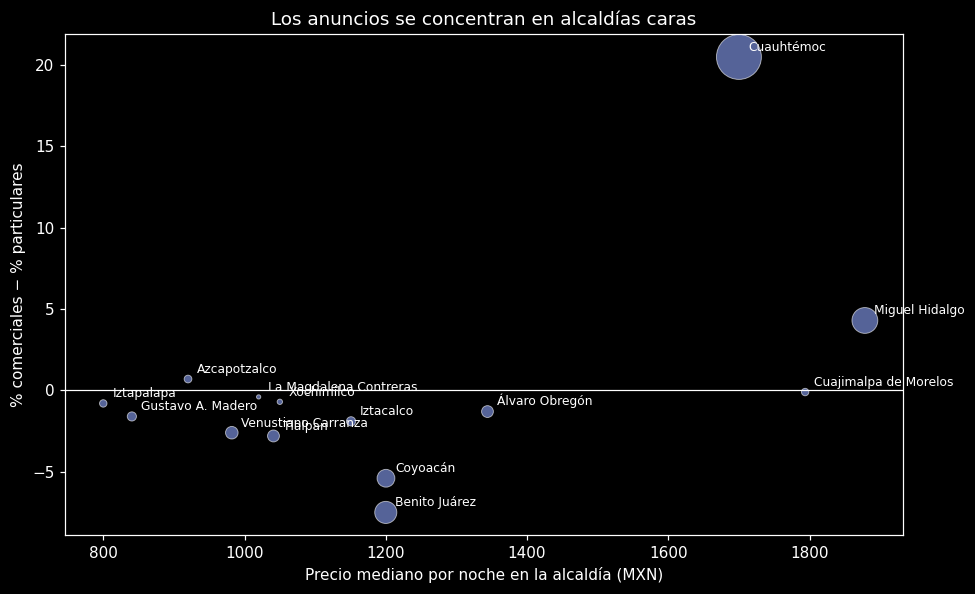

,anuncios,precio_mediano,Comercial_menos_particular
alcaldia,,,
Miguel Hidalgo,4287,"1,878.33",4.30
Cuajimalpa de Morelos,354,"1,793.73",-0.10
Cuauhtémoc,12975,"1,700.00",20.50
Álvaro Obregón,901,"1,344.00",-1.30
Coyoacán,2032,"1,200.25",-5.40
Benito Juárez,3136,"1,200.00",-7.50
Iztacalco,551,"1,150.80",-1.90
Xochimilco,185,"1,050.00",-0.70
Tlalpan,913,"1,041.00",-2.80


In [ ]:
precio_alc = analisis.groupby("alcaldia").agg(anuncios=("id", "count"),
                                              precio_mediano=("precio", "median"))
precio_alc["Comercial_menos_particular"] = (ubic[COM] - ubic[PAR]).round(1)
precio_alc = precio_alc[precio_alc["anuncios"] >= 100]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(precio_alc["precio_mediano"], precio_alc["Comercial_menos_particular"],
           s=precio_alc["anuncios"] / 15, color=COL["azul"], alpha=0.6, edgecolor="white", linewidth=0.6)
for nombre, fila in precio_alc.iterrows():
    ax.annotate(nombre, (fila["precio_mediano"], fila["Comercial_menos_particular"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.axhline(0, color="white", lw=0.8)
ax.set(title="Los anuncios se concentran en alcaldías caras",
       xlabel="Precio mediano por noche en la alcaldía (MXN)",
       ylabel="% comerciales − % particulares")
plt.tight_layout()
plt.show()

display(precio_alc.sort_values("precio_mediano", ascending=False))

Cada punto representa una alcaldía, y su tamaño indica el número de anuncios. El eje
vertical muestra la diferencia entre el porcentaje de anuncios de anfitriones comerciales
y el de anfitriones particulares que se ubican en cada alcaldía,  los puntos por arriba de
la línea son alcaldías con mayor peso en la oferta de los anfitriones comerciales.
Cuauhtémoc destaca pues tiene 20.5% puntos porcentuales más de los anuncios de anfitriones
comerciales que de los de particulares, y es una de las tres alcaldías más caras
(\$1,700). Miguel Hidalgo, la más cara (\$1,878), también queda por arriba de la línea. En
cambio, Benito Juárez y Coyoacán (\$1,200) tienen mayor peso en la oferta de los
anfitriones particulares. Por lo tanto, **parte del 21 % de diferencia inicial podría
deberse a la ubicación** de los anuncios y no al tipo de anfitrión. Excluimos Milpa Alta y
Tláhuac por tener menos de 100 anuncios.

#### 4.5.2 Comparación dentro de cada alcaldía y modalidad

Solo comparamos combinaciones con al menos 30 anuncios de cada tipo de anfitrión. Este
umbral es una regla práctica, con menos anuncios, la mediana depende de muy pocos
precios y es poco estable, mientras que un umbral más alto eliminaría la mayoría de las
alcaldías y limitaría la comparación a las zonas centrales.

In [ ]:
MIN_N = 30
claves = ["alcaldia", "modalidad"]

n = analisis.pivot_table(index=claves, columns="grupo_anfitrion", values="precio",
                         aggfunc="count", fill_value=0)
med = analisis.pivot_table(index=claves, columns="grupo_anfitrion", values="precio",
                           aggfunc="median")

estratos = pd.DataFrame({
    "n_comercial": n[COM],
    "n_particular": n[PAR],
    "mediana_comercial": med[COM],
    "mediana_particular": med[PAR],
})
estratos = estratos[(estratos["n_comercial"] >= MIN_N) & (estratos["n_particular"] >= MIN_N)]
estratos["diferencia_%"] = ((estratos["mediana_comercial"] / estratos["mediana_particular"] - 1) * 100).round(1)
estratos["peso"] = estratos["n_comercial"] + estratos["n_particular"]
estratos = estratos.sort_values("diferencia_%", ascending=False)

ponderada = np.average(estratos["diferencia_%"], weights=estratos["peso"])

display(estratos)
print(f"Combinaciones comparables: {len(estratos)}")
print(f"Anfitriones comerciales más caros en: {(estratos['diferencia_%'] > 0).sum()} | más baratos en: {(estratos['diferencia_%'] < 0).sum()}")
print(f"Diferencia mediana: {estratos['diferencia_%'].median():.1f}%")
print(f"Diferencia promedio ponderada por anuncios: {ponderada:.1f}%")

n_comercial  n_particular  \
alcaldia              modalidad                                          
Azcapotzalco          Habitación privada              45            87   
Coyoacán              Habitación privada             151           843   
Álvaro Obregón        Habitación privada              53           340   
Tlalpan               Habitación privada              79           418   
Gustavo A. Madero     Habitación privada              42           203   
Benito Juárez         Alojamiento completo           321          1525   
Miguel Hidalgo        Alojamiento completo          1198          1972   
                      Habitación privada             318           768   
Benito Juárez         Habitación privada             181          1093   
Cuauhtémoc            Alojamiento completo          3653          5899   
Coyoacán              Alojamiento completo           137           892   
Cuauhtémoc            Habitación privada            1281          1928   
Iztacalco             Habitación privada              41           172   
Álvaro Obregón        Alojamiento completo           141           363   
Iztapalapa            Habitación privada              41           116   
Cuauhtémoc            Habitación compartida          116            52   
Cuajimalpa de Morelos Alojamiento completo            88           166   
Venustiano Carranza   Alojamiento completo            38           528   
                      Habitación privada             112           325   
Azcapotzalco          Alojamiento completo           109           138   

                                             mediana_comercial  \
alcaldia              modalidad                                  
Azcapotzalco          Habitación privada                900.00   
Coyoacán              Habitación privada              1,019.70   
Álvaro Obregón        Habitación privada              1,063.00   
Tlalpan               Habitación privada                881.00   
Gustavo A. Madero     Habitación privada                687.00   
Benito Juárez         Alojamiento completo            1,781.00   
Miguel Hidalgo        Alojamiento completo            2,412.93   
                      Habitación privada              1,069.16   
Benito Juárez         Habitación privada                841.00   
Cuauhtémoc            Alojamiento completo            2,069.50   
Coyoacán              Alojamiento completo            1,691.10   
Cuauhtémoc            Habitación privada                980.00   
Iztacalco             Habitación privada                835.00   
Álvaro Obregón        Alojamiento completo            1,590.10   
Iztapalapa            Habitación privada                644.00   
Cuauhtémoc            Habitación compartida             374.62   
Cuajimalpa de Morelos Alojamiento completo            1,902.45   
Venustiano Carranza   Alojamiento completo            1,113.81   
                      Habitación privada                668.00   
Azcapotzalco          Alojamiento completo              650.00   

                                             mediana_particular  diferencia_%  \
alcaldia              modalidad                                                 
Azcapotzalco          Habitación privada                 600.00         50.00   
Coyoacán              Habitación privada                 808.00         26.20   
Álvaro Obregón        Habitación privada                 858.71         23.80   
Tlalpan               Habitación privada                 745.50         18.20   
Gustavo A. Madero     Habitación privada                 588.00         16.80   
Benito Juárez         Alojamiento completo             1,549.00         15.00   
Miguel Hidalgo        Alojamiento completo             2,108.40         14.40   
                      Habitación privada                 936.16         14.20   
Benito Juárez         Habitación privada                 752.86         11.70   
Cuauhtémoc            Alojamiento completo             1,862.00         

Combinaciones comparables: 20
Anfitriones comerciales más caros en: 13 | más baratos en: 7
Diferencia mediana: 9.1%
Diferencia promedio ponderada por anuncios: 10.1%


De todas las combinaciones de alcaldía y modalidad, 20 cuentan con al menos 30 anuncios
de cada tipo de anfitrión y pueden compararse. En cada una calculamos la diferencia
porcentual entre el precio mediano de los anuncios de anfitriones comerciales y el de los
anuncios de particulares. En 13 de las 20 combinaciones los anuncios de anfitriones
comerciales son más caros, y en las 7 restantes, más baratos.

Para resumir estas 20 diferencias usamos dos medidas.

* La **mediana** (9.1 %) indica que, en la combinación típica, los anuncios de anfitriones comerciales cuestan alrededor de 9 % más que los de particulares, al tomar el valor central, no se ve afectada por los
casos extremos, como los de Azcapotzalco.
* La **media ponderada** por número de anuncios
(10.1 %) da más peso a las combinaciones con más oferta, como Cuauhtémoc y Miguel
Hidalgo, e indica que, considerando dónde se concentran los anuncios, los de anfitriones
comerciales cuestan en promedio alrededor de 10 % más que los de particulares en la misma
alcaldía y modalidad. Que ambas medidas sean tan cercanas muestra que el resultado es
consistente en las combinaciones pequeñas y en las grandes. En cualquier caso, la
diferencia es menos de la mitad del 21 % observado en la comparación directa.

**Nota**: Que la mediana de las diferencias (9.1 %) y la media ponderada (10.1 %) sean tan
cercanas fortalece el resultado. La media ponderada está dominada por las combinaciones
con más anuncios, como las de Cuauhtémoc y Miguel Hidalgo, mientras que la mediana trata
a todas por igual, si en las zonas con más oferta la diferencia fuera muy distinta a la
del resto, ambas medidas se alejarían. Además, ninguna de las dos se ve arrastrada por
los casos extremos, como los de Azcapotzalco, que quedan en los extremos de la mediana y
tienen muy poco peso en la media ponderada. Por ello, podemos afirmar que los anuncios de
anfitriones comerciales cuestan alrededor de 9 % a 10 % más que los de particulares en la
misma alcaldía y modalidad, aunque la diferencia varía considerablemente entre
combinaciones

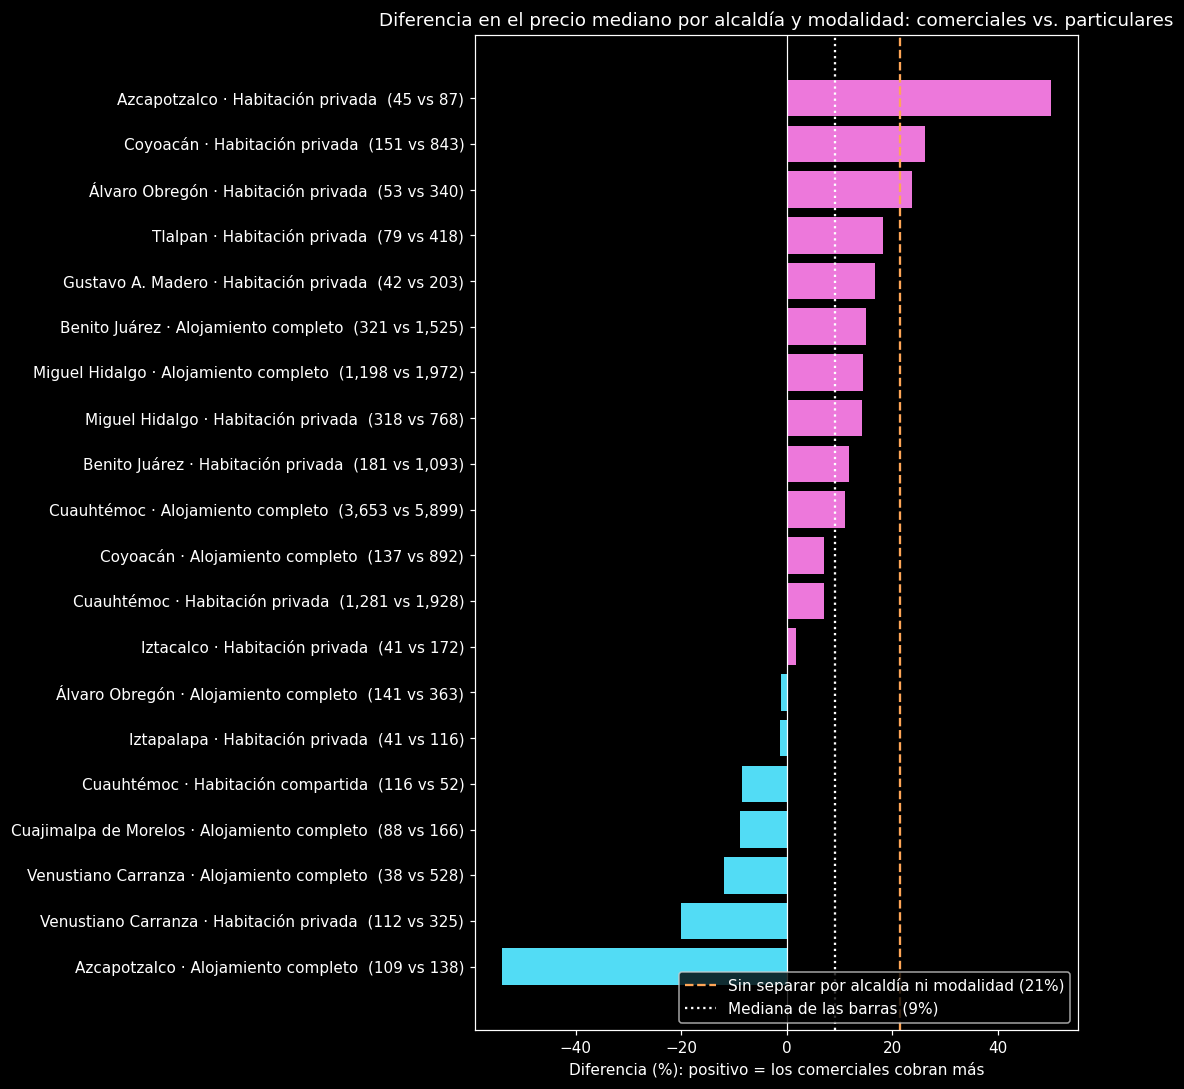

In [ ]:
est = estratos.sort_values("diferencia_%")
etiquetas = [f"{a} · {m}  ({int(c):,} vs {int(p):,})"
             for (a, m), c, p in zip(est.index, est["n_comercial"], est["n_particular"])]
colores = np.where(est["diferencia_%"] > 0, COLORES[COM], COLORES[PAR])
mediana_barras = est["diferencia_%"].median()

fig, ax = plt.subplots(figsize=(10, 0.4 * len(est) + 2))
ax.barh(etiquetas, est["diferencia_%"], color=colores)
ax.axvline(0, color="white", lw=0.8)
ax.axvline(diferencia_bruta, color=COL["naranja"], ls="--",
           label=f"Sin separar por alcaldía ni modalidad ({diferencia_bruta:.0f}%)")
ax.axvline(mediana_barras, color="white", ls=":",
           label=f"Mediana de las barras ({mediana_barras:.0f}%)")
ax.set(title="Diferencia en el precio mediano por alcaldía y modalidad: comerciales vs. particulares",
       xlabel="Diferencia (%): positivo = los comerciales cobran más")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Cada barra compara a ambos grupos dentro de una misma alcaldía y
modalidad (entre paréntesis, anuncios comerciales vs. particulares). Los comerciales
cobran más en 13 de las 20 combinaciones comparables, con una diferencia mediana de 9.1 %
 **menos de la mitad del 21 % inicial** (línea discontinua). La
ubicación explicaba buena parte de la brecha, aunque no toda.

En los segmentos con más comerciales la diferencia es moderada y consistente, entre 11 % y
15 % en alojamientos completos de Cuauhtémoc, Miguel Hidalgo y Benito Juárez, y 7 % en
habitaciones privadas de Cuauhtémoc. Las diferencias más extremas aparecen en grupos
pequeños, y en Venustiano Carranza y Cuajimalpa los comerciales cobran menos.

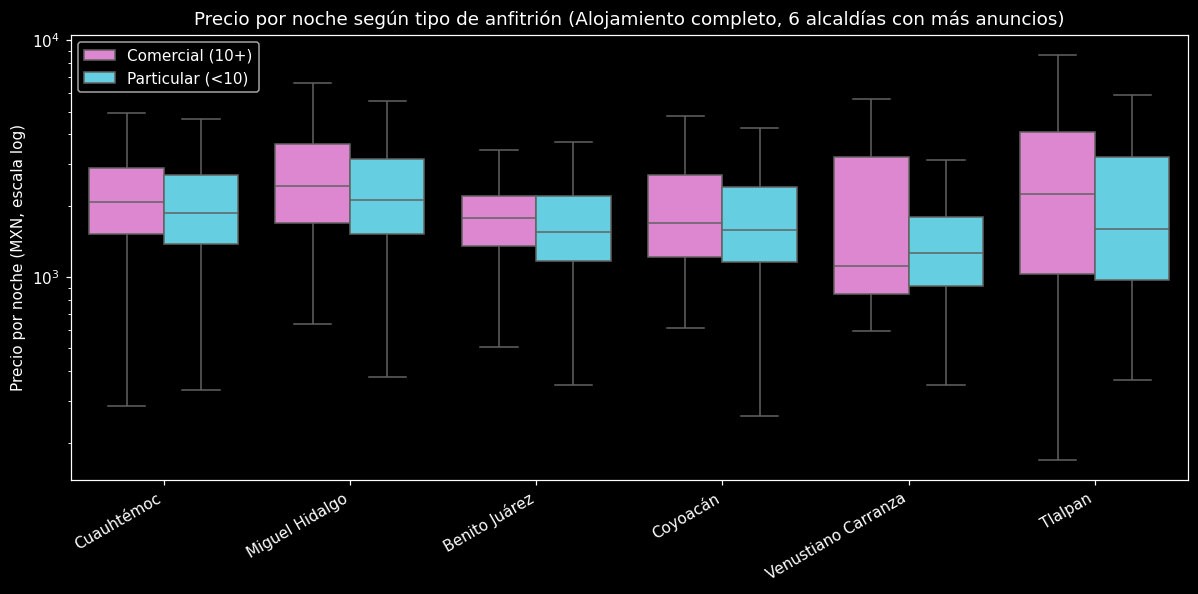

grupo_anfitrion,Comercial (10+),Particular (<10)
alcaldia,,
Cuauhtémoc,3653,5899
Miguel Hidalgo,1198,1972
Benito Juárez,321,1525
Coyoacán,137,892
Venustiano Carranza,38,528
Tlalpan,29,384


In [ ]:
modalidad_principal = analisis["modalidad"].mode()[0]
top_alcaldias = analisis["alcaldia"].value_counts().head(6).index
sub = analisis[(analisis["modalidad"] == modalidad_principal) &
               analisis["alcaldia"].isin(top_alcaldias)]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=sub, x="alcaldia", y="precio", hue="grupo_anfitrion",
            order=top_alcaldias, hue_order=[COM, PAR], palette=COLORES,
            showfliers=False, ax=ax)
ax.set_yscale("log")
ax.set(title=f"Precio por noche según tipo de anfitrión ({modalidad_principal}, 6 alcaldías con más anuncios)",
       xlabel="", ylabel="Precio por noche (MXN, escala log)")
ax.legend(title="")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

display(pd.crosstab(sub["alcaldia"], sub["grupo_anfitrion"]).loc[top_alcaldias])

En alojamientos completos, la mediana de los comerciales es algo mayor
en Cuauhtémoc, Miguel Hidalgo, Benito Juárez, Coyoacán y Tlalpan, y menor en Venustiano
Carranza, donde además sus precios son mucho más dispersos. Sin embargo, las cajas de
ambos grupos son casi iguales en todas las alcaldías, la diferencia está en el
precio típico, no en una separación clara, y muchos particulares cobran más que muchos
comerciales. En Tlalpan y Venustiano Carranza hay pocos alojamientos completos, por lo que esas comparaciones son menos confiables.

#### 4.5.3 Un caso atípico: Azcapotzalco

En Azcapotzalco, los comerciales cobran 50 % más en habitaciones privadas pero 54 % menos
en alojamientos completos. Revisamos qué anfitriones están detrás.

In [ ]:
azc = analisis[(analisis["alcaldia"] == "Azcapotzalco") &
               (analisis["grupo_anfitrion"] == COM) &
               (analisis["modalidad"] == modalidad_principal)]

por_anfitrion = (azc.groupby("host_id")
                    .agg(anuncios=("id", "count"), precio_mediano=("precio", "median"))
                    .sort_values("anuncios", ascending=False))
por_anfitrion["% de la oferta comercial"] = (por_anfitrion["anuncios"] / len(azc) * 100).round(1)
display(por_anfitrion.head(5))

,anuncios,precio_mediano,% de la oferta comercial
host_id,,,
348389387,68,650.00,62.40
51622893,15,"1,205.40",13.80
106186128,13,"1,335.00",11.90
374434784,10,699.95,9.20
302431514,2,"1,762.50",1.80


Un solo anfitrión comercial concentra 68 de los 109 alojamientos completos de
Azcapotzalco (62 %), con un precio mediano de $650. La diferencia de −54 % refleja la
estrategia de precios de ese operador y no un patrón general de los comerciales. Este
caso muestra que, con pocos anfitriones en un segmento, un solo operador puede
determinar el resultado.

#### 4.5.4 Respuesta a la pregunta

Los anfitriones comerciales cobran más que los particulares, pero mucho menos de lo que
sugiere una comparación directa. La diferencia inicial de 21 % se reduce a alrededor de
9 % al comparar dentro de la misma alcaldía y modalidad, porque buena parte se debía a
que los anuncios de anfitriones comerciales se ubican principalmente en Cuauhtémoc y
Miguel Hidalgo, dos de las alcaldías más caras. La diferencia que permanece se observa
sobre todo en los alojamientos completos de las alcaldías centrales. Además, los precios
de ambos grupos cubren rangos muy similares, por lo que muchos anuncios de particulares
son más caros que muchos de anfitriones comerciales, y hay excepciones, como
Azcapotzalco, donde un solo anfitrión con precios bajos invierte el resultado.

Estos resultados describen una asociación, no un efecto
causal ya que los datos no permiten saber si los comerciales cobran más por ser comerciales o
por diferencias no observadas en sus alojamientos (amenidades, calidad, servicios).
Además, el grupo comercial depende de pocos operadores, y el precio analizado es el
publicado en la fecha de la captura, no el efectivamente pagado.

## 5. Interpretación y conclusiones




### 5.1. Principales hallazgos

Nuestra pregunta general fue cómo se relaciona la ubicación de los alojamientos con su precio anunciado y cómo cambia esa relación según las características del alojamiento y del anfitrión. Trabajamos con 27,820 anuncios activos de la captura del 23 de septiembre de 2026.

1. **Distribución y tipo de alojamiento (4.1).** El precio se concentra en valores bajos con una cola de anuncios muy caros, y el tipo de alojamiento es la diferencia más clara. Por alcaldía, en las 16 el alojamiento completo es más caro que la habitación privada. Las alcaldías del centro y poniente son las más caras, y también las que concentran la oferta. Las de la periferia son más baratas y con menos anuncios. Ademas, la ubicación pesa más en los alojamientos completos que en las habitaciones."



2. **Distancia al centro (4.2).** Alejarse del Zócalo apenas mueve el precio (correlaciones muy débiles, incluso acotando al 92.7 % central). Importa más la orientación: el Poniente supera en 53.7 % en mediana al Oriente, y en el Norponiente el precio crece con la distancia.

3. **Características del alojamiento (4.3).** El precio se relaciona sobre todo con la modalidad y el tamaño. El precio total crece con la capacidad (de \$1,500 para dos huéspedes a \$3,408 para ocho), pero el precio por huésped baja de \$750 a alrededor de \$400. Recámaras (0.46) y capacidad (0.43) tienen una correlación moderada con el precio.

4. **Calificación (4.4).** La asociación entre precio y calificación es positiva pero débil (Spearman de 0.15) y crece cuando la calificación está respaldada por más reseñas (0.25 con 92 reseñas o más). El patrón se repite en las alcaldías grandes, pero no en todas: en Álvaro Obregón no hay asociación.

5. **Tipo de anfitrión (4.5).** Los anfitriones comerciales (10 anuncios o más) cobran 21 % más en mediana, pero al comparar dentro de la misma alcaldía y modalidad la diferencia baja a cerca de 10 %. La mayor parte de la brecha se explicaba porque los comerciales se concentran en Cuauhtémoc y Miguel Hidalgo.

En conjunto, **la ubicación sí se asocia con el precio, pero no a través de la distancia al centro sino de la zona**: las alcaldías centrales y del poniente son más caras. Esa diferencia convive con otras del mismo orden: la modalidad y el tamaño del alojamiento pesan tanto como la ubicación, y el tipo de anfitrión añade una diferencia menor una vez que se compara dentro de la misma zona.

### 5.2. Qué podemos afirmar y qué no

Podemos afirmar que existen diferencias sistemáticas en el precio anunciado entre zonas de la ciudad, tipos de alojamiento, tamaños y tipos de anfitrión, y que varias de ellas se mantienen al comparar grupos más parecidos (misma alcaldía y modalidad).

No podemos afirmar que la ubicación, el tamaño, la calificación o el tipo de anfitrión *causen* esas diferencias. Es un análisis descriptivo de datos observacionales: una asociación puede deberse a variables que no medimos, como la calidad del inmueble, las amenidades o la colonia exacta. Tampoco podemos hablar del precio que pagan los huéspedes ni de cuántas noches se rentan, porque el precio es el que publica el anfitrión.

### 5.3. Consideraciones

- **Precio publicado, no pagado.** Es la tarifa vigente en la fecha de la captura; no refleja descuentos, temporadas ni el precio final.
- **Una sola fecha.** Los resultados describen la oferta de septiembre de 2026 y pueden cambiar en otra temporada.
- **Oferta activa.** Excluimos los anuncios recuperados de capturas anteriores y los anuncios sin precio, así que las conclusiones se refieren a la oferta vigente.
- **Ubicación aproximada.** Inside Airbnb desplaza las coordenadas hasta 150 m, y la alcaldía es una unidad muy grande que mezcla colonias muy distintas.
- **Medir al centro.** Medir distancias geodésicas en línea recta respecto a un único punto de referencia (Zócalo), no incorpora tiempos de traslado vial ni distancias a subcentros económicos múltiples.
- **Umbrales elegidos por nosotros.** El criterio de 3 × IQR para precios no creíbles, el mínimo de 30 anuncios por grupo y el 1 % para agrupar tipos de propiedad son decisiones razonables, pero otros umbrales moverían ligeramente los números.
- **Calificaciones concentradas.** La mitad de los anuncios tiene 4.84 o más, lo que limita la capacidad de la calificación para distinguir entre alojamientos.
- **Anfitrión Comercial/Particular.** No existe un umbral estándar para definir a un anfitrión comercial, la
literatura ha usado desde 2 hasta 20 anuncios. Seguimos a Ke (2017), quien examina
umbrales de 10 y 20 anuncios para identificar a operadores de gran escala, por lo que
nuestro umbral es una decisión metodológica y no una frontera natural.

### 5.4. Líneas de análisis futuras

- Usar la colonia o una malla geográfica en lugar de la alcaldía, y medir la distancia a varios centros económicos (Polanco, Santa Fe, Roma–Condesa) en lugar de solo al Zócalo.
- Comparar varias capturas para estudiar la estacionalidad del precio.
- Ajustar un modelo que considere a la vez ubicación, modalidad, tamaño y tipo de anfitrión, para separar la contribución de cada uno.
- Incorporar amenidades y el texto de los anuncios, que dejamos fuera por requerir otras técnicas.


## Referencias

- Inside Airbnb. *Get the Data: Mexico City, 23 September 2026*. https://insideairbnb.com/get-the-data/ (licencia Creative Commons Attribution 4.0).
- Inside Airbnb. *Data Dictionary*. https://insideairbnb.com/data-assumptions/
- INEGI. *Aspectos geográficos de la Ciudad de México*. https://inegi.org.mx
- Rentals United. *Step 5: Price and availability*. https://docs.rentalsunited.com/hc/en-gb/articles/34003672254109-Step-5-Price-and-availability
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
- Ke, Q. (2017). *Sharing Means Renting? An Entire-marketplace Analysis of
Airbnb*. arXiv:1701.01645. https://arxiv.org/abs/1701.01645